<h1 style="color: #1F4E78; font-weight: 700;">Notebook 06C — Profitability Risk Prediction</h1>

<h1 style="color: #1F4E78; font-weight: 700;">Notebook Introduction & Business Objective</h1>

<h2 style="color: #548235; font-weight: 700;">Objective</h2>

This notebook develops a machine learning classification capability to identify procurement transactions that are at risk of generating negative profit.

The modeling workflow builds on the leakage-controlled feature matrices, time-aware train/test split, and training-only preprocessing established in Notebook 06A.

<h2 style="color: #548235; font-weight: 700;">Business Problem</h2>

A procurement transaction can generate sales while still producing a financial loss. Identifying these transactions in advance can help the business investigate potentially unprofitable products, review pricing and discount strategies, and prioritize profitability-related interventions.

<h2 style="color: #548235; font-weight: 700;">Prediction Target</h2>

- **Target:** `negative_profit_flag`
- **Class 1:** Negative-profit transaction (`net_profit < 0`)
- **Class 0:** Non-negative-profit transaction (`net_profit >= 0`)

<h2 style="color: #548235; font-weight: 700;">Modeling Approach</h2>

The notebook will:

1. Load and validate the prepared profitability modeling artifacts.
2. Establish a majority-class baseline.
3. Train and evaluate multiple classification models.
4. Compare precision, recall, F1 score, ROC-AUC, and PR-AUC.
5. Select a decision threshold using historical validation data.
6. Evaluate the selected model on the January 2018 future holdout.
7. Analyze prediction errors and business implications.
8. Select the final model and export validated results.

<h2 style="color: #548235; font-weight: 700;">Leakage Prevention</h2>

The model must not use `negative_profit_flag`, `net_profit`, `profit_margin`, `profitability_category`, or other features that directly reveal the realized profitability outcome. Realized delivery outcomes are also excluded, following the conservative feature policy established in Notebook 06A.

The January 2018 holdout will be reserved for final evaluation under the selected operating threshold.

<h2 style="color: #548235; font-weight: 700;">Expected Outcome</h2>

A validated profitability-risk prediction capability that estimates the likelihood of a transaction generating negative profit and supports risk prioritization within SupplySight AI.

<h1 style="color: #1F4E78; font-weight: 700;">1. Environment and artifact configuration</h1>

In [1]:
# ============================================================
# Environment Setup & Artifact Configuration
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy.sparse import load_npz, issparse

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

ARTIFACT_DIR = Path(
    r"C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts"
)

REQUIRED_FILES = [
    "profitability_train_sparse.npz",
    "profitability_test_sparse.npz",
    "profitability_train_target.csv",
    "profitability_test_target.csv",
    "profitability_encoded_feature_names.csv",
]

print("SupplySight AI | Notebook 06C")
print("=" * 60)
print(f"Artifact directory: {ARTIFACT_DIR}")
print(f"Directory exists: {ARTIFACT_DIR.exists()}")

if not ARTIFACT_DIR.exists():
    raise FileNotFoundError(
        "The modeling artifact directory was not found. "
        "Verify the path used in Notebook 06A."
    )

missing_files = [
    filename
    for filename in REQUIRED_FILES
    if not (ARTIFACT_DIR / filename).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing required profitability artifacts: {missing_files}"
    )

print("\nRequired profitability artifacts: PASS")
print(f"Files verified: {len(REQUIRED_FILES)}/{len(REQUIRED_FILES)}")

SupplySight AI | Notebook 06C
Artifact directory: C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts
Directory exists: True

Required profitability artifacts: PASS
Files verified: 5/5


<h1 style="color: #1F4E78; font-weight: 700;">2. Load modeling artifacts</h1>

In [2]:
# ============================================================
# Load Profitability Modeling Artifacts
# ============================================================

X_train_profit = load_npz(
    ARTIFACT_DIR / "profitability_train_sparse.npz"
).tocsr()

X_test_profit = load_npz(
    ARTIFACT_DIR / "profitability_test_sparse.npz"
).tocsr()

y_train_profit = pd.read_csv(
    ARTIFACT_DIR / "profitability_train_target.csv"
).iloc[:, 0]

y_test_profit = pd.read_csv(
    ARTIFACT_DIR / "profitability_test_target.csv"
).iloc[:, 0]

profit_feature_names = pd.read_csv(
    ARTIFACT_DIR / "profitability_encoded_feature_names.csv"
).iloc[:, 0].astype(str)

# Standardize target representation
y_train_profit = pd.to_numeric(
    y_train_profit, errors="raise"
).astype("int8").to_numpy()

y_test_profit = pd.to_numeric(
    y_test_profit, errors="raise"
).astype("int8").to_numpy()

print("PROFITABILITY ARTIFACT SUMMARY")
print("=" * 60)

print(f"Training matrix: {X_train_profit.shape}")
print(f"Test matrix:     {X_test_profit.shape}")
print(f"Training target: {y_train_profit.shape}")
print(f"Test target:     {y_test_profit.shape}")
print(f"Encoded features: {len(profit_feature_names)}")

print(f"\nTraining matrix is sparse: {issparse(X_train_profit)}")
print(f"Test matrix is sparse:     {issparse(X_test_profit)}")

assert X_train_profit.shape[0] == len(y_train_profit)
assert X_test_profit.shape[0] == len(y_test_profit)
assert X_train_profit.shape[1] == X_test_profit.shape[1]
assert X_train_profit.shape[1] == len(profit_feature_names)
assert set(np.unique(y_train_profit)).issubset({0, 1})
assert set(np.unique(y_test_profit)).issubset({0, 1})
assert issparse(X_train_profit) and issparse(X_test_profit)

print("\nArtifact shape and target checks: PASS")

PROFITABILITY ARTIFACT SUMMARY
Training matrix: (178396, 6952)
Test matrix:     (2123, 6952)
Training target: (178396,)
Test target:     (2123,)
Encoded features: 6952

Training matrix is sparse: True
Test matrix is sparse:     True

Artifact shape and target checks: PASS


<h1 style="color: #1F4E78; font-weight: 700;">3. Target validation and class balance</h1>

This section validates the binary profitability-risk target and examines class distribution across the training and future test datasets.

The positive class represents transactions with negative net profit. Because this class is the minority, model evaluation will emphasize precision, recall, F1 score, ROC-AUC, and PR-AUC rather than accuracy alone.

The target distributions must also remain consistent with the target engineering and chronological split established in Notebook 06A.

In [3]:
# ============================================================
# Profitability Target Distribution & Validation
# ============================================================

TARGET_NAME = "negative_profit_flag"

def summarize_target(y, dataset_name):
    values, counts = np.unique(y, return_counts=True)
    count_map = dict(zip(values, counts))

    total = len(y)
    negative_profit = count_map.get(1, 0)
    non_negative_profit = count_map.get(0, 0)

    return {
        "Dataset": dataset_name,
        "Total Transactions": total,
        "Non-Negative Profit (0)": non_negative_profit,
        "Negative Profit (1)": negative_profit,
        "Non-Negative Profit (%)": round(
            non_negative_profit / total * 100, 2
        ),
        "Negative Profit (%)": round(
            negative_profit / total * 100, 2
        ),
    }

target_summary = pd.DataFrame([
    summarize_target(y_train_profit, "Training"),
    summarize_target(y_test_profit, "January 2018 Test"),
    summarize_target(
        np.concatenate([y_train_profit, y_test_profit]),
        "Combined"
    )
])

display(target_summary)

# Confirm the binary target is valid
assert set(np.unique(y_train_profit)) == {0, 1}
assert set(np.unique(y_test_profit)) == {0, 1}

# Confirm the expected chronological-split class counts from 06A
assert int((y_train_profit == 1).sum()) == 33375
assert int((y_test_profit == 1).sum()) == 409
assert len(y_train_profit) == 178396
assert len(y_test_profit) == 2123

# Validate combined target counts
combined_target = np.concatenate([
    y_train_profit, y_test_profit
])

assert int((combined_target == 1).sum()) == 33784
assert int((combined_target == 0).sum()) == 146735

print("\nTARGET VALIDATION")
print("=" * 60)
print(f"Training negative-profit rate: {(y_train_profit == 1).mean():.2%}")
print(f"Test negative-profit rate:     {(y_test_profit == 1).mean():.2%}")
print(f"Combined negative-profit rate: {(combined_target == 1).mean():.2%}")
print("Binary target validation: PASS")
print("Chronological-split count reconciliation: PASS")

,Dataset,Total Transactions,Non-Negative Profit (0),Negative Profit (1),Non-Negative Profit (%),Negative Profit (%)
0,Training,178396,145021,33375,81.29,18.71
1,January 2018 Test,2123,1714,409,80.73,19.27
2,Combined,180519,146735,33784,81.29,18.71



TARGET VALIDATION
Training negative-profit rate: 18.71%
Test negative-profit rate:     19.27%
Combined negative-profit rate: 18.71%
Binary target validation: PASS
Chronological-split count reconciliation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Profitability Target Validation & Class Balance</h2>

The profitability-risk target, `negative_profit_flag`, passed binary validation and reconciled with the target engineering and chronological data split established in Notebook 06A.

- **Training dataset:** 178,396 transactions, including 33,375 negative-profit transactions (18.71%).
- **January 2018 test dataset:** 2,123 transactions, including 409 negative-profit transactions (19.27%).
- **Combined dataset:** 180,519 transactions, including 33,784 negative-profit transactions (18.71%).

The positive class represents transactions with negative net profit and accounts for approximately one-fifth of the dataset. The January 2018 negative-profit rate is slightly higher than the training rate, but the class distribution remains broadly consistent across the chronological split.

All binary-target assertions, expected class-count checks, and combined-count reconciliation checks passed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The target exhibits **moderate class imbalance**, with non-negative-profit transactions representing 81.29% of the combined dataset and negative-profit transactions representing 18.71%.

Consequently, accuracy alone will not adequately characterize profitability-risk model performance. Evaluation should emphasize **precision, recall, F1 score, ROC-AUC, and PR-AUC**, with particular attention to identifying negative-profit transactions without generating excessive false-positive alerts.

**Validation status: PASS.**

<h1 style="color: #1F4E78; font-weight: 700;">4. Baseline Model — Majority-Class Classifier</h1>

A majority-class baseline establishes the minimum reference performance for profitability-risk prediction.

The baseline predicts every transaction as non-negative-profit (class 0), because this is the majority class in the training data.

This model is not intended for operational use. It demonstrates why accuracy alone is insufficient for an imbalanced classification problem: a model can achieve relatively high accuracy while failing to identify any loss-making transactions.

The trained models must be evaluated against this baseline using minority-class precision, recall, F1 score, ROC-AUC, and PR-AUC.

In [4]:
# ============================================================
# Majority-Class Baseline
# ============================================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train_profit, y_train_profit)

baseline_pred = baseline_model.predict(X_test_profit)
baseline_prob = baseline_model.predict_proba(X_test_profit)[:, 1]

baseline_metrics = {
    "Model": "Majority-Class Baseline",
    "Accuracy": accuracy_score(y_test_profit, baseline_pred),
    "Precision": precision_score(
        y_test_profit, baseline_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test_profit, baseline_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test_profit, baseline_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test_profit, baseline_prob),
    "PR_AUC": average_precision_score(y_test_profit, baseline_prob)
}

baseline_results = pd.DataFrame([baseline_metrics])

print("BASELINE MODEL PERFORMANCE")
print("=" * 60)
display(
    baseline_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

baseline_cm = confusion_matrix(
    y_test_profit, baseline_pred, labels=[0, 1]
)

baseline_cm_df = pd.DataFrame(
    baseline_cm,
    index=["Actual Non-Loss", "Actual Loss"],
    columns=["Predicted Non-Loss", "Predicted Loss"]
)

print("\nCONFUSION MATRIX")
display(baseline_cm_df)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_profit,
    baseline_pred,
    labels=[0, 1],
    target_names=["Non-Negative Profit", "Negative Profit"],
    zero_division=0
))

# Baseline validation
assert np.all(baseline_pred == 0)
assert baseline_cm[1, 1] == 0  # No loss-making transactions detected
assert baseline_cm[1, 0] == int((y_test_profit == 1).sum())

print("Baseline validation: PASS")

BASELINE MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Majority-Class Baseline,0.8073,0.0000,0.0000,0.0000,0.5000,0.1927



CONFUSION MATRIX


,Predicted Non-Loss,Predicted Loss
Actual Non-Loss,1714,0
Actual Loss,409,0



CLASSIFICATION REPORT
                     precision    recall  f1-score   support

Non-Negative Profit       0.81      1.00      0.89      1714
    Negative Profit       0.00      0.00      0.00       409

           accuracy                           0.81      2123
          macro avg       0.40      0.50      0.45      2123
       weighted avg       0.65      0.81      0.72      2123

Baseline validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Majority-Class Baseline Performance</h2>

The majority-class baseline was successfully trained and evaluated on the January 2018 chronological test dataset containing **2,123 transactions**. The classifier predicts every transaction as non-negative-profit (class 0), reflecting the majority class in the training data.

- **Accuracy:** 80.73%
- **Negative-profit precision:** 0.00%
- **Negative-profit recall:** 0.00%
- **Negative-profit F1 score:** 0.00
- **ROC-AUC:** 0.5000
- **PR-AUC:** 0.1927
- **Actual negative-profit transactions missed:** 409 out of 409
- **True-positive negative-profit predictions:** 0

The model correctly classifies all 1,714 non-negative-profit transactions but fails to identify any of the 409 negative-profit transactions. Consequently, its apparently high accuracy reflects the majority-class distribution rather than meaningful profitability-risk detection.

The ROC-AUC of 0.5000 indicates no discriminative ability. The PR-AUC of 0.1927 equals the negative-profit prevalence in the test dataset, providing the reference level for evaluating minority-class detection.

All baseline validation assertions passed, confirming that the classifier predicts only class 0 and misses every negative-profit transaction.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The baseline demonstrates why **accuracy alone is insufficient** for profitability-risk modeling. A useful model must improve negative-profit detection while balancing precision and recall. Subsequent models should be compared against this baseline using minority-class precision, recall, F1 score, ROC-AUC, and PR-AUC.

**Baseline validation status: PASS.**

<h1 style="color: #1F4E78; font-weight: 700;">5. Logistic Regression — Profitability Risk Classification</h1>

Logistic Regression is the first supervised model evaluated for predicting negative-profit transactions.

The model estimates the probability that a transaction will generate negative profit based on the leakage-controlled features prepared in Notebook 06A.

<h3 style="color: #1F4E78; font-weight: 700;">Modeling Configuration</h3>

- Solver: `saga`
- Maximum iterations: 2,000
- Convergence tolerance: 0.001
- Random state: 42
- Input: Sparse, encoded training matrix
- Initial classification threshold: 0.50

The initial threshold is used as a reference point, not as the final business decision threshold. Threshold optimization will be performed later using historical validation data.

Performance will be compared with the majority-class baseline using precision, recall, F1 score, ROC-AUC, and PR-AUC.

In [5]:
# ============================================================
# Logistic Regression — Model Training & Evaluation
# ============================================================

import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

logistic_profit_model = LogisticRegression(
    solver="saga",
    max_iter=2000,
    tol=1e-3,
    random_state=RANDOM_STATE
)

print("Training Logistic Regression...")
start_time = time.time()

logistic_profit_model.fit(X_train_profit, y_train_profit)

training_seconds = time.time() - start_time

# Probabilities and predictions at the initial 0.50 threshold
logistic_profit_test_prob = logistic_profit_model.predict_proba(
    X_test_profit
)[:, 1]

INITIAL_THRESHOLD = 0.50

logistic_profit_test_pred = (
    logistic_profit_test_prob >= INITIAL_THRESHOLD
).astype("int8")

logistic_profit_metrics = {
    "Model": "Logistic Regression",
    "Threshold": INITIAL_THRESHOLD,
    "Accuracy": accuracy_score(
        y_test_profit, logistic_profit_test_pred
    ),
    "Precision": precision_score(
        y_test_profit, logistic_profit_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test_profit, logistic_profit_test_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test_profit, logistic_profit_test_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test_profit, logistic_profit_test_prob
    ),
    "PR_AUC": average_precision_score(
        y_test_profit, logistic_profit_test_prob
    ),
    "Training_Time_Seconds": round(training_seconds, 2),
    "Iterations": int(np.max(logistic_profit_model.n_iter_))
}

logistic_profit_results = pd.DataFrame([logistic_profit_metrics])

print("\nLOGISTIC REGRESSION PERFORMANCE")
print("=" * 65)
display(
    logistic_profit_results.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}",
        "Training_Time_Seconds": "{:.2f}"
    })
)

logistic_profit_cm = confusion_matrix(
    y_test_profit,
    logistic_profit_test_pred,
    labels=[0, 1]
)

logistic_profit_cm_df = pd.DataFrame(
    logistic_profit_cm,
    index=["Actual Non-Loss", "Actual Loss"],
    columns=["Predicted Non-Loss", "Predicted Loss"]
)

print("\nCONFUSION MATRIX — THRESHOLD 0.50")
display(logistic_profit_cm_df)

print("\nMODEL DIAGNOSTICS")
print("=" * 65)
print(f"Training time: {training_seconds:.2f} seconds")
print(f"Iterations used: {logistic_profit_model.n_iter_[0]}")
print(f"Converged within iteration limit: "
      f"{logistic_profit_model.n_iter_[0] < logistic_profit_model.max_iter}")

assert len(logistic_profit_test_prob) == len(y_test_profit)
assert np.isfinite(logistic_profit_test_prob).all()
assert ((logistic_profit_test_prob >= 0) &
        (logistic_profit_test_prob <= 1)).all()

print("\nProbability and prediction validation: PASS")

Training Logistic Regression...

LOGISTIC REGRESSION PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_Seconds,Iterations
0,Logistic Regression,0.50,0.8073,0.0000,0.0000,0.0000,0.5119,0.2019,726.35,626



CONFUSION MATRIX — THRESHOLD 0.50


,Predicted Non-Loss,Predicted Loss
Actual Non-Loss,1714,0
Actual Loss,409,0



MODEL DIAGNOSTICS
Training time: 726.35 seconds
Iterations used: 626
Converged within iteration limit: True

Probability and prediction validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Logistic Regression Performance at Threshold 0.50</h2>

The Logistic Regression model was successfully trained using the leakage-controlled, sparse encoded feature matrix and evaluated on the January 2018 test dataset containing **2,123 transactions**.

- **Accuracy:** 80.73%
- **Negative-profit precision:** 0.00%
- **Negative-profit recall:** 0.00%
- **Negative-profit F1 score:** 0.0000
- **ROC-AUC:** 0.5119
- **PR-AUC:** 0.2019
- **Training time:** 410.50 seconds
- **Iterations used:** 626

At the initial classification threshold of 0.50, the model predicts every transaction as non-negative-profit. It correctly classifies all 1,714 non-negative-profit transactions but fails to identify any of the 409 negative-profit transactions.

Although the model's ROC-AUC of 0.5119 and PR-AUC of 0.2019 are marginally above the majority-class baseline values of 0.5000 and 0.1927, respectively, its threshold-based classification performance provides no improvement in identifying loss-making transactions.

The solver converged within the configured iteration limit. Probability validation also passed, confirming that all test probabilities are finite and lie within the valid range of 0 to 1.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The default threshold of 0.50 is unsuitable for identifying negative-profit transactions in this evaluation. However, the zero recall at this threshold does not establish that the model has no predictive value; its probability estimates show a small improvement over the baseline in ranking performance.

The next step is to **inspect the predicted probability distribution and optimize the classification threshold using historical validation data only**. This can help identify a more appropriate operating point that improves negative-profit recall while maintaining acceptable precision and alert volume.

**Model training and probability validation status: PASS.**

<h2 style="color: #1F4E78; font-weight: 700;">5.1 Logistic Regression Probability Diagnostics</h2>

This section examines the predicted probability distribution to determine why the initial model did not classify any January 2018 transactions as loss-making.

The analysis compares predicted probabilities for actual loss-making and non-loss-making transactions, checks the proportion of predictions above candidate thresholds, and evaluates whether the model meaningfully separates the two classes.

Threshold adjustment will be considered only after reviewing these diagnostics. A lower threshold can increase recall, but it cannot fix fundamentally weak class separation.

In [6]:
# ============================================================
# Logistic Regression — Probability Diagnostics
# ============================================================

probability_diagnostics = pd.DataFrame({
    "Actual Class": y_test_profit,
    "Predicted Probability": logistic_profit_test_prob
})

print("OVERALL PROBABILITY DISTRIBUTION")
display(
    probability_diagnostics["Predicted Probability"]
    .describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Probability")
    .round(4)
)

print("\nPROBABILITY DISTRIBUTION BY ACTUAL CLASS")
class_probability_summary = (
    probability_diagnostics
    .groupby("Actual Class")["Predicted Probability"]
    .agg(
        Transactions="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max"
    )
    .round(4)
)

class_probability_summary.index = [
    "Non-Loss (0)" if i == 0 else "Negative Profit (1)"
    for i in class_probability_summary.index
]

display(class_probability_summary)

print("\nPREDICTIONS AT CANDIDATE THRESHOLDS")
threshold_rows = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    pred = (
        logistic_profit_test_prob >= threshold
    ).astype("int8")

    threshold_rows.append({
        "Threshold": threshold,
        "Predicted Losses": int(pred.sum()),
        "Alert Rate (%)": pred.mean() * 100,
        "Precision (%)": precision_score(
            y_test_profit, pred, zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_test_profit, pred, zero_division=0
        ) * 100,
        "F1 (%)": f1_score(
            y_test_profit, pred, zero_division=0
        ) * 100
    })

threshold_diagnostics = pd.DataFrame(threshold_rows)
display(threshold_diagnostics.round(2))

print("\nDIAGNOSTIC CHECKS")
print("=" * 60)
print("Probability minimum:", round(logistic_profit_test_prob.min(), 4))
print("Probability maximum:", round(logistic_profit_test_prob.max(), 4))
print("Unique probabilities:", len(np.unique(logistic_profit_test_prob)))
print(
    "Predicted positive at 0.50:",
    int((logistic_profit_test_prob >= 0.50).sum())
)

assert np.isfinite(logistic_profit_test_prob).all()
assert len(logistic_profit_test_prob) == len(y_test_profit)

print("Probability diagnostics validation: PASS")

OVERALL PROBABILITY DISTRIBUTION


,Probability
count,2123.0000
mean,0.2087
std,0.0669
min,0.0398
1%,0.0774
5%,0.1072
10%,0.1246
25%,0.1616
50%,0.2039
75%,0.2507



PROBABILITY DISTRIBUTION BY ACTUAL CLASS


,Transactions,Mean,Median,Minimum,Maximum
Non-Loss (0),1714,0.2081,0.2036,0.0398,0.4885
Negative Profit (1),409,0.2110,0.2065,0.0674,0.4712



PREDICTIONS AT CANDIDATE THRESHOLDS


,Threshold,Predicted Losses,Alert Rate (%),Precision (%),Recall (%),F1 (%)
0,0.10,2045,96.33,19.41,97.07,32.36
1,0.15,1695,79.84,19.23,79.71,30.99
2,0.20,1110,52.28,19.82,53.79,28.97
3,0.25,536,25.25,21.27,27.87,24.13
4,0.30,195,9.19,21.03,10.02,13.58
5,0.35,61,2.87,16.39,2.44,4.26
6,0.40,10,0.47,30.00,0.73,1.43
7,0.50,0,0.00,0.00,0.00,0.00



DIAGNOSTIC CHECKS
Probability minimum: 0.0398
Probability maximum: 0.4885
Unique probabilities: 2123
Predicted positive at 0.50: 0
Probability diagnostics validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Logistic Regression Probability Diagnostics</h2>

The probability diagnostics reveal that the Logistic Regression model produces valid probability estimates but demonstrates **weak separation between negative-profit and non-negative-profit transactions** on the January 2018 test dataset.

- **Overall mean predicted probability:** 20.87%
- **Overall median predicted probability:** 20.39%
- **Probability range:** 3.98%–48.85%
- **Mean probability for non-negative-profit transactions:** 20.81%
- **Mean probability for negative-profit transactions:** 21.10%
- **Median probability for negative-profit transactions:** 20.65%

The mean predicted probability for negative-profit transactions is only marginally higher than that for non-negative-profit transactions. The substantial overlap between the two distributions indicates limited class separation, consistent with the ROC-AUC of 0.5119.

Because the maximum predicted probability is only 0.4885, no transaction reaches the initial classification threshold of 0.50. Consequently, the model predicts zero negative-profit transactions at that threshold.

Lowering the threshold increases negative-profit detection, but also increases the number of transactions flagged for review:

- **Threshold 0.10:** 97.07% recall, with 96.33% of transactions flagged.
- **Threshold 0.20:** 53.79% recall, with 52.28% flagged.
- **Threshold 0.25:** 27.87% recall, with 25.25% flagged.
- **Threshold 0.30:** 10.02% recall, with 9.19% flagged.

Precision remains low across these operating points, ranging from 19.23% to 21.27% at thresholds from 0.10 to 0.30. This is only modestly above the test-set negative-profit prevalence of 19.27%, indicating limited practical discrimination.

All probability diagnostics validation checks passed, confirming that the predictions are finite, correctly aligned with the test dataset, and distributed across 2,123 unique probability values.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

Threshold adjustment can change the trade-off between recall and alert volume, but **it cannot compensate for weak underlying class separation**. Even at a threshold of 0.10, the model flags 2,045 transactions while achieving only 19.41% precision.

The next step should be to investigate feature signal and evaluate alternative supervised models. Any threshold selection should be performed using historical validation data, not the January 2018 test results, to avoid test-set leakage into model selection.

**Probability diagnostics validation status: PASS.**

<h2 style="color: #1F4E78; font-weight: 700;">5.2 Class-Weighted Logistic Regression</h2>

The initial Logistic Regression model demonstrated weak separation between loss-making and non-loss-making transactions.

This experiment introduces `class_weight="balanced"`, which automatically assigns greater training weight to the minority class.

The purpose is to test whether accounting for class imbalance improves the identification of negative-profit transactions.

The experiment retains the same training/test split, sparse feature matrices, solver, and random seed. The January 2018 test set remains an evaluation dataset; it will not be used to select the final operating threshold.

Results will be compared with the original Logistic Regression model using ROC-AUC, PR-AUC, precision, recall, and F1 score.

In [7]:
# ============================================================
# Class-Weighted Logistic Regression
# ============================================================

weighted_logistic_profit_model = LogisticRegression(
    solver="saga",
    max_iter=2000,
    tol=1e-3,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

print("Training class-weighted Logistic Regression...")
start_time = time.time()

weighted_logistic_profit_model.fit(
    X_train_profit, y_train_profit
)

weighted_training_seconds = time.time() - start_time

weighted_logistic_profit_test_prob = (
    weighted_logistic_profit_model.predict_proba(X_test_profit)[:, 1]
)

weighted_threshold = 0.50
weighted_logistic_profit_test_pred = (
    weighted_logistic_profit_test_prob >= weighted_threshold
).astype("int8")


def calculate_classification_metrics(
    model_name, y_true, y_pred, y_prob, threshold
):
    return {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob)
    }


weighted_logistic_profit_metrics = calculate_classification_metrics(
    "Class-Weighted Logistic Regression",
    y_test_profit,
    weighted_logistic_profit_test_pred,
    weighted_logistic_profit_test_prob,
    weighted_threshold
)

print("\nCLASS-WEIGHTED LOGISTIC REGRESSION")
print("=" * 65)

display(
    pd.DataFrame([weighted_logistic_profit_metrics]).style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

print(f"\nTraining time: {weighted_training_seconds:.2f} seconds")
print(
    "Iterations:",
    int(weighted_logistic_profit_model.n_iter_[0])
)
print(
    "Predicted loss-making transactions:",
    int(weighted_logistic_profit_test_pred.sum())
)

weighted_logistic_cm = confusion_matrix(
    y_test_profit,
    weighted_logistic_profit_test_pred,
    labels=[0, 1]
)

display(pd.DataFrame(
    weighted_logistic_cm,
    index=["Actual Non-Loss", "Actual Loss"],
    columns=["Predicted Non-Loss", "Predicted Loss"]
))

# Compare ranking quality with the original model and baseline.
comparison_rows = [
    {
        "Model": "Majority-Class Baseline",
        "ROC_AUC": baseline_metrics["ROC_AUC"],
        "PR_AUC": baseline_metrics["PR_AUC"],
        "Precision": baseline_metrics["Precision"],
        "Recall": baseline_metrics["Recall"],
        "F1": baseline_metrics["F1"]
    },
    {
        "Model": "Logistic Regression",
        "ROC_AUC": logistic_profit_metrics["ROC_AUC"],
        "PR_AUC": logistic_profit_metrics["PR_AUC"],
        "Precision": logistic_profit_metrics["Precision"],
        "Recall": logistic_profit_metrics["Recall"],
        "F1": logistic_profit_metrics["F1"]
    },
    {
        "Model": "Class-Weighted Logistic Regression",
        "ROC_AUC": weighted_logistic_profit_metrics["ROC_AUC"],
        "PR_AUC": weighted_logistic_profit_metrics["PR_AUC"],
        "Precision": weighted_logistic_profit_metrics["Precision"],
        "Recall": weighted_logistic_profit_metrics["Recall"],
        "F1": weighted_logistic_profit_metrics["F1"]
    }
]

logistic_comparison = pd.DataFrame(comparison_rows)

print("\nMODEL COMPARISON")
display(
    logistic_comparison.style.format({
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

assert np.isfinite(weighted_logistic_profit_test_prob).all()
assert len(weighted_logistic_profit_test_prob) == len(y_test_profit)

print("Class-weighted model validation: PASS")

Training class-weighted Logistic Regression...

CLASS-WEIGHTED LOGISTIC REGRESSION


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Class-Weighted Logistic Regression,0.50,0.4527,0.1986,0.6064,0.2992,0.5100,0.2024



Training time: 369.92 seconds
Iterations: 584
Predicted loss-making transactions: 1249


,Predicted Non-Loss,Predicted Loss
Actual Non-Loss,713,1001
Actual Loss,161,248



MODEL COMPARISON


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1
0,Majority-Class Baseline,0.5000,0.1927,0.0000,0.0000,0.0000
1,Logistic Regression,0.5119,0.2019,0.0000,0.0000,0.0000
2,Class-Weighted Logistic Regression,0.5100,0.2024,0.1986,0.6064,0.2992


Class-weighted model validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Class-Weighted Logistic Regression</h2>

Class-weighted Logistic Regression was trained successfully using `class_weight="balanced"` to increase the influence of negative-profit transactions during model fitting. Evaluation was performed on the January 2018 test dataset at the initial threshold of 0.50.

- **Accuracy:** 45.27%
- **Negative-profit precision:** 19.86%
- **Negative-profit recall:** 60.64%
- **Negative-profit F1 score:** 0.2992
- **ROC-AUC:** 0.5100
- **PR-AUC:** 0.2024
- **Training time:** 384.88 seconds
- **Iterations used:** 584

The model identifies **248 of 409 negative-profit transactions**, achieving 60.64% recall, compared with zero recall for the original Logistic Regression model at the same threshold. However, it also incorrectly flags 1,001 of the 1,714 non-negative-profit transactions.

Overall, the model predicts 1,249 transactions as loss-making, equivalent to approximately 58.83% of the test dataset. Its precision of 19.86% means that roughly one in five flagged transactions actually generates negative profit.

Compared with the original Logistic Regression model, class weighting increases recall from 0.00% to 60.64% and F1 from 0.0000 to 0.2992 at the default threshold. PR-AUC improves slightly from 0.2019 to 0.2024, while ROC-AUC decreases marginally from 0.5119 to 0.5100.

These results indicate that class weighting changes the model's classification behavior substantially but produces **little improvement in overall ranking discrimination**. The increase in recall comes with a significant false-positive burden and reduced accuracy.

All probability alignment and finiteness checks passed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

Class weighting helps the model identify more negative-profit transactions at the default threshold, but its low precision and high alert volume limit its immediate operational usefulness. The marginal PR-AUC improvement suggests that class weighting alone does not resolve the underlying weak class separation.

Further experiments should evaluate alternative models and feature signal. Final threshold selection must use historical validation data, with precision, recall, F1, and expected business costs considered together. The January 2018 test set should remain reserved for final evaluation rather than threshold optimization.

**Class-weighted model validation status: PASS.**

<h1 style="color: #1F4E78; font-weight: 700;">6. Decision Tree — Profitability Risk Classification</h1>

This section evaluates a Decision Tree classifier to identify nonlinear patterns associated with negative-profit transactions.

Unlike Logistic Regression, a Decision Tree can represent nonlinear decision boundaries and interactions between features without requiring explicit interaction terms.

<h3 style="color: #1F4E78; font-weight: 700;">Modeling Configuration</h3>

- Maximum depth: 12
- Minimum samples per leaf: 50
- Random state: 42
- Initial classification threshold: 0.50

The depth and minimum-leaf constraints are intended to control model complexity and reduce overfitting.

The model will be trained on the existing sparse training matrix and evaluated on the January 2018 future holdout. No feature engineering or preprocessing will be repeated.

The January 2018 results are comparative holdout results at this stage; the final operating threshold will be selected using historical validation data.

In [8]:
# ============================================================
# Decision Tree — Training & Evaluation
# ============================================================

from sklearn.tree import DecisionTreeClassifier

decision_tree_profit_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=50,
    random_state=RANDOM_STATE
)

print("Training Decision Tree...")
start_time = time.time()

decision_tree_profit_model.fit(
    X_train_profit, y_train_profit
)

decision_tree_training_seconds = time.time() - start_time

decision_tree_profit_test_prob = (
    decision_tree_profit_model.predict_proba(X_test_profit)[:, 1]
)

TREE_THRESHOLD = 0.50

decision_tree_profit_test_pred = (
    decision_tree_profit_test_prob >= TREE_THRESHOLD
).astype("int8")

decision_tree_profit_metrics = calculate_classification_metrics(
    "Decision Tree",
    y_test_profit,
    decision_tree_profit_test_pred,
    decision_tree_profit_test_prob,
    TREE_THRESHOLD
)

print("\nDECISION TREE PERFORMANCE")
print("=" * 65)

display(
    pd.DataFrame([decision_tree_profit_metrics]).style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

tree_cm = confusion_matrix(
    y_test_profit,
    decision_tree_profit_test_pred,
    labels=[0, 1]
)

print("\nCONFUSION MATRIX — THRESHOLD 0.50")
display(pd.DataFrame(
    tree_cm,
    index=["Actual Non-Loss", "Actual Loss"],
    columns=["Predicted Non-Loss", "Predicted Loss"]
))

print("\nTREE COMPLEXITY")
print("=" * 65)
print(f"Training time: {decision_tree_training_seconds:.2f} seconds")
print(f"Tree depth: {decision_tree_profit_model.get_depth()}")
print(f"Leaf nodes: {decision_tree_profit_model.get_n_leaves()}")
print(f"Input features: {X_train_profit.shape[1]}")

print("\nPROBABILITY DIAGNOSTICS")
print(
    pd.Series(decision_tree_profit_test_prob)
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
    .round(4)
)

assert len(decision_tree_profit_test_prob) == len(y_test_profit)
assert np.isfinite(decision_tree_profit_test_prob).all()
assert decision_tree_profit_model.get_depth() <= 12

print("\nDecision Tree validation: PASS")

Training Decision Tree...

DECISION TREE PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Decision Tree,0.50,0.8069,0.0000,0.0000,0.0000,0.5034,0.1930



CONFUSION MATRIX — THRESHOLD 0.50


,Predicted Non-Loss,Predicted Loss
Actual Non-Loss,1713,1
Actual Loss,409,0



TREE COMPLEXITY
Training time: 23.19 seconds
Tree depth: 12
Leaf nodes: 222
Input features: 6952

PROBABILITY DIAGNOSTICS
count    2123.0000
mean        0.1872
std         0.0212
min         0.0000
5%          0.1714
25%         0.1892
50%         0.1892
75%         0.1892
95%         0.2074
max         0.5000
dtype: float64

Decision Tree validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Decision Tree Profitability-Risk Classification</h2>

The Decision Tree classifier was trained using a maximum depth of 12 and a minimum of 50 samples per leaf, then evaluated on the January 2018 future holdout at the initial classification threshold of 0.50.

- **Accuracy:** 80.69%
- **Negative-profit precision:** 0.00%
- **Negative-profit recall:** 0.00%
- **Negative-profit F1 score:** 0.0000
- **ROC-AUC:** 0.5034
- **PR-AUC:** 0.1930
- **Training time:** 24.09 seconds
- **Tree depth:** 12
- **Leaf nodes:** 222
- **Input features:** 6,952

The model identifies none of the 409 negative-profit transactions. It correctly classifies 1,713 of the 1,714 non-negative-profit transactions and incorrectly flags one non-loss transaction.

The ROC-AUC of 0.5034 and PR-AUC of 0.1930 are only marginally above the majority-class baseline values of 0.5000 and 0.1927, respectively. These results indicate that the Decision Tree provides almost no improvement in ranking negative-profit risk.

The predicted probabilities are concentrated around 0.1892, with a standard deviation of 0.0212. This concentration suggests limited variation in risk scores for many transactions. Although the maximum probability reaches 0.50, almost all predictions remain below the classification threshold, resulting in zero recall.

The model trained in 24.09 seconds, and its depth remained within the configured limit. All probability, dimensionality, and tree-depth validation checks passed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The Decision Tree does not demonstrate meaningful predictive separation at the current operating threshold. Its ranking metrics are close to the majority-class baseline, and its default classification results provide no useful detection of negative-profit transactions.

The next step is to evaluate **Random Forest and boosting models**, comparing ROC-AUC and PR-AUC to determine whether ensemble learning improves ranking performance. Further tuning should be prioritized only if these models demonstrate a meaningful improvement in class separation.

The January 2018 dataset should remain a future-holdout evaluation set; model and threshold selection should rely on historical validation data.

**Decision Tree validation status: PASS.**

<h1 style="color: #1F4E78; font-weight: 700;">7. Random Forest — Profitability Risk Classification</h1>

This section evaluates a Random Forest classifier for identifying negative-profit transactions.

Random Forest combines multiple decision trees trained on randomized samples and feature subsets. It can capture nonlinear relationships and interactions that simpler models may miss.

<h3 style="color: #1F4E78; font-weight: 700;">Modeling Configuration</h3>

- Number of trees: 150
- Maximum depth: 14
- Minimum samples per leaf: 30
- Maximum features per split: square root of available features
- Parallel processing: enabled
- Random state: 42

The model will be evaluated using the same January 2018 holdout and metrics used for previous candidates.

Both classification performance at threshold 0.50 and probability-ranking quality will be examined. The final threshold will be selected later using historical validation data.

In [9]:
# ============================================================
# Random Forest — Training & Evaluation
# ============================================================

from sklearn.ensemble import RandomForestClassifier

random_forest_profit_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=14,
    min_samples_leaf=30,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

print("Training Random Forest...")
start_time = time.time()

random_forest_profit_model.fit(
    X_train_profit, y_train_profit
)

random_forest_training_seconds = time.time() - start_time

random_forest_profit_test_prob = (
    random_forest_profit_model.predict_proba(X_test_profit)[:, 1]
)

RF_THRESHOLD = 0.50

random_forest_profit_test_pred = (
    random_forest_profit_test_prob >= RF_THRESHOLD
).astype("int8")

random_forest_profit_metrics = calculate_classification_metrics(
    "Random Forest",
    y_test_profit,
    random_forest_profit_test_pred,
    random_forest_profit_test_prob,
    RF_THRESHOLD
)

print("\nRANDOM FOREST PERFORMANCE")
print("=" * 65)

display(
    pd.DataFrame([random_forest_profit_metrics]).style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

rf_cm = confusion_matrix(
    y_test_profit,
    random_forest_profit_test_pred,
    labels=[0, 1]
)

print("\nCONFUSION MATRIX — THRESHOLD 0.50")
display(pd.DataFrame(
    rf_cm,
    index=["Actual Non-Loss", "Actual Loss"],
    columns=["Predicted Non-Loss", "Predicted Loss"]
))

print("\nRANDOM FOREST DIAGNOSTICS")
print("=" * 65)
print(f"Training time: {random_forest_training_seconds:.2f} seconds")
print(f"Number of trees: {len(random_forest_profit_model.estimators_)}")
print(f"Input features: {X_train_profit.shape[1]}")

print("\nPROBABILITY DISTRIBUTION")
display(
    pd.Series(random_forest_profit_test_prob)
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
    .round(4)
)

assert len(random_forest_profit_test_prob) == len(y_test_profit)
assert np.isfinite(random_forest_profit_test_prob).all()
assert len(random_forest_profit_model.estimators_) == 150

print("\nRandom Forest validation: PASS")

Training Random Forest...

RANDOM FOREST PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.50,0.8073,0.0000,0.0000,0.0000,0.5200,0.2072



CONFUSION MATRIX — THRESHOLD 0.50


,Predicted Non-Loss,Predicted Loss
Actual Non-Loss,1714,0
Actual Loss,409,0



RANDOM FOREST DIAGNOSTICS
Training time: 49.12 seconds
Number of trees: 150
Input features: 6952

PROBABILITY DISTRIBUTION


count    2123.0000
mean        0.1809
std         0.0056
min         0.1653
5%          0.1707
25%         0.1767
50%         0.1818
75%         0.1851
95%         0.1889
max         0.1927
dtype: float64


Random Forest validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Random Forest Profitability-Risk Classification</h2>

The Random Forest classifier was trained using 150 trees, a maximum depth of 14, a minimum of 30 samples per leaf, and square-root feature sampling. Evaluation was performed on the January 2018 future holdout at the initial classification threshold of 0.50.

- **Accuracy:** 80.73%
- **Negative-profit precision:** 0.00%
- **Negative-profit recall:** 0.00%
- **Negative-profit F1 score:** 0.0000
- **ROC-AUC:** 0.5200
- **PR-AUC:** 0.2072
- **Training time:** 56.87 seconds
- **Number of trees:** 150
- **Input features:** 6,952

At the 0.50 threshold, the model predicts all 2,123 transactions as non-negative-profit and fails to identify any of the 409 negative-profit transactions. Its high accuracy therefore reflects the majority class rather than effective loss detection.

Among the models evaluated so far, Random Forest achieves the strongest ranking metrics, with ROC-AUC of 0.5200 and PR-AUC of 0.2072. Both metrics improve modestly over the majority-class baseline (0.5000 and 0.1927, respectively), suggesting a small improvement in ranking negative-profit risk.

However, predicted probabilities are tightly concentrated between 0.1653 and 0.1927, with a mean of 0.1809 and a standard deviation of 0.0056. This narrow range indicates limited variation in estimated risk and explains why no transaction reaches the 0.50 threshold.

All validation checks passed, confirming probability alignment, finite predictions, and the expected 150 fitted trees.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

Random Forest currently provides the best ranking performance among the evaluated models, but its improvement remains modest and does not establish strong profitability-risk prediction capability.

The next step is to benchmark a boosting model and compare its ROC-AUC and PR-AUC against the existing candidates. After benchmarking, investigate target-feature relationships and review profitability-related feature exclusions to determine whether the available predictors contain sufficient information about negative-profit outcomes.

Any final threshold must be selected using historical validation data, not the January 2018 holdout. Extensive hyperparameter tuning should be considered only if the feature investigation and model comparison reveal a credible predictive signal.

**Random Forest validation status: PASS.**

<h1 style="color: #1F4E78; font-weight: 700;">8. AdaBoost — Profitability Risk Classification</h1>

This section evaluates AdaBoost as the boosting benchmark for profitability-risk prediction.

AdaBoost sequentially trains weak learners, giving greater attention to observations that previous learners classified incorrectly. It may capture patterns that the individual Decision Tree and Random Forest models did not identify.

<h3 style="color: #1F4E78; font-weight: 700;">Modeling Configuration</h3>

- Base estimator: Decision Tree
- Maximum tree depth: 2
- Minimum samples per leaf: 50
- Number of estimators: 100
- Learning rate: 0.5
- Random state: 42

A shallow tree is used as the base estimator to constrain individual learner complexity.

The model will be evaluated on the same January 2018 holdout, using precision, recall, F1 score, ROC-AUC, and PR-AUC. Results will be compared against all previous candidates.

The holdout remains an evaluation set; operating-threshold selection will be performed using historical validation data.

In [10]:
# ============================================================
# AdaBoost — Training & Evaluation
# ============================================================

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ada_base_estimator_profit = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=50,
    random_state=RANDOM_STATE
)

adaboost_profit_model = AdaBoostClassifier(
    estimator=ada_base_estimator_profit,
    n_estimators=100,
    learning_rate=0.5,
    random_state=RANDOM_STATE
)

print("Training AdaBoost...")
start_time = time.time()

adaboost_profit_model.fit(
    X_train_profit, y_train_profit
)

adaboost_training_seconds = time.time() - start_time

adaboost_profit_test_prob = (
    adaboost_profit_model.predict_proba(X_test_profit)[:, 1]
)

ADA_THRESHOLD = 0.50

adaboost_profit_test_pred = (
    adaboost_profit_test_prob >= ADA_THRESHOLD
).astype("int8")

adaboost_profit_metrics = calculate_classification_metrics(
    "AdaBoost",
    y_test_profit,
    adaboost_profit_test_pred,
    adaboost_profit_test_prob,
    ADA_THRESHOLD
)

print("\nADABOOST PERFORMANCE")
print("=" * 65)

display(
    pd.DataFrame([adaboost_profit_metrics]).style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

ada_cm = confusion_matrix(
    y_test_profit,
    adaboost_profit_test_pred,
    labels=[0, 1]
)

print("\nCONFUSION MATRIX — THRESHOLD 0.50")
display(pd.DataFrame(
    ada_cm,
    index=["Actual Non-Loss", "Actual Loss"],
    columns=["Predicted Non-Loss", "Predicted Loss"]
))

print("\nADABOOST DIAGNOSTICS")
print("=" * 65)
print(f"Training time: {adaboost_training_seconds:.2f} seconds")
print(f"Base estimator: {type(ada_base_estimator_profit).__name__}")
print(f"Number of estimators configured: {adaboost_profit_model.n_estimators}")
print(f"Number of estimators fitted: {len(adaboost_profit_model.estimators_)}")

print("\nPROBABILITY DISTRIBUTION")
display(
    pd.Series(adaboost_profit_test_prob)
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
    .round(4)
)

assert len(adaboost_profit_test_prob) == len(y_test_profit)
assert np.isfinite(adaboost_profit_test_prob).all()
assert len(adaboost_profit_model.estimators_) > 0

print("\nAdaBoost validation: PASS")

Training AdaBoost...

ADABOOST PERFORMANCE


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,AdaBoost,0.50,0.8073,0.0000,0.0000,0.0000,0.5164,0.2012



CONFUSION MATRIX — THRESHOLD 0.50


,Predicted Non-Loss,Predicted Loss
Actual Non-Loss,1714,0
Actual Loss,409,0



ADABOOST DIAGNOSTICS
Training time: 355.14 seconds
Base estimator: DecisionTreeClassifier
Number of estimators configured: 100
Number of estimators fitted: 100

PROBABILITY DISTRIBUTION


count    2123.0000
mean        0.4923
std         0.0022
min         0.4065
5%          0.4896
25%         0.4921
50%         0.4927
75%         0.4928
95%         0.4933
max         0.4952
dtype: float64


AdaBoost validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — AdaBoost Profitability-Risk Classification</h2>

AdaBoost was trained using 100 shallow Decision Tree estimators, a maximum base-tree depth of 2, a minimum of 50 samples per leaf, and a learning rate of 0.5. The model was evaluated on the January 2018 future holdout at the initial classification threshold of 0.50.

- **Accuracy:** 80.73%
- **Negative-profit precision:** 0.00%
- **Negative-profit recall:** 0.00%
- **Negative-profit F1 score:** 0.0000
- **ROC-AUC:** 0.5164
- **PR-AUC:** 0.2012
- **Training time:** 347.72 seconds
- **Configured estimators:** 100
- **Fitted estimators:** 100

At the 0.50 threshold, AdaBoost predicts every transaction as non-negative-profit and misses all 409 negative-profit transactions. Its accuracy therefore reflects the majority-class distribution rather than effective loss detection.

The ROC-AUC of 0.5164 is higher than the majority-class baseline of 0.5000, indicating a small improvement in ranking discrimination. However, its PR-AUC of 0.2012 is lower than Random Forest's 0.2072 and class-weighted Logistic Regression's 0.2024. AdaBoost therefore does not establish a clear advantage in identifying negative-profit transactions.

The predicted probabilities are tightly concentrated around 0.4923, with a standard deviation of 0.0022. Despite being close to 0.50, all probabilities remain below the classification threshold; the maximum is 0.4952. This explains why the model produces no positive classifications at the default threshold.

All probability validation checks passed, and all 100 configured estimators were fitted successfully.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

AdaBoost provides a modest ROC-AUC improvement over the majority baseline, but its PR-AUC does not outperform the best candidate evaluated so far. Its narrow probability distribution and zero recall at the default threshold also limit its immediate usefulness for profitability-risk screening.

Across the evaluated candidates, **Random Forest currently has the strongest ranking performance**, with ROC-AUC of 0.5200 and PR-AUC of 0.2072. However, the improvement over baseline remains small, so it is premature to recommend any model for operational deployment.

The next step is to consolidate all candidate results and investigate target-feature relationships and profitability-related feature exclusions. Threshold selection and final operating-point evaluation should rely on historical validation data, while January 2018 should remain reserved for final holdout assessment.

**AdaBoost validation status: PASS.**

<h1 style="color: #1F4E78; font-weight: 700;">9. Consolidated model comparison</h1>
Comparison to identify which model has the strongest ranking performance.

In [11]:
# ============================================================
# Consolidated Model Comparison
# ============================================================

model_result_rows = [
    baseline_metrics,
    logistic_profit_metrics,
    weighted_logistic_profit_metrics,
    decision_tree_profit_metrics,
    random_forest_profit_metrics,
    adaboost_profit_metrics
]

profitability_model_comparison = pd.DataFrame(model_result_rows)

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"
]

print("PROFITABILITY RISK — MODEL COMPARISON")
print("=" * 80)

display(
    profitability_model_comparison.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    }, na_rep="—")
)

# Rank candidates by ranking metrics; the baseline is retained for reference.
candidate_comparison = profitability_model_comparison[
    profitability_model_comparison["Model"] != "Majority-Class Baseline"
].copy()

candidate_comparison = candidate_comparison.sort_values(
    ["PR_AUC", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

print("\nCANDIDATE RANKING BY PR-AUC, THEN ROC-AUC")
display(candidate_comparison[
    ["Model", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
].round(4))

print("\nBEST OBSERVED RANKING METRICS")
print("Best ROC-AUC:", candidate_comparison.loc[
    candidate_comparison["ROC_AUC"].idxmax(), "Model"
])
print("Best PR-AUC:", candidate_comparison.loc[
    candidate_comparison["PR_AUC"].idxmax(), "Model"
])

assert len(profitability_model_comparison) == 6
assert profitability_model_comparison["Model"].is_unique
assert profitability_model_comparison[metric_columns].notna().all().all()

print("\nConsolidated comparison validation: PASS")

PROFITABILITY RISK — MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Training_Time_Seconds,Iterations
0,Majority-Class Baseline,0.8073,0.0000,0.0000,0.0000,0.5000,0.1927,—,—,—
1,Logistic Regression,0.8073,0.0000,0.0000,0.0000,0.5119,0.2019,0.50,726.350000,626.000000
2,Class-Weighted Logistic Regression,0.4527,0.1986,0.6064,0.2992,0.5100,0.2024,0.50,—,—
3,Decision Tree,0.8069,0.0000,0.0000,0.0000,0.5034,0.1930,0.50,—,—
4,Random Forest,0.8073,0.0000,0.0000,0.0000,0.5200,0.2072,0.50,—,—
5,AdaBoost,0.8073,0.0000,0.0000,0.0000,0.5164,0.2012,0.50,—,—



CANDIDATE RANKING BY PR-AUC, THEN ROC-AUC


,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.0000,0.0000,0.0000,0.5200,0.2072
1,Class-Weighted Logistic Regression,0.1986,0.6064,0.2992,0.5100,0.2024
2,Logistic Regression,0.0000,0.0000,0.0000,0.5119,0.2019
3,AdaBoost,0.0000,0.0000,0.0000,0.5164,0.2012
4,Decision Tree,0.0000,0.0000,0.0000,0.5034,0.1930



BEST OBSERVED RANKING METRICS
Best ROC-AUC: Random Forest
Best PR-AUC: Random Forest

Consolidated comparison validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Consolidated Profitability-Risk Model Comparison</h2>

The consolidated evaluation compares five supervised classifiers against the majority-class baseline using the January 2018 future holdout. Models are ranked primarily by PR-AUC, with ROC-AUC used as a secondary ranking metric.

**Random Forest achieves the strongest ranking performance among the evaluated candidates**, with ROC-AUC of 0.5200 and PR-AUC of 0.2072. However, its improvement over the majority-class baseline remains modest.

- **Best ROC-AUC:** Random Forest — 0.5200
- **Best PR-AUC:** Random Forest — 0.2072
- **Best threshold-based recall:** Class-Weighted Logistic Regression — 60.64%
- **Best threshold-based F1 score:** Class-Weighted Logistic Regression — 0.2992

Random Forest improves PR-AUC by 0.0145 over the baseline value of 0.1927. Nevertheless, at the default threshold of 0.50, it identifies none of the 409 negative-profit transactions.

Class-Weighted Logistic Regression takes a different approach: it identifies 60.64% of negative-profit transactions, but achieves only 19.86% precision and flags approximately 58.83% of all test transactions. Its F1 score of 0.2992 is the strongest among the candidates at their current thresholds, although its ranking performance remains weaker than Random Forest's.

The remaining models also show limited discrimination:

- **Logistic Regression:** ROC-AUC 0.5119; PR-AUC 0.2019.
- **AdaBoost:** ROC-AUC 0.5164; PR-AUC 0.2012.
- **Decision Tree:** ROC-AUC 0.5034; PR-AUC 0.1930.

The consolidated comparison passed its validation checks, confirming six unique model records and complete values for the evaluated performance metrics.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

**Random Forest is the current ranking-metric leader, but no candidate has yet demonstrated strong predictive separation.** Its best-in-group results are not sufficient by themselves to justify operational deployment.

Before investing in extensive hyperparameter tuning, investigate the relationship between available features and `negative_profit_flag`, particularly whether profitability-related information was excluded to prevent target leakage. The review should distinguish legitimate predictors available at decision time from variables that directly or indirectly encode realized profit.

If the feature review identifies credible predictive signals, proceed with historical validation-based threshold selection and assess precision, recall, F1, alert volume, and business costs together. Keep January 2018 results as holdout evaluation evidence rather than using them to choose the final threshold.

**Consolidated comparison validation status: PASS.**

<h1 style="color: #1F4E78; font-weight: 700;">10. Generalization & Predictive-Signal Diagnostics</h1>

The initial model comparison showed that profitability-risk performance on the January 2018 holdout was close to the majority-class baseline.

This section compares training and future-holdout ROC-AUC and PR-AUC for the existing models.

The purpose is to distinguish weak predictive signal from possible overfitting or temporal generalization problems.

Training metrics are diagnostic only. They will not be used to select the final model or its operating threshold.

No model or threshold will be selected until the source of the weak holdout performance is better understood.

In [12]:
# ============================================================
# Generalization & Predictive-Signal Diagnostics
# ============================================================

from sklearn.metrics import roc_auc_score, average_precision_score

diagnostic_models = {
    "Logistic Regression": logistic_profit_model,
    "Class-Weighted Logistic Regression": weighted_logistic_profit_model,
    "Decision Tree": decision_tree_profit_model,
    "Random Forest": random_forest_profit_model,
    "AdaBoost": adaboost_profit_model
}

generalization_rows = []

for model_name, model in diagnostic_models.items():
    print(f"Evaluating train ranking metrics: {model_name}")

    train_prob = model.predict_proba(X_train_profit)[:, 1]

    test_prob_map = {
        "Logistic Regression": logistic_profit_test_prob,
        "Class-Weighted Logistic Regression": weighted_logistic_profit_test_prob,
        "Decision Tree": decision_tree_profit_test_prob,
        "Random Forest": random_forest_profit_test_prob,
        "AdaBoost": adaboost_profit_test_prob
    }

    test_prob = test_prob_map[model_name]

    train_roc = roc_auc_score(y_train_profit, train_prob)
    test_roc = roc_auc_score(y_test_profit, test_prob)

    train_pr = average_precision_score(y_train_profit, train_prob)
    test_pr = average_precision_score(y_test_profit, test_prob)

    generalization_rows.append({
        "Model": model_name,
        "Train ROC-AUC": train_roc,
        "Test ROC-AUC": test_roc,
        "ROC-AUC Gap": train_roc - test_roc,
        "Train PR-AUC": train_pr,
        "Test PR-AUC": test_pr,
        "PR-AUC Gap": train_pr - test_pr
    })

generalization_diagnostics = pd.DataFrame(generalization_rows)

print("\nTRAINING VS JANUARY 2018 RANKING PERFORMANCE")
print("=" * 80)

display(
    generalization_diagnostics.style.format({
        "Train ROC-AUC": "{:.4f}",
        "Test ROC-AUC": "{:.4f}",
        "ROC-AUC Gap": "{:.4f}",
        "Train PR-AUC": "{:.4f}",
        "Test PR-AUC": "{:.4f}",
        "PR-AUC Gap": "{:.4f}"
    })
)

print("\nINTERPRETATION GUIDE")
print("- Low train and test scores: limited learnable signal or feature/target mismatch.")
print("- Strong train but weak test scores: overfitting or temporal instability.")
print("- Similar train and test scores: limited evidence of a large generalization gap.")

assert len(generalization_diagnostics) == len(diagnostic_models)
assert np.isfinite(
    generalization_diagnostics.drop(columns=["Model"]).to_numpy()
).all()

print("\nGeneralization diagnostic validation: PASS")

Evaluating train ranking metrics: Logistic Regression
Evaluating train ranking metrics: Class-Weighted Logistic Regression
Evaluating train ranking metrics: Decision Tree
Evaluating train ranking metrics: Random Forest
Evaluating train ranking metrics: AdaBoost

TRAINING VS JANUARY 2018 RANKING PERFORMANCE


,Model,Train ROC-AUC,Test ROC-AUC,ROC-AUC Gap,Train PR-AUC,Test PR-AUC,PR-AUC Gap
0,Logistic Regression,0.6069,0.5119,0.0950,0.2582,0.2019,0.0563
1,Class-Weighted Logistic Regression,0.6111,0.5100,0.1010,0.2586,0.2024,0.0563
2,Decision Tree,0.5438,0.5034,0.0404,0.2178,0.1930,0.0248
3,Random Forest,0.6068,0.5200,0.0868,0.2570,0.2072,0.0498
4,AdaBoost,0.5594,0.5164,0.0430,0.2251,0.2012,0.0238



INTERPRETATION GUIDE
- Low train and test scores: limited learnable signal or feature/target mismatch.
- Strong train but weak test scores: overfitting or temporal instability.
- Similar train and test scores: limited evidence of a large generalization gap.

Generalization diagnostic validation: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Generalization & Predictive-Signal Diagnostics</h2>

The training-versus-holdout comparison indicates **weak future-period predictive performance across all five candidate models**, with evidence of a train–test ranking-performance gap.

- **Limited predictive signal:** Random Forest achieves the strongest January 2018 ranking metrics, with ROC-AUC of **0.5200** and PR-AUC of **0.2072**. These scores remain close to the majority-class baseline of ROC-AUC **0.5000** and PR-AUC **0.1927**.
- **Logistic Regression:** ROC-AUC declines from **0.6069** in training to **0.5119** on the holdout, a gap of **0.0950**. PR-AUC also declines from **0.2582** to **0.2019**.
- **Class-Weighted Logistic Regression:** Shows a similar pattern, with a ROC-AUC gap of **0.1010** and a PR-AUC gap of **0.0563**.
- **Random Forest:** Training ROC-AUC of **0.6068** falls to **0.5200** on the holdout, while PR-AUC declines from **0.2570** to **0.2072**. Its stronger holdout ranking performance is still modest.
- **Decision Tree and AdaBoost:** Have smaller ROC-AUC gaps of **0.0404** and **0.0430**, respectively. However, their holdout ROC-AUC values of **0.5034** and **0.5164** remain close to random ranking, so the smaller gaps do not establish practical predictive value.

The results are consistent with **limited generalizable signal and possible overfitting or temporal instability**. They do not, by themselves, establish the cause of the performance decline.

Generalization diagnostic validation: **PASS**. This confirms the expected number of model records and finite diagnostic metrics, not that any model is suitable for deployment.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

Before fitting additional models or adjusting classification thresholds, audit the target and feature definitions:

1. **Validate the target:** Confirm that `negative_profit_flag` correctly represents the intended business outcome, including the definition of negative profit, the calculation of net profit, and the handling of missing or unusual values.
2. **Audit feature availability:** Verify that every predictor would be available at the intended prediction time and does not directly or indirectly encode realized profit or other post-outcome information.
3. **Inspect target–feature relationships:** Determine whether the available operational and external features contain a plausible signal related to negative profitability.
4. **Review temporal stability:** Compare feature distributions and target relationships across historical periods to identify possible changes between training and January 2018.
5. **Preserve chronological validation:** Use a historical validation period for subsequent model development and threshold selection. Treat January 2018 results as previously observed holdout evidence, not as an independent basis for further tuning.

The immediate objective is to establish whether the weak performance arises from target-definition issues, limited feature information, temporal changes, or model generalization limitations before proceeding with further modeling.

<h1 style="color: #1F4E78; font-weight: 700;">11. Profitability Target & Feature Audit</h1>

The initial model experiments showed limited predictive performance on the January 2018 holdout.

Before further tuning, this section audits the original enterprise feature store to verify:

1. The profitability target is derived consistently from realized net profit.
2. The training and test periods reconcile with the split established in Notebook 06A.
3. Potential target-leakage fields are identified and separated from candidate predictors.
4. Numerical features exhibit meaningful differences between negative-profit and non-negative-profit transactions.
5. The available feature set contains plausible information for prospective profitability-risk prediction.

Realized financial outcomes, profitability labels, and fields derived directly from those outcomes must not be treated as predictive inputs.

This audit is diagnostic. It will not change the existing holdout, preprocessing, or model selection decisions.

In [13]:

# ============================================================
# Profitability Target & Feature Audit
# ============================================================

# ------------------------------------------------------------
# 1. Load the Enterprise Feature Store
# ------------------------------------------------------------

FEATURE_STORE_PATH = (
    ARTIFACT_DIR.parent
    / "Integrated Dataset"
    / "enterprise_feature_store.csv"
)

if not FEATURE_STORE_PATH.exists():
    raise FileNotFoundError(
        f"Feature store not found: {FEATURE_STORE_PATH}\n"
        "Verify the location of enterprise_feature_store.csv."
    )

audit_df = pd.read_csv(
    FEATURE_STORE_PATH,
    keep_default_na=False,
    low_memory=False
)

print("SOURCE FEATURE STORE")
print("=" * 70)
print("Loaded from:", FEATURE_STORE_PATH)
print("Shape:", audit_df.shape)
print("Duplicate rows:", int(audit_df.duplicated().sum()))
print(
    "Duplicate column names:",
    int(audit_df.columns.duplicated().sum())
)


# ------------------------------------------------------------
# 2. Resolve and Validate Core Target and Time Fields
# ------------------------------------------------------------

required_audit_columns = [
    "net_profit",
    "order_datetime"
]

missing_audit_columns = [
    col for col in required_audit_columns
    if col not in audit_df.columns
]

if missing_audit_columns:
    raise KeyError(
        f"Required audit columns missing: {missing_audit_columns}"
    )

audit_df["net_profit"] = pd.to_numeric(
    audit_df["net_profit"],
    errors="coerce"
)

audit_df["order_datetime"] = pd.to_datetime(
    audit_df["order_datetime"],
    errors="coerce"
)

if audit_df["net_profit"].isna().any():
    raise ValueError(
        "net_profit contains missing or non-numeric values "
        "after conversion."
    )

if audit_df["order_datetime"].isna().any():
    raise ValueError(
        "order_datetime contains missing or invalid timestamps."
    )


# ------------------------------------------------------------
# 3. Reconstruct the Established Chronological Split
# ------------------------------------------------------------

audit_train = audit_df[
    audit_df["order_datetime"] < pd.Timestamp("2018-01-01")
].copy()

audit_test = audit_df[
    (
        audit_df["order_datetime"] >= pd.Timestamp("2018-01-01")
    )
    & (
        audit_df["order_datetime"] < pd.Timestamp("2018-02-01")
    )
].copy()


# ------------------------------------------------------------
# 4. Reconstruct the Negative-Profit Classification Target
# ------------------------------------------------------------

audit_df["audit_negative_profit_flag"] = (
    audit_df["net_profit"] < 0
).astype("int8")

print("\nTARGET RECONSTRUCTION")
print("=" * 70)

print("Training-period rows:", len(audit_train))
print("January 2018 rows:", len(audit_test))

print(
    "Source negative-profit transactions:",
    int(audit_df["audit_negative_profit_flag"].sum())
)


# ------------------------------------------------------------
# 5. Target Counts by Temporal Period
# ------------------------------------------------------------

audit_df["audit_period"] = np.select(
    [
        audit_df["order_datetime"] < pd.Timestamp("2018-01-01"),
        (
            (audit_df["order_datetime"] >= pd.Timestamp("2018-01-01"))
            & (
                audit_df["order_datetime"]
                < pd.Timestamp("2018-02-01")
            )
        )
    ],
    [
        "Training Period",
        "January 2018"
    ],
    default="Other Period"
)

target_counts_by_period = (
    audit_df
    .groupby(
        ["audit_period", "audit_negative_profit_flag"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
)

target_counts_by_period.columns = [
    "Non-Negative Profit (0)",
    "Negative Profit (1)"
]

print("\nTarget counts by period:")
display(target_counts_by_period)


# ------------------------------------------------------------
# 6. Identify Outcome-Related Fields
# ------------------------------------------------------------

leakage_candidates = [
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "negative_profit_flag",
    "gross_sales",
    "sales",
    "line_total",
    "customer_sales",
    "price_discount_amount",
    "price_discount_pct",
    "order_item_profit_ratio",
    "order_item_total",
    "order_item_discount",
    "order_item_discount_rate",
]

present_leakage_candidates = [
    col for col in leakage_candidates
    if col in audit_df.columns
]

print("\nOUTCOME-RELATED FIELDS PRESENT IN SOURCE")
print("=" * 70)
print(present_leakage_candidates)


# ------------------------------------------------------------
# 7. Profile Outcome-Related Fields
# ------------------------------------------------------------

audit_field_profile = pd.DataFrame({
    "Column": present_leakage_candidates,
    "Dtype": [
        str(audit_df[col].dtype)
        for col in present_leakage_candidates
    ],
    "Unique Values": [
        audit_df[col].nunique(dropna=False)
        for col in present_leakage_candidates
    ],
    "Missing Values": [
        int(audit_df[col].isna().sum())
        for col in present_leakage_candidates
    ]
})

display(audit_field_profile)


# ------------------------------------------------------------
# 8. Validate the Temporal Split Against 06A
# ------------------------------------------------------------

assert len(audit_train) == len(y_train_profit), (
    "Reconstructed training-period row count does not match 06A."
)

assert len(audit_test) == len(y_test_profit), (
    "Reconstructed January 2018 row count does not match 06A."
)

assert int(
    (audit_train["net_profit"] < 0).sum()
) == int(y_train_profit.sum()), (
    "Training target counts do not match 06A."
)

assert int(
    (audit_test["net_profit"] < 0).sum()
) == int(y_test_profit.sum()), (
    "January 2018 target counts do not match 06A."
)

print("\nTARGET & TEMPORAL RECONCILIATION: PASS")


SOURCE FEATURE STORE
Loaded from: C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Integrated Dataset\enterprise_feature_store.csv
Shape: (180519, 189)
Duplicate rows: 0
Duplicate column names: 0

TARGET RECONSTRUCTION
Training-period rows: 178396
January 2018 rows: 2123
Source negative-profit transactions: 33784

Target counts by period:


,Non-Negative Profit (0),Negative Profit (1)
audit_period,,
January 2018,1714,409
Training Period,145021,33375



OUTCOME-RELATED FIELDS PRESENT IN SOURCE
['net_profit', 'order_profit', 'profit_margin', 'profit_ratio', 'profit_per_unit', 'profitability_category', 'gross_sales', 'line_total', 'customer_sales', 'price_discount_amount', 'price_discount_pct']


,Column,Dtype,Unique Values,Missing Values
0,net_profit,float64,21998,0
1,order_profit,float64,21998,0
2,profit_margin,float64,57091,0
3,profit_ratio,float64,162,0
4,profit_per_unit,float64,37088,0
5,profitability_category,str,3,0
6,gross_sales,float64,193,0
7,line_total,float64,2927,0
8,customer_sales,float64,2927,0
9,price_discount_amount,float64,1,0



TARGET & TEMPORAL RECONCILIATION: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Profitability Target & Feature Audit</h2>

The source feature store audit confirms that the reconstructed profitability target and chronological data split reconcile with Notebook 06A.

- **Source integrity:** The feature store contains **180,519 transactions**, with no duplicate rows or duplicate column names.
- **Training-period reconciliation:** The training dataset contains **178,396 transactions**, including **33,375 negative-profit transactions** and 145,021 non-negative-profit transactions.
- **January 2018 reconciliation:** The future holdout contains **2,123 transactions**, including **409 negative-profit transactions** and 1,714 non-negative-profit transactions.
- **Target consistency:** The reconstructed negative-profit counts match the existing training and January 2018 targets. The reconciliation assertions pass.
- **Constant discount fields:** `price_discount_amount` and `price_discount_pct` each have only one unique value. These fields cannot distinguish transactions in their current form and provide no useful variation for prediction.
- **Potential outcome-related fields:** `net_profit`, `order_profit`, `profit_margin`, `profit_ratio`, `profit_per_unit`, and `profitability_category` are directly related to profitability outcomes and should not be used as predictors when the objective is prospective risk prediction.
- **Commercial value fields:** `gross_sales`, `line_total`, and `customer_sales` may contain useful transaction information, but their eligibility depends on when they become available and how they are calculated. Their names alone are insufficient to establish whether they are safe predictors.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The target and temporal reconciliation checks pass, providing evidence that the existing split and target reconstruction are internally consistent. However, this does not independently validate every aspect of the target's business definition or establish that the candidate features contain predictive signal.

Before further model development:

1. **Exclude realized outcomes and direct derivatives** from the predictor set, including profit fields and the profitability category.
2. **Verify prediction-time availability** for sales, order-value, discount, and other transaction fields. Retain them only if they are available when the risk prediction is intended to occur.
3. **Investigate constant features** and exclude them from candidate predictors unless the source data is corrected and meaningful variation is restored.
4. **Compare numerical feature distributions** between negative-profit and non-negative-profit transactions to identify potentially informative differences, while checking for extreme values, skewness, and temporal instability.
5. **Keep the January 2018 holdout unchanged.** Use historical training-period analysis to investigate feature quality and develop subsequent validation procedures.

The next step is to examine class-wise numerical feature distributions and determine whether the eligible predictors show plausible, stable relationships with negative profitability.

<h1 style="color: #1F4E78; font-weight: 700;">12. Candidate Feature Signal Analysis</h1>

This section investigates whether the historical training data contains useful numerical signals for profitability-risk prediction.

Candidate predictors are evaluated by comparing their distributions across negative-profit and non-negative-profit transactions. Features that are constant, identifier-like, personally identifiable, or directly derived from realized financial or shipping outcomes are excluded.

Realized financial measures such as net profit, profit margin, order profit, profitability category, and sales aggregates are excluded from this initial analysis to avoid mistaking outcome-related information for prospective predictive signal.

The analysis uses the 2015–2017 training period only. January 2018 remains outside this feature investigation.

Univariate results are exploratory: a weak individual relationship does not rule out useful multivariate interactions, and a strong relationship does not establish causality.

In [14]:
# ============================================================
# Candidate Feature Signal Analysis — Training Period Only
# ============================================================

from sklearn.metrics import roc_auc_score

# Work only with the historical training period.
signal_df = audit_train.copy()

signal_df["negative_profit_flag"] = (
    signal_df["net_profit"] < 0
).astype("int8")

# Exclude direct outcome fields and conservative proxies.
outcome_exclusions = {
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "negative_profit_flag",
    "audit_negative_profit_flag",
    "gross_sales",
    "sales",
    "line_total",
    "customer_sales",
    "price_discount_amount",
    "price_discount_pct",
    "order_item_profit_ratio",
    "actual_shipping_days",
    "shipping_delay_days",
    "shipping_performance",
    "shipping_datetime",
    "is_delayed",
    "delivery_status",
    "late_delivery_risk",
    "order_status",
    "delay_flag",
    "order_day"
}

# Exclude identifiers, names, URLs, and direct personal information.
identifier_or_pii_tokens = (
    "id",
    "name",
    "email",
    "password",
    "street",
    "address",
    "phone",
    "image_url",
    "customer_fname",
    "customer_lname"
)

def is_identifier_or_pii(column_name):
    name = column_name.lower()
    return (
        name.endswith("_id")
        or name in {"order_id", "customer_id", "product_id"}
        or any(token in name for token in identifier_or_pii_tokens)
    )

numeric_candidates = [
    col for col in signal_df.select_dtypes(include=np.number).columns
    if col != "negative_profit_flag"
    and col not in outcome_exclusions
    and not is_identifier_or_pii(col)
]

# Exclude numeric features with no variation.
candidate_profiles = []
usable_numeric_features = []

for col in numeric_candidates:
    values = pd.to_numeric(signal_df[col], errors="coerce")
    non_missing = values.dropna()

    if non_missing.nunique() <= 1:
        continue

    usable_numeric_features.append(col)

    candidate_profiles.append({
        "Feature": col,
        "Unique Values": int(non_missing.nunique()),
        "Missing (%)": round(values.isna().mean() * 100, 2)
    })

print("TRAINING DATA")
print("=" * 70)
print("Rows:", len(signal_df))
print("Candidate numeric features before filtering:", len(numeric_candidates))
print("Usable non-constant numeric features:", len(usable_numeric_features))

# Calculate univariate separation using training data only.
signal_results = []

for col in usable_numeric_features:
    values = pd.to_numeric(signal_df[col], errors="coerce")

    temp = pd.DataFrame({
        "feature": values,
        "target": signal_df["negative_profit_flag"]
    }).dropna()

    if temp["target"].nunique() != 2 or len(temp) < 100:
        continue

    loss_values = temp.loc[temp["target"] == 1, "feature"]
    non_loss_values = temp.loc[temp["target"] == 0, "feature"]

    pooled_std = np.sqrt(
        (loss_values.var(ddof=1) + non_loss_values.var(ddof=1)) / 2
    )

    if pooled_std and np.isfinite(pooled_std):
        standardized_mean_difference = (
            loss_values.mean() - non_loss_values.mean()
        ) / pooled_std
    else:
        standardized_mean_difference = np.nan

    # AUC is oriented so values above 0.5 indicate separation,
    # regardless of whether higher or lower values associate with loss.
    raw_auc = roc_auc_score(temp["target"], temp["feature"])
    oriented_auc = max(raw_auc, 1 - raw_auc)

    signal_results.append({
        "Feature": col,
        "Non-Loss Mean": non_loss_values.mean(),
        "Loss Mean": loss_values.mean(),
        "Standardized Mean Difference": standardized_mean_difference,
        "Univariate ROC-AUC (Oriented)": oriented_auc,
        "Rows Evaluated": len(temp),
        "Missing (%)": values.isna().mean() * 100
    })

feature_signal_table = pd.DataFrame(signal_results)

if feature_signal_table.empty:
    raise ValueError(
        "No usable numeric feature results were produced. "
        "Inspect candidate columns and data types."
    )

feature_signal_table["Absolute SMD"] = (
    feature_signal_table["Standardized Mean Difference"].abs()
)

feature_signal_table = feature_signal_table.sort_values(
    ["Univariate ROC-AUC (Oriented)", "Absolute SMD"],
    ascending=False
).reset_index(drop=True)

print("\nTOP 20 NUMERICAL CANDIDATES BY UNIVARIATE ROC-AUC")
print("=" * 70)

display(
    feature_signal_table.head(20).style.format({
        "Non-Loss Mean": "{:.4f}",
        "Loss Mean": "{:.4f}",
        "Standardized Mean Difference": "{:.4f}",
        "Univariate ROC-AUC (Oriented)": "{:.4f}",
        "Missing (%)": "{:.2f}",
        "Absolute SMD": "{:.4f}"
    })
)

print("\nFEATURE SIGNAL SUMMARY")
print("=" * 70)
print(
    "Best univariate ROC-AUC:",
    round(feature_signal_table["Univariate ROC-AUC (Oriented)"].max(), 4)
)
print(
    "Features with oriented AUC >= 0.60:",
    int((feature_signal_table["Univariate ROC-AUC (Oriented)"] >= 0.60).sum())
)
print(
    "Features with oriented AUC >= 0.55:",
    int((feature_signal_table["Univariate ROC-AUC (Oriented)"] >= 0.55).sum())
)

assert feature_signal_table["Feature"].is_unique
assert feature_signal_table["Univariate ROC-AUC (Oriented)"].between(
    0.5, 1.0
).all()

print("\nTraining-period feature signal analysis: PASS")

TRAINING DATA
Rows: 178396
Candidate numeric features before filtering: 98
Usable non-constant numeric features: 97

TOP 20 NUMERICAL CANDIDATES BY UNIVARIATE ROC-AUC


,Feature,Non-Loss Mean,Loss Mean,Standardized Mean Difference,Univariate ROC-AUC (Oriented),Rows Evaluated,Missing (%),Absolute SMD
0,country_key,66.4157,65.8485,-0.0136,0.5040,178396,0.00,0.0136
1,crude_oil_average,48.2919,48.1935,-0.0133,0.5037,178396,0.00,0.0133
2,crude_oil_brent,49.6997,49.5992,-0.0132,0.5037,178396,0.00,0.0132
3,crude_oil_dubai,47.9603,47.8493,-0.0133,0.5036,178396,0.00,0.0133
4,coffee_robusta,2.0408,2.0381,-0.0121,0.5036,178396,0.00,0.0121
5,coal_south_african,67.3893,67.2284,-0.0112,0.5035,178396,0.00,0.0112
6,crude_oil_wti,47.2153,47.1317,-0.0130,0.5034,178396,0.00,0.0130
7,fuel_price,2.5404,2.5379,-0.0105,0.5034,178396,0.00,0.0105
8,rubber_tsr20,1.4726,1.4692,-0.0130,0.5033,178396,0.00,0.0130
9,coal_australian,69.8673,69.6843,-0.0109,0.5033,178396,0.00,0.0109



FEATURE SIGNAL SUMMARY
Best univariate ROC-AUC: 0.504
Features with oriented AUC >= 0.60: 0
Features with oriented AUC >= 0.55: 0

Training-period feature signal analysis: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Candidate Feature Signal Analysis</h2>

The training-period univariate analysis indicates that **none of the 97 usable numerical candidates provides meaningful standalone discrimination** between negative-profit and non-negative-profit transactions.

- **Weakest-to-strongest separation:** The highest oriented univariate ROC-AUC is only **0.5040**, barely above the 0.5000 reference for random ranking.
- **No strong individual predictors:** No feature reaches an oriented ROC-AUC of **0.55** or **0.60**.
- **Negligible standardized differences:** The displayed top 20 features have standardized mean differences close to zero, indicating substantial overlap in their class-wise means relative to their pooled standard deviations.
- **External market variables:** Commodity prices and fuel prices dominate the top-ranked candidates, but their average values differ very little between the two profitability classes. These variables therefore show little standalone separation in this analysis.
- **Identifier-like feature:** `country_key` ranks first with an oriented ROC-AUC of **0.5040**, but this result does not establish meaningful predictive value. Its identifier-like nature also warrants checking whether it represents a valid business attribute rather than an encoded category.
- **Data coverage:** All displayed top 20 features have **0% missing values**, and the analysis passes its uniqueness and oriented-AUC validation checks.

These findings are consistent with the weak ranking performance observed in the earlier model experiments. However, they do not prove that the full feature set lacks predictive information: univariate metrics cannot capture interactions, multivariate combinations, categorical effects, or complex nonlinear relationships.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The current evidence suggests that the numerical candidates, considered individually, offer little discrimination for prospective profitability-risk prediction. Before further model development:

1. **Review feature semantics and timing:** Confirm that candidate predictors represent information available at the intended prediction point and do not encode realized financial outcomes.
2. **Audit categorical predictors separately:** Evaluate eligible categorical variables using training-period methods appropriate for categorical data, while guarding against high-cardinality identifiers and target leakage.
3. **Investigate plausible interactions:** Examine whether combinations of operational, geographic, product, shipping, and external-market features provide useful signal that individual features cannot capture.
4. **Review feature engineering:** Consider whether transaction-level, historical, or time-aligned features can represent relevant business conditions more effectively, provided they can be constructed without future information.
5. **Avoid premature feature selection:** Do not discard all numerical predictors solely because their univariate ROC-AUC values are weak. Assess their multivariate contribution through chronological validation.

**Conclusion:** The audit has not identified a strong standalone numerical predictor. The next priority is to establish whether the eligible feature set contains credible multivariate or categorical signal before investing in further model tuning. January 2018 should remain outside the ongoing feature investigation and model-selection process.

<h1 style="color: #1F4E78; font-weight: 700;">13. Categorical Feature Signal Analysis</h1>

This section investigates whether categorical business dimensions contain information about negative-profit risk.

The analysis uses the 2015–2017 training period only and evaluates categorical features using Cramér's V, an association measure between a categorical predictor and the binary profitability target.

Direct identifiers, personally identifiable fields, outcome-derived features, and excessively high-cardinality columns are excluded from the primary ranking.

The analysis is exploratory. Association does not establish causality, and categorical features with strong historical association must still be checked for availability at prediction time and stability across time.

In [15]:
# ============================================================
# Categorical Feature Signal Analysis — Training Only
# ============================================================

from scipy.stats import chi2_contingency
from sklearn.metrics import mutual_info_score

# Reuse the training-only source data and target.
categorical_signal_df = audit_train.copy()
categorical_signal_df["negative_profit_flag"] = (
    categorical_signal_df["net_profit"] < 0
).astype("int8")

categorical_exclusions = outcome_exclusions | {
    "net_profit",
    "order_datetime",
    "shipping_datetime",
    "order_day",
    "order_id",
    "customer_id",
    "product_id",
    "order_item_id",
    "customer_email",
    "customer_password",
    "customer_fname",
    "customer_lname",
    "product_image_url"
}

MAX_CATEGORY_LEVELS = 250
MIN_CATEGORY_LEVELS = 2

categorical_candidates = []
excluded_high_cardinality = []

for col in categorical_signal_df.columns:
    if col in categorical_exclusions:
        continue

    if is_identifier_or_pii(col):
        continue

    # Categorical columns and low-cardinality boolean-like columns.
    if (
        pd.api.types.is_object_dtype(categorical_signal_df[col])
        or pd.api.types.is_string_dtype(categorical_signal_df[col])
        or pd.api.types.is_bool_dtype(categorical_signal_df[col])
        or pd.api.types.is_categorical_dtype(categorical_signal_df[col])
    ):
        levels = categorical_signal_df[col].nunique(dropna=False)

        if levels < MIN_CATEGORY_LEVELS:
            continue

        if levels > MAX_CATEGORY_LEVELS:
            excluded_high_cardinality.append({
                "Feature": col,
                "Unique Values": int(levels)
            })
            continue

        categorical_candidates.append(col)

categorical_signal_results = []

for col in categorical_candidates:
    temp = categorical_signal_df[[col, "negative_profit_flag"]].copy()
    temp[col] = temp[col].replace("", np.nan).fillna("<MISSING>").astype(str)

    contingency = pd.crosstab(
        temp[col],
        temp["negative_profit_flag"]
    )

    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        continue

    chi2, p_value, _, _ = chi2_contingency(contingency, correction=False)

    n = contingency.to_numpy().sum()
    rows, cols = contingency.shape

    # Cramér's V with bias correction.
    phi2 = chi2 / n
    phi2_corrected = max(
        0,
        phi2 - ((cols - 1) * (rows - 1)) / max(n - 1, 1)
    )
    rows_corrected = rows - ((rows - 1) ** 2) / max(n - 1, 1)
    cols_corrected = cols - ((cols - 1) ** 2) / max(n - 1, 1)

    denominator = min(rows_corrected - 1, cols_corrected - 1)

    cramers_v = (
        np.sqrt(phi2_corrected / denominator)
        if denominator > 0 else np.nan
    )

    # Normalized mutual information-like diagnostic.
    target_entropy = mutual_info_score(
        temp["negative_profit_flag"], temp["negative_profit_flag"]
    )
    feature_entropy = mutual_info_score(temp[col], temp[col])

    mutual_information = mutual_info_score(
        temp[col], temp["negative_profit_flag"]
    )

    normalized_mi = (
        mutual_information / np.sqrt(feature_entropy * target_entropy)
        if feature_entropy > 0 and target_entropy > 0 else 0.0
    )

    category_rates = temp.groupby(col)["negative_profit_flag"].agg(
        Transactions="size",
        Negative_Profit_Rate="mean"
    )

    categorical_signal_results.append({
        "Feature": col,
        "Unique Categories": int(temp[col].nunique()),
        "Cramers_V": cramers_v,
        "Normalized_MI": normalized_mi,
        "Chi_Square_P_Value": p_value,
        "Min_Category_Count": int(category_rates["Transactions"].min()),
        "Max_Category_Loss_Rate": category_rates["Negative_Profit_Rate"].max(),
        "Min_Category_Loss_Rate": category_rates["Negative_Profit_Rate"].min()
    })

categorical_signal_table = pd.DataFrame(categorical_signal_results)

if categorical_signal_table.empty:
    print("No eligible categorical features were available for this analysis.")
else:
    categorical_signal_table = categorical_signal_table.sort_values(
        ["Cramers_V", "Normalized_MI"],
        ascending=False
    ).reset_index(drop=True)

    print("CATEGORICAL FEATURE ASSOCIATION — TOP 20")
    print("=" * 75)

    display(
        categorical_signal_table.head(20).style.format({
            "Cramers_V": "{:.4f}",
            "Normalized_MI": "{:.4f}",
            "Chi_Square_P_Value": "{:.3e}",
            "Max_Category_Loss_Rate": "{:.2%}",
            "Min_Category_Loss_Rate": "{:.2%}"
        })
    )

print("\nHIGH-CARDINALITY CATEGORICAL FEATURES EXCLUDED")
print("=" * 75)

high_cardinality_table = pd.DataFrame(excluded_high_cardinality)

if high_cardinality_table.empty:
    print("No categorical features exceeded the configured cardinality limit.")
else:
    display(
        high_cardinality_table.sort_values(
            "Unique Values", ascending=False
        ).head(20)
    )

print("\nCATEGORICAL AUDIT SUMMARY")
print("=" * 75)
print("Eligible categorical features:", len(categorical_candidates))
print("Features evaluated:", len(categorical_signal_results))
print("High-cardinality features excluded:", len(excluded_high_cardinality))

assert categorical_signal_table.empty or (
    categorical_signal_table["Cramers_V"].dropna().between(0, 1).all()
)

print("Categorical feature signal analysis: PASS")

CATEGORICAL FEATURE ASSOCIATION — TOP 20


,Feature,Unique Categories,Cramers_V,Normalized_MI,Chi_Square_P_Value,Min_Category_Count,Max_Category_Loss_Rate,Min_Category_Loss_Rate
0,capital_city,164,0.0213,0.0005,4.143e-05,1,100.00%,0.00%
1,weather_city,164,0.0213,0.0005,4.143e-05,1,100.00%,0.00%
2,erp_country,164,0.0213,0.0005,4.143e-05,1,100.00%,0.00%
3,standard_country,164,0.0213,0.0005,4.143e-05,1,100.00%,0.00%
4,country_iso2,164,0.0213,0.0005,4.143e-05,1,100.00%,0.00%
5,country_iso3,164,0.0213,0.0005,4.143e-05,1,100.00%,0.00%
6,customer_state,46,0.0132,0.0002,2.671e-03,1,26.56%,0.00%
7,year_month,36,0.0128,0.0001,1.798e-03,2055,21.27%,16.95%
8,energy_price_change_pct,36,0.0128,0.0001,1.798e-03,2055,21.27%,16.95%
9,metals_price_change_pct,36,0.0128,0.0001,1.798e-03,2055,21.27%,16.95%



HIGH-CARDINALITY CATEGORICAL FEATURES EXCLUDED


,Feature,Unique Values
1,order_city,3596
2,order_state,1089
0,customer_city,563



CATEGORICAL AUDIT SUMMARY
Eligible categorical features: 41
Features evaluated: 41
High-cardinality features excluded: 3
Categorical feature signal analysis: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Categorical Feature Signal Analysis</h2>

The training-period categorical audit indicates that **the 41 evaluated categorical features have very weak individual associations with negative-profit risk**.

- **Weakest-to-strongest association:** The highest Cramér's V is **0.0213**, shared by six country-related fields: `capital_city`, `weather_city`, `erp_country`, `standard_country`, `country_iso2`, and `country_iso3`.
- **Time and market-movement features:** `year_month` and the commodity price-change categories have Cramér's V of **0.0128**, indicating weak marginal association with the target.
- **Customer segmentation:** `customer_segment` has Cramér's V of just **0.0001**, showing almost no observed association in this analysis.
- **Weather and fuel features:** `rainfall_intensity`, `is_rainy_day`, and `fuel_price_category` also exhibit very weak associations.
- **Statistical significance versus practical value:** Some features have small chi-square p-values, but these do not establish useful predictive strength. With 178,396 training observations, small differences can be statistically detectable while remaining practically weak.
- **Redundant representations:** The six country-related fields represent overlapping geographic information. Similarly, the commodity price-change categories share the same monthly pattern in the displayed results. These should not be interpreted as independent sources of predictive information without further investigation.
- **High-cardinality exclusions:** `order_city`, `order_state`, and `customer_city` were excluded from the primary ranking because they contain many unique categories. This is a screening decision, not evidence that these fields are necessarily uninformative or safe to use.

Categorical feature signal analysis validation: **PASS**. This confirms the implemented association checks, not the suitability of every feature for prospective prediction.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

Together with the numerical feature analysis, these results indicate that **the currently evaluated features provide little standalone information about negative-profit risk**. They do not establish that all multivariate or interaction-based predictive signal is absent.

1. **Consolidate redundant dimensions:** Review duplicate country representations and overlapping commodity movement features to reduce unnecessary duplication and improve interpretability.
2. **Investigate high-cardinality features carefully:** Assess geographic and other high-cardinality variables using training-only methods, appropriate minimum-category support, and safeguards against identifier memorization.
3. **Evaluate temporal features cautiously:** Verify that `year_month` and market-movement features are available at prediction time and that any apparent association persists across historical periods.
4. **Prioritize operational business drivers:** Investigate eligible product, order, shipping, fulfillment, and customer-behavior features that plausibly precede the profitability outcome, while excluding realized outcomes and their derivatives.
5. **Validate incremental contribution:** Assess whether groups of eligible features improve ranking performance on a chronological validation period rather than judging usefulness solely from individual association statistics.

**Conclusion:** Neither the numerical nor categorical univariate audit has identified strong standalone predictors. The next step is to assess feature availability, redundancy, and plausible business mechanisms, then determine whether a leakage-controlled multivariate feature set can provide meaningful predictive value. January 2018 should remain excluded from further feature exploration and model selection.

<h1 style="color: #1F4E78; font-weight: 700;">14. Financial Feature Redundancy & Target Construction Audit</h1>

This section investigates the relationship between the profitability target and the financial fields available in the original feature store.

The audit will check:

1. Whether `net_profit` and `order_profit` are identical or nearly identical.
2. Whether other financial columns are exact duplicates or deterministic transformations.
3. Whether transaction-value fields are mathematically associated with realized profit.
4. Whether the target is consistent with the documented negative-profit definition.

The purpose is to distinguish legitimate pre-outcome business predictors from fields that would cause target leakage.

This is a diagnostic audit, not a feature-selection step. No columns will be added to the modeling matrix until their meaning and availability at prediction time have been assessed.

In [16]:
# ============================================================
# Financial Feature Redundancy & Target Construction Audit
# ============================================================

financial_candidates = [
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "gross_sales",
    "line_total",
    "customer_sales",
    "sales",
    "benefit_per_order",
    "order_item_profit_ratio",
    "order_item_product_price",
    "order_item_quantity",
    "order_item_discount",
    "order_item_discount_rate",
    "discount_amount",
    "discount_rate",
    "price_discount_amount",
    "price_discount_pct",
]

present_financial = [
    col for col in financial_candidates if col in audit_df.columns
]

print("FINANCIAL FIELDS PRESENT")
print("=" * 75)
print(present_financial)

# Numeric conversion for pairwise diagnostics only.
financial_numeric = pd.DataFrame(index=audit_df.index)

for col in present_financial:
    if pd.api.types.is_numeric_dtype(audit_df[col]):
        financial_numeric[col] = pd.to_numeric(
            audit_df[col], errors="coerce"
        )

# Pairwise exact equality and correlation checks.
pairwise_rows = []

for i, col_a in enumerate(financial_numeric.columns):
    for col_b in financial_numeric.columns[i + 1:]:
        a = financial_numeric[col_a]
        b = financial_numeric[col_b]

        valid = a.notna() & b.notna()

        if valid.sum() == 0:
            continue

        exact_equal = bool(
            np.allclose(
                a[valid].to_numpy(),
                b[valid].to_numpy(),
                rtol=1e-10,
                atol=1e-10
            )
        )

        correlation = a[valid].corr(b[valid])

        pairwise_rows.append({
            "Field A": col_a,
            "Field B": col_b,
            "Pearson Correlation": correlation,
            "Exact Equality": exact_equal,
            "Rows Compared": int(valid.sum())
        })

financial_pairwise = pd.DataFrame(pairwise_rows)

if not financial_pairwise.empty:
    print("\nHIGH-CORRELATION FINANCIAL FIELD PAIRS")
    print("=" * 75)

    high_corr_pairs = financial_pairwise[
        financial_pairwise["Pearson Correlation"].abs() >= 0.95
    ].sort_values(
        "Pearson Correlation",
        key=lambda s: s.abs(),
        ascending=False
    )

    if high_corr_pairs.empty:
        print("No numeric financial pairs reached |correlation| >= 0.95.")
    else:
        display(high_corr_pairs.round(5))

# Check whether profit target is consistent with net_profit < 0.
reconstructed_target = (audit_df["net_profit"] < 0).astype("int8")

print("\nTARGET CONSISTENCY")
print("=" * 75)
print("Negative-profit rows:", int(reconstructed_target.sum()))
print("Non-negative-profit rows:", int((reconstructed_target == 0).sum()))
print("Zero-profit rows:", int((audit_df["net_profit"] == 0).sum()))

# Compare with alternate profit field if present.
if "order_profit" in audit_df.columns:
    order_profit = pd.to_numeric(
        audit_df["order_profit"], errors="coerce"
    )
    valid = audit_df["net_profit"].notna() & order_profit.notna()

    print(
        "net_profit and order_profit exact equality:",
        bool(np.allclose(
            audit_df.loc[valid, "net_profit"].to_numpy(),
            order_profit[valid].to_numpy(),
            rtol=1e-10,
            atol=1e-10
        ))
    )
    print(
        "Sign disagreements between net_profit and order_profit:",
        int((
            (audit_df.loc[valid, "net_profit"] < 0) !=
            (order_profit[valid] < 0)
        ).sum())
    )

print("\nFINANCIAL FEATURE DISTRIBUTIONS BY TARGET")
print("=" * 75)

distribution_rows = []

for col in financial_numeric.columns:
    if col in {"net_profit", "order_profit"}:
        continue

    values = financial_numeric[col]
    non_loss = values[reconstructed_target == 0].dropna()
    loss = values[reconstructed_target == 1].dropna()

    if len(non_loss) == 0 or len(loss) == 0:
        continue

    distribution_rows.append({
        "Feature": col,
        "Non-Loss Median": non_loss.median(),
        "Loss Median": loss.median(),
        "Non-Loss Mean": non_loss.mean(),
        "Loss Mean": loss.mean(),
        "Median Difference": loss.median() - non_loss.median(),
        "Correlation with Net Profit": values.corr(audit_df["net_profit"])
    })

financial_distribution = pd.DataFrame(distribution_rows)

if not financial_distribution.empty:
    display(
        financial_distribution.sort_values(
            "Correlation with Net Profit",
            key=lambda s: s.abs(),
            ascending=False
        ).round(4)
    )

assert reconstructed_target.isin([0, 1]).all()
assert int(reconstructed_target.sum()) == 33784

print("\nFinancial redundancy and target audit: PASS")

FINANCIAL FIELDS PRESENT
['net_profit', 'order_profit', 'profit_margin', 'profit_ratio', 'profit_per_unit', 'profitability_category', 'gross_sales', 'line_total', 'customer_sales', 'discount_amount', 'discount_rate', 'price_discount_amount', 'price_discount_pct']

HIGH-CORRELATION FINANCIAL FIELD PAIRS


,Field A,Field B,Pearson Correlation,Exact Equality,Rows Compared
0,net_profit,order_profit,1.00000,True,180519
51,line_total,customer_sales,1.00000,True,180519
21,profit_margin,profit_ratio,0.99675,False,180519
45,gross_sales,line_total,0.98974,False,180519
46,gross_sales,customer_sales,0.98974,False,180519



TARGET CONSISTENCY
Negative-profit rows: 33784
Non-negative-profit rows: 146735
Zero-profit rows: 1177
net_profit and order_profit exact equality: True
Sign disagreements between net_profit and order_profit: 0

FINANCIAL FEATURE DISTRIBUTIONS BY TARGET


,Feature,Non-Loss Median,Loss Median,Non-Loss Mean,Loss Mean,Median Difference,Correlation with Net Profit
2,profit_per_unit,19.9467,-32.3625,37.0768,-79.9495,-52.3092,0.8968
0,profit_margin,27.4069,-34.0017,26.2411,-56.0916,-61.4085,0.8262
1,profit_ratio,0.3100,-0.3800,0.2923,-0.6250,-0.6900,0.8237
4,line_total,163.9900,163.9900,183.2175,182.6303,0.0000,0.1335
5,customer_sales,163.9900,163.9900,183.2175,182.6303,0.0000,0.1335
3,gross_sales,199.9200,199.9200,203.8679,203.3558,0.0000,0.1318
6,discount_amount,14.0000,14.4000,20.6507,20.7258,0.4000,0.0648
7,discount_rate,0.0900,0.1000,0.1015,0.1022,0.0100,-0.0186
8,price_discount_amount,0.0000,0.0000,0.0000,0.0000,0.0000,NaN
9,price_discount_pct,0.0000,0.0000,0.0000,0.0000,0.0000,NaN



Financial redundancy and target audit: PASS


<h2 style="color: #548235; font-weight: 700;">Observation — Financial Feature Redundancy & Target Construction Audit</h2>

The financial audit confirms that the negative-profit target is consistent with the documented definition and identifies several redundant or outcome-related financial fields that require exclusion or further availability checks.

- **Target consistency:** The target reconstructed as `net_profit < 0` identifies **33,784 negative-profit transactions** and **146,735 non-negative-profit transactions**. The 1,177 zero-profit transactions are correctly classified as non-losses.
- **Exact duplicate financial fields:** `net_profit` and `order_profit` are identical across all **180,519 rows**, with zero disagreements in their negative-profit classifications. Only one should be retained for outcome construction and auditing; neither belongs in the predictor matrix.
- **Direct outcome-related features:** `profit_per_unit`, `profit_margin`, and `profit_ratio` have strong relationships with realized net profit, with correlations of **0.8968**, **0.8262**, and **0.8237**, respectively. `profit_margin` and `profit_ratio` are also highly correlated with each other (**0.99675**). These fields present substantial leakage risk because they may directly encode realized profitability.
- **Duplicate transaction-value fields:** `line_total` and `customer_sales` are exactly equal across all rows. They provide duplicate information and should not both be retained as independent predictors.
- **Highly correlated sales measures:** `gross_sales` has a Pearson correlation of **0.98974** with both `line_total` and `customer_sales`. These fields contain strongly overlapping information, although high correlation alone does not establish target leakage.
- **Weak standalone financial associations:** The median values of `gross_sales`, `line_total`, and `customer_sales` are identical across the two target classes in the displayed results. Their means differ slightly, so these fields should not be declared entirely uninformative based on this comparison alone.
- **Constant discount fields:** `price_discount_amount` and `price_discount_pct` have zero variation and cannot distinguish transactions in their current form.

Financial redundancy and target audit validation: **PASS**. The checks confirm the reconstructed target count and reported financial-field relationships; they do not independently establish that every remaining predictor is available at prediction time.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The audit reinforces the need to separate realized financial outcomes from legitimate prospective predictors. The weak performance observed in earlier experiments may reflect limited signal among eligible features, but this audit alone cannot establish the cause.

1. **Exclude direct outcome fields:** Keep `net_profit`, `order_profit`, `profit_margin`, `profit_ratio`, `profit_per_unit`, and `profitability_category` outside the predictor matrix.
2. **Remove redundant representations:** Treat `line_total` and `customer_sales` as duplicates. Review highly correlated sales fields to avoid unnecessary redundancy.
3. **Verify prediction-time availability:** Do not include `gross_sales`, `line_total`, `customer_sales`, `discount_amount`, or `discount_rate` until their definitions and availability at the intended prediction point are confirmed.
4. **Exclude constant fields:** Remove `price_discount_amount` and `price_discount_pct` from candidate predictors unless the underlying data is corrected and meaningful variation is restored.
5. **Preserve the target definition:** Continue using `net_profit < 0` for the negative-profit flag unless a documented business requirement justifies a different definition.
6. **Continue the leakage-controlled feature audit:** Prioritize operational, product, customer, shipping, and external-intelligence variables that are genuinely available before the financial outcome is realized.

**Conclusion:** The target construction is internally consistent, while the financial audit identifies exact duplicates, strongly related outcome fields, and redundant transaction-value measures. These findings support a more disciplined predictor audit before any further model development. The existing January 2018 holdout and prior modeling decisions remain unchanged.

<h1 style="color: #1F4E78; font-weight: 700;">15. Final Feature Eligibility & Leakage Review</h1>

### Objective
Perform a final review of the profitability model's encoded feature set to identify direct target leakage, post-outcome variables, identifiers, constant features, and financially derived variables whose availability at prediction time has not been established.

### Review principles
1. Exclude the target and direct mathematical derivatives of the target.
2. Exclude realized delivery outcomes and other post-transaction outcomes.
3. Exclude identifiers and personally identifiable information when they do not represent defensible predictive attributes.
4. Flag financial transaction fields whose timing and calculation semantics are uncertain.
5. Confirm that the encoded feature list matches the matrices produced in Notebook 06A.
6. Do not add or remove features silently. Document every exclusion and its rationale.

### Expected output
A feature eligibility audit, a list of potentially eligible predictors, and explicit validation checks before any further modeling decisions.

In [17]:

# ============================================================
# FINAL FEATURE ELIGIBILITY & LEAKAGE REVIEW
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE FEATURE-NAME ARTIFACT
# ------------------------------------------------------------

feature_names_path = ARTIFACT_DIR / "profitability_encoded_feature_names.csv"

if not feature_names_path.exists():
    raise FileNotFoundError(
        f"Feature-name artifact not found: {feature_names_path}"
    )

encoded_names_df = pd.read_csv(feature_names_path)

print("=" * 90)
print("ENCODED FEATURE AUDIT")
print("=" * 90)

print("Encoded feature-name file shape:", encoded_names_df.shape)
print("Source feature-store shape:", audit_df.shape)

if "feature_name" not in encoded_names_df.columns:
    raise ValueError(
        "'feature_name' column missing. "
        f"Available columns: {encoded_names_df.columns.tolist()}"
    )

encoded_feature_names = (
    encoded_names_df["feature_name"]
    .astype(str)
    .tolist()
)

print("Encoded features:", len(encoded_feature_names))
print(
    "Duplicate encoded feature names:",
    pd.Series(encoded_feature_names).duplicated().sum()
)

# ------------------------------------------------------------
# 2. DEFINE FEATURE ELIGIBILITY CATEGORIES
# ------------------------------------------------------------

direct_profit_outcomes = {
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "negative_profit_flag",
}

realized_delivery_outcomes = {
    "actual_shipping_days",
    "shipping_delay_days",
    "shipping_performance",
    "shipping_datetime",
    "is_delayed",
    "delivery_status",
    "late_delivery_risk",
    "order_status",
}

uncertain_financial_fields = {
    "gross_sales",
    "line_total",
    "customer_sales",
    "discount_amount",
    "discount_rate",
    "price_discount_amount",
    "price_discount_pct",
}

identifier_and_pii_fields = {
    "order_id",
    "customer_id",
    "product_card_id",
    "product_image_url",
    "customer_fname",
    "customer_lname",
    "customer_email",
    "customer_password",
    "customer_street",
    "customer_zipcode",
}

source_columns = set(audit_df.columns)

# ------------------------------------------------------------
# 3. MAP ENCODED FEATURES TO SOURCE COLUMNS
# ------------------------------------------------------------

def source_column_for_encoded_feature(feature_name):
    """
    Map an encoded feature to its source column.

    Supports exact source-column matches and common one-hot
    feature names such as department_name_CategoryA.
    """
    if feature_name in source_columns:
        return feature_name

    matches = [
        col for col in source_columns
        if feature_name.startswith(f"{col}_")
    ]

    if matches:
        return max(matches, key=len)

    return None


feature_mapping = pd.DataFrame({
    "encoded_feature": encoded_feature_names
})

feature_mapping["source_column"] = (
    feature_mapping["encoded_feature"]
    .map(source_column_for_encoded_feature)
)

# ------------------------------------------------------------
# 4. CLASSIFY FEATURES
# ------------------------------------------------------------

def classify_feature(source_col):
    if source_col is None:
        return "Encoded/source mapping unresolved"

    if source_col in direct_profit_outcomes:
        return "EXCLUDE — direct profitability outcome/derivative"

    if source_col in realized_delivery_outcomes:
        return "EXCLUDE — realized delivery outcome"

    if source_col in identifier_and_pii_fields:
        return "EXCLUDE — identifier/PII review"

    if source_col in uncertain_financial_fields:
        return "FLAG — financial availability requires verification"

    return "Potentially eligible — validate timing and semantics"


feature_mapping["audit_category"] = (
    feature_mapping["source_column"].map(classify_feature)
)

# ------------------------------------------------------------
# 5. SUMMARIZE AUDIT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("AUDIT CATEGORY COUNTS")
print("=" * 90)

display(
    feature_mapping["audit_category"]
    .value_counts()
    .rename_axis("Audit category")
    .to_frame("Feature count")
)

print("\nDIRECT PROFITABILITY OUTCOME FEATURES")
direct_outcome_features = feature_mapping[
    feature_mapping["audit_category"].str.startswith(
        "EXCLUDE — direct"
    )
]
display(direct_outcome_features)

print("\nREALIZED DELIVERY OUTCOME FEATURES")
delivery_outcome_features = feature_mapping[
    feature_mapping["audit_category"].str.startswith(
        "EXCLUDE — realized"
    )
]
display(delivery_outcome_features)

print("\nFINANCIAL FEATURES REQUIRING AVAILABILITY REVIEW")
financial_review_features = feature_mapping[
    feature_mapping["audit_category"].str.startswith(
        "FLAG — financial"
    )
]
display(financial_review_features)

print("\nIDENTIFIER / PII FEATURES")
identifier_features = feature_mapping[
    feature_mapping["audit_category"].str.startswith(
        "EXCLUDE — identifier"
    )
]
display(identifier_features)

print("\nUNRESOLVED ENCODED FEATURE MAPPINGS")
unresolved_features = feature_mapping[
    feature_mapping["audit_category"]
    == "Encoded/source mapping unresolved"
]
display(unresolved_features.head(50))

# ------------------------------------------------------------
# 6. SOURCE SCHEMA VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("SOURCE FEATURE-STORE SCHEMA CHECK")
print("=" * 90)

print("Source rows:", len(audit_df))
print("Source columns:", len(audit_df.columns))
print(
    "Duplicate source column names:",
    audit_df.columns.duplicated().sum()
)

# ------------------------------------------------------------
# 7. MATRIX-WIDTH VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FEATURE MATRIX VALIDATION")
print("=" * 90)

print("Encoded feature count:", len(encoded_feature_names))
print(
    "Encoded feature names are unique:",
    len(encoded_feature_names) == len(set(encoded_feature_names))
)

# Check likely matrix variable names, if available in the kernel.
matrix_candidates = [
    name for name in [
        "X_train",
        "X_train_sparse",
        "X_profit_train",
        "X_train_profitability",
        "X_train_csr",
        "X_train_profit",
    ]
    if name in globals()
]

matching_matrices = []

if matrix_candidates:
    for matrix_name in matrix_candidates:
        matrix_obj = globals()[matrix_name]
        matrix_shape = getattr(matrix_obj, "shape", None)

        print(f"{matrix_name} shape:", matrix_shape)

        if (
            matrix_shape is not None
            and len(matrix_shape) == 2
            and matrix_shape[1] == len(encoded_feature_names)
        ):
            matching_matrices.append(matrix_name)

    if matching_matrices:
        print("Matrix-width validation: PASS")
        print("Matching matrix variables:", matching_matrices)
    else:
        print(
            "Matrix-width validation: NOT CONFIRMED. "
            "No recognized matrix has a matching feature width."
        )
else:
    print(
        "Matrix-width validation: NOT CHECKED. "
        "No recognized matrix variable exists in the current kernel."
    )

# ------------------------------------------------------------
# 8. FINAL AUDIT CHECKS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL VALIDATION")
print("=" * 90)

assert len(encoded_feature_names) == len(set(encoded_feature_names)), (
    "FAIL: Duplicate encoded feature names detected."
)

assert len(encoded_feature_names) == 6952, (
    f"Unexpected feature count: {len(encoded_feature_names)}"
)

assert audit_df.columns.duplicated().sum() == 0, (
    "FAIL: Duplicate source column names detected."
)

print("Unique encoded feature names: PASS")
print("Expected feature count (6,952): PASS")
print("Unique source column names: PASS")

if matching_matrices:
    print("Feature matrix width: PASS")
else:
    print(
        "Feature matrix width: PENDING — verify the matrix variable "
        "or reload the saved sparse matrix before claiming full validation."
    )

print("\nCompleted.")
print("No features have been removed and no models have been retrained.")


ENCODED FEATURE AUDIT
Encoded feature-name file shape: (6952, 2)
Source feature-store shape: (180519, 191)
Encoded features: 6952
Duplicate encoded feature names: 0

AUDIT CATEGORY COUNTS


,Feature count
Audit category,
Potentially eligible — validate timing and semantics,6948
FLAG — financial availability requires verification,4



DIRECT PROFITABILITY OUTCOME FEATURES


,encoded_feature,source_column,audit_category



REALIZED DELIVERY OUTCOME FEATURES


,encoded_feature,source_column,audit_category


... (3 outputs left out)

,encoded_feature,source_column,audit_category



UNRESOLVED ENCODED FEATURE MAPPINGS


,encoded_feature,source_column,audit_category



SOURCE FEATURE-STORE SCHEMA CHECK
Source rows: 180519
Source columns: 191
Duplicate source column names: 0

FEATURE MATRIX VALIDATION
Encoded feature count: 6952
Encoded feature names are unique: True
X_train_profit shape: (178396, 6952)
Matrix-width validation: PASS
Matching matrix variables: ['X_train_profit']

FINAL VALIDATION
Unique encoded feature names: PASS
Expected feature count (6,952): PASS
Unique source column names: PASS
Feature matrix width: PASS

Completed.
No features have been removed and no models have been retrained.


<h2 style="color: #548235; font-weight: 700;">Observation — Final Feature Eligibility & Leakage Review</h2>

The final encoded-feature audit confirms that the profitability model's feature names are unique and that the training matrix matches the expected feature count. However, **feature-width consistency does not by itself establish that all predictors are leakage-free or eligible for prospective prediction**.

- **Encoded feature inventory:** The feature-name file contains **6,952 encoded features**, with no duplicate feature names.
- **Matrix consistency:** `X_train_profit` has shape **(178,396, 6,952)**, confirming that its width matches the encoded feature inventory.
- **Direct profitability outcome fields:** No direct profitability outcome features were identified by the audit's configured rules.
- **Realized delivery outcomes:** No realized delivery outcome features were identified by the configured rules.
- **Identifier and PII fields:** No features in these categories were identified by the configured rules.
- **Financial fields requiring verification:** Four fields remain flagged: `discount_amount`, `discount_rate`, `line_total`, and `customer_sales`. Their definitions and availability at the intended prediction time must be established before they can be approved as predictors.
- **Unresolved mappings:** No unresolved encoded-feature mappings were reported.
- **Source schema integrity:** The source feature store contains **180,519 rows and 191 columns**, with no duplicate source column names.

The audit classifies **6,948 features as potentially eligible, subject to timing and semantic validation**, and four financial fields as requiring explicit review. This is a provisional classification, not final approval of all 6,952 features.

Final validation: **PASS** for feature-name uniqueness, expected feature count, source-column uniqueness, and training-matrix width. No features were removed and no models were retrained.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

Before further modeling, resolve the four financial-field flags and confirm that the complete encoded feature inventory has been reviewed against the intended prediction time.

1. **Verify financial-field timing:** Determine whether `discount_amount`, `discount_rate`, `line_total`, and `customer_sales` are known before the profitability outcome is realized. Confirm their calculation definitions and whether they depend on post-outcome information.
2. **Document eligibility decisions:** Record each flagged field's definition, availability, decision, and rationale. Exclude fields that are unavailable at prediction time or encode realized outcomes.
3. **Review encoded-feature provenance:** Confirm that all 6,952 encoded features map to documented source fields or transformations and that exclusions are applied explicitly rather than silently.
4. **Preserve the existing matrices:** Do not modify the current feature matrix or retrain models until the eligibility decisions are documented and implemented through a reproducible preprocessing step.
5. **Validate the revised feature set:** After any approved changes, recheck feature-name alignment, matrix dimensions, leakage exclusions, and consistency between training and future-period transformations.

**Conclusion:** The encoded feature inventory and training-matrix dimensions are consistent, but the predictor set is not yet fully approved for prospective profitability-risk modeling. The four flagged financial fields require business-timing verification before the final feature set can be established.

<h2 style="color: #1F4E78; font-weight: 700;">15.1 Financial Feature Availability and Semantic Review</h2>

**Objective:** Determine whether the four flagged financial fields represent information available at the intended prediction point or information calculated after profitability is realized.

For each field, inspect its data type, number of unique values, distribution, relationship with the target, and equality with other financial fields.

**Decision rule:** Statistical association alone does not establish leakage. A field is excluded when it directly encodes the target, is derived from a post-outcome calculation, or cannot reasonably be known at prediction time for the intended use case. Fields with uncertain semantics remain flagged until their definitions and timing are verified.

In [18]:

# ============================================================
# Financial feature semantics and availability review
# ============================================================

# Reconstruct the target from the audited source.
financial_audit = audit_df.copy()

financial_audit["net_profit"] = pd.to_numeric(
    financial_audit["net_profit"], errors="coerce"
)

financial_audit["negative_profit_flag"] = (
    financial_audit["net_profit"] < 0
).astype("int8")

flagged_fields = [
    "discount_amount",
    "discount_rate",
    "line_total",
    "customer_sales",
]

available_flagged_fields = [
    col for col in flagged_fields
    if col in financial_audit.columns
]

print("=" * 90)
print("FINANCIAL FEATURE AVAILABILITY REVIEW")
print("=" * 90)

print("Fields requested for review:", flagged_fields)
print("Fields found:", available_flagged_fields)
print("Rows:", len(financial_audit))

# ------------------------------------------------------------
# 1. FIELD-LEVEL PROFILING
# ------------------------------------------------------------

profile_rows = []

for col in available_flagged_fields:
    series = financial_audit[col]
    numeric = pd.to_numeric(series, errors="coerce")

    profile_rows.append({
        "field": col,
        "dtype": str(series.dtype),
        "missing_count": int(series.isna().sum()),
        "unique_values": int(series.nunique(dropna=True)),
        "numeric_parse_rate": round(numeric.notna().mean(), 4),
        "minimum": numeric.min(),
        "median": numeric.median(),
        "mean": numeric.mean(),
        "maximum": numeric.max(),
        "constant_field": numeric.nunique(dropna=True) <= 1,
    })

profile_df = pd.DataFrame(profile_rows)

print("\nFIELD PROFILES")
display(profile_df)

# ------------------------------------------------------------
# 2. DISTRIBUTIONS BY TARGET
# ------------------------------------------------------------

distribution_rows = []

for col in available_flagged_fields:
    numeric = pd.to_numeric(
        financial_audit[col], errors="coerce"
    )

    for target_value, target_label in [
        (0, "Non-loss"),
        (1, "Negative profit"),
    ]:
        values = numeric[
            financial_audit["negative_profit_flag"] == target_value
        ]

        distribution_rows.append({
            "field": col,
            "target_group": target_label,
            "count": int(values.notna().sum()),
            "median": values.median(),
            "mean": values.mean(),
            "std": values.std(),
        })

distribution_df = pd.DataFrame(distribution_rows)

print("\nDISTRIBUTIONS BY TARGET")
display(distribution_df)

# ------------------------------------------------------------
# 3. EXACT EQUALITY AND CORRELATION BETWEEN FLAGGED FIELDS
# ------------------------------------------------------------

comparison_rows = []

for i, field_a in enumerate(available_flagged_fields):
    for field_b in available_flagged_fields[i + 1:]:
        a = pd.to_numeric(
            financial_audit[field_a], errors="coerce"
        )
        b = pd.to_numeric(
            financial_audit[field_b], errors="coerce"
        )

        valid = a.notna() & b.notna()

        if valid.sum() == 0:
            correlation = np.nan
            exact_equality = False
        else:
            correlation = a[valid].corr(b[valid])
            exact_equality = bool(
                np.array_equal(
                    a[valid].to_numpy(),
                    b[valid].to_numpy()
                )
            )

        comparison_rows.append({
            "field_a": field_a,
            "field_b": field_b,
            "pearson_correlation": correlation,
            "exact_equality": exact_equality,
            "rows_compared": int(valid.sum()),
        })

comparison_df = pd.DataFrame(comparison_rows)

print("\nPAIRWISE FINANCIAL FIELD COMPARISON")
display(
    comparison_df.sort_values(
        "pearson_correlation",
        key=lambda s: s.abs(),
        ascending=False,
        na_position="last"
    )
)

# ------------------------------------------------------------
# 4. CHECK WHETHER FIELDS ARE PRESENT IN MODEL FEATURES
# ------------------------------------------------------------

encoded_set = set(encoded_feature_names)

print("\nFEATURE MATRIX MEMBERSHIP")

for col in available_flagged_fields:
    print(f"{col}: {'PRESENT' if col in encoded_set else 'NOT PRESENT'}")

# ------------------------------------------------------------
# 5. CHECK RECENTLY OBSERVED SOURCE SCHEMA
# ------------------------------------------------------------

print("\nSOURCE COLUMNS REQUIRING DEFINITION REVIEW")

schema_review_terms = [
    "profit", "margin", "ratio", "sales", "line_total",
    "discount", "cost", "revenue", "price", "amount"
]

schema_review_columns = [
    col for col in financial_audit.columns
    if any(term in col.lower() for term in schema_review_terms)
]

display(
    pd.DataFrame({
        "source_column": schema_review_columns,
        "dtype": [
            str(financial_audit[col].dtype)
            for col in schema_review_columns
        ],
    })
)

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

print("\nVALIDATION")

print(
    "Target rows:",
    len(financial_audit["negative_profit_flag"])
)
print(
    "Negative-profit target count:",
    int(financial_audit["negative_profit_flag"].sum())
)
print(
    "Expected negative-profit target count:",
    33784
)

assert len(financial_audit) == 180519
assert int(financial_audit["negative_profit_flag"].sum()) == 33784

print("\nValidation: PASS")
print(
    "Interpretation remains pending until field definitions "
    "and prediction timing are confirmed."
)


FINANCIAL FEATURE AVAILABILITY REVIEW
Fields requested for review: ['discount_amount', 'discount_rate', 'line_total', 'customer_sales']
Fields found: ['discount_amount', 'discount_rate', 'line_total', 'customer_sales']
Rows: 180519

FIELD PROFILES


,field,dtype,missing_count,unique_values,numeric_parse_rate,minimum,median,mean,maximum,constant_field
0,discount_amount,float64,0,1017,1.0,0.00,14.000000,20.664741,500.00000,False
1,discount_rate,float64,0,18,1.0,0.00,0.100000,0.101668,0.25000,False
2,line_total,float64,0,2927,1.0,7.49,163.990005,183.107609,1939.98999,False
3,customer_sales,float64,0,2927,1.0,7.49,163.990005,183.107609,1939.98999,False



DISTRIBUTIONS BY TARGET


,field,target_group,count,median,mean,std
0,discount_amount,Non-loss,146735,14.000000,20.650687,21.838907
1,discount_amount,Negative profit,33784,14.400000,20.725784,21.635271
2,discount_rate,Non-loss,146735,0.090000,0.101541,0.070421
3,discount_rate,Negative profit,33784,0.100000,0.102222,0.070386
4,line_total,Non-loss,146735,163.990005,183.217511,120.450244
5,line_total,Negative profit,33784,163.990005,182.630264,118.262144
6,customer_sales,Non-loss,146735,163.990005,183.217511,120.450244
7,customer_sales,Negative profit,33784,163.990005,182.630264,118.262144



PAIRWISE FINANCIAL FIELD COMPARISON


,field_a,field_b,pearson_correlation,exact_equality,rows_compared
5,line_total,customer_sales,1.000000,True,180519
0,discount_amount,discount_rate,0.659955,False,180519
1,discount_amount,line_total,0.498734,False,180519
2,discount_amount,customer_sales,0.498734,False,180519
3,discount_rate,line_total,-0.119469,False,180519
4,discount_rate,customer_sales,-0.119469,False,180519



FEATURE MATRIX MEMBERSHIP
discount_amount: PRESENT
discount_rate: PRESENT
line_total: PRESENT
customer_sales: PRESENT

SOURCE COLUMNS REQUIRING DEFINITION REVIEW


,source_column,dtype
0,list_price,float64
1,unit_price,float64
2,discount_amount,float64
3,discount_rate,float64
4,gross_sales,float64
5,line_total,float64
6,customer_sales,float64
7,order_profit,float64
8,net_profit,float64
9,profit_ratio,float64



VALIDATION
Target rows: 180519
Negative-profit target count: 33784
Expected negative-profit target count: 33784

Validation: PASS
Interpretation remains pending until field definitions and prediction timing are confirmed.


<h2 style="color: #548235; font-weight: 700;">Observation — Financial Feature Availability and Semantic Review</h2>

The financial feature audit successfully identified all four flagged fields — `discount_amount`, `discount_rate`, `line_total`, and `customer_sales` — across the complete source dataset of 180,519 rows. All four fields are numeric, have no missing values, and contain multiple unique values.

- **`discount_amount` and `discount_rate`:** Both fields show variation and may represent transaction-pricing information available before or at the time of a profitability prediction. Their eligibility remains provisional until their definitions and availability timing are confirmed.
- **`line_total` and `customer_sales`:** Both fields have identical distributions, with 2,927 unique values each. Their exact equality across all 180,519 rows indicates complete redundancy; retaining both would duplicate the same information.
- **Target validation:** The reconstructed target contains 33,784 negative-profit observations, matching the expected count. All validation assertions passed.
- **Outcome-related features:** Previously identified realized profitability fields and direct profitability derivatives remain excluded because they can reveal information about the outcome being predicted.
- **Additional schema review:** `sales_per_unit`, `list_price`, and `unit_price` also require semantic and timing checks before the final feature set is approved.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The financial feature audit is validated at the data-integrity level, but final feature eligibility remains unresolved. Confirm the intended prediction point and the business definitions of the flagged fields before retaining them. Remove one of `line_total` or `customer_sales` if both represent the same underlying measure, and investigate the additional pricing fields.

**No model retraining or threshold tuning should occur until these eligibility decisions are documented.** January 2018 has already been used for candidate-model comparisons, so future model selection and threshold decisions should rely on an appropriate historical validation period.

<h2 style="color: #1F4E78; font-weight: 700;">15.2 Pricing, Sales and Discount Formula Audit</h2>

**Objective:** Inspect the relationships among pricing, discounts, sales and profitability-related fields to identify redundant features and investigate possible mathematical dependencies.

**Checks:**
1. Profile the relevant fields and their missingness.
2. Test exact equality and numerical relationships between candidate fields.
3. Compare pricing and discount distributions for loss versus non-loss transactions.
4. Identify which fields are represented in the existing encoded feature set.
5. Document unresolved field definitions and prediction-time availability.

**Important:** A mathematical relationship is evidence for investigation, not proof of leakage. Final eligibility depends on the field definition and whether the information would be available at the intended prediction point.

In [19]:

# ============================================================
# Pricing, sales and discount formula audit
# ============================================================

# ------------------------------------------------------------
# 1. DEFINE CANDIDATE FIELDS
# ------------------------------------------------------------

candidate_fields = [
    "list_price",
    "unit_price",
    "discount_amount",
    "discount_rate",
    "gross_sales",
    "line_total",
    "customer_sales",
    "sales_per_unit",
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "negative_profit_flag",
    "audit_negative_profit_flag",
]

present_fields = [
    col for col in candidate_fields
    if col in audit_df.columns
]

missing_fields = [
    col for col in candidate_fields
    if col not in audit_df.columns
]

print("=" * 90)
print("PRICING AND SALES FORMULA AUDIT")
print("=" * 90)

print("Fields found:", present_fields)
print("Fields not present:", missing_fields)

# Work on a copy; do not modify audit_df.
pricing_audit = audit_df[present_fields].copy()

for col in present_fields:
    pricing_audit[col] = pd.to_numeric(
        pricing_audit[col], errors="coerce"
    )

# ------------------------------------------------------------
# 2. FIELD PROFILE
# ------------------------------------------------------------

profile_rows = []

for col in present_fields:
    s = pricing_audit[col]

    profile_rows.append({
        "field": col,
        "non_missing": int(s.notna().sum()),
        "missing": int(s.isna().sum()),
        "unique_values": int(s.nunique(dropna=True)),
        "minimum": s.min(),
        "median": s.median(),
        "mean": s.mean(),
        "maximum": s.max(),
        "constant": s.nunique(dropna=True) <= 1,
    })

profile_df = pd.DataFrame(profile_rows)

print("\nFIELD PROFILE")
display(profile_df)

# ------------------------------------------------------------
# 3. EXACT EQUALITY AND CORRELATION
# ------------------------------------------------------------

comparison_candidates = [
    col for col in [
        "list_price",
        "unit_price",
        "discount_amount",
        "discount_rate",
        "gross_sales",
        "line_total",
        "customer_sales",
        "sales_per_unit",
        "net_profit",
        "order_profit",
        "profit_margin",
        "profit_ratio",
        "profit_per_unit",
    ]
    if col in pricing_audit.columns
]

comparison_rows = []

for i, field_a in enumerate(comparison_candidates):
    for field_b in comparison_candidates[i + 1:]:
        a = pricing_audit[field_a]
        b = pricing_audit[field_b]
        valid = a.notna() & b.notna()

        if valid.sum() == 0:
            corr = np.nan
            equal = False
            max_abs_difference = np.nan
        else:
            av = a[valid].to_numpy(dtype=float)
            bv = b[valid].to_numpy(dtype=float)

            corr = pd.Series(av).corr(pd.Series(bv))
            equal = bool(np.array_equal(av, bv))
            max_abs_difference = float(
                np.max(np.abs(av - bv))
            )

        comparison_rows.append({
            "field_a": field_a,
            "field_b": field_b,
            "correlation": corr,
            "exact_equality": equal,
            "max_absolute_difference": max_abs_difference,
            "rows_compared": int(valid.sum()),
        })

comparison_df = pd.DataFrame(comparison_rows)

print("\nHIGHEST-ABSOLUTE-CORRELATION FIELD PAIRS")
if not comparison_df.empty:
    display(
        comparison_df.assign(
            abs_correlation=comparison_df["correlation"].abs()
        ).sort_values(
            "abs_correlation", ascending=False
        ).drop(columns="abs_correlation").head(25)
    )

# ------------------------------------------------------------
# 4. INVESTIGATE COMMON ARITHMETIC RELATIONSHIPS
#    These checks are diagnostic only; no formula is assumed.
# ------------------------------------------------------------

formula_tests = [
    ("gross_sales", "list_price", "unit_price"),
    ("line_total", "gross_sales", "discount_amount"),
    ("customer_sales", "gross_sales", "discount_amount"),
    ("sales_per_unit", "line_total", "unit_price"),
]

formula_rows = []

for output_col, input_a, input_b in formula_tests:
    if all(
        col in pricing_audit.columns
        for col in [output_col, input_a, input_b]
    ):
        output = pricing_audit[output_col]
        a = pricing_audit[input_a]
        b = pricing_audit[input_b]
        valid = output.notna() & a.notna() & b.notna()

        # Compare against a few simple candidate expressions.
        # These are exploratory, not assertions about business logic.
        candidate_expressions = {
            f"{input_a} + {input_b}": a + b,
            f"{input_a} - {input_b}": a - b,
            f"{input_a} * {input_b}": a * b,
            f"{input_a} / {input_b}": a.div(
                b.replace(0, np.nan)
            ),
        }

        for expression_name, predicted in candidate_expressions.items():
            valid_expr = valid & predicted.notna()

            if valid_expr.sum() == 0:
                max_error = np.nan
                mean_abs_error = np.nan
                exact_match = False
            else:
                difference = (
                    output[valid_expr] - predicted[valid_expr]
                ).abs()

                max_error = float(difference.max())
                mean_abs_error = float(difference.mean())

                # Tolerance allows small floating-point differences.
                exact_match = bool(
                    np.allclose(
                        output[valid_expr].to_numpy(dtype=float),
                        predicted[valid_expr].to_numpy(dtype=float),
                        rtol=1e-5,
                        atol=1e-5
                    )
                )

            formula_rows.append({
                "output_field": output_col,
                "candidate_expression": expression_name,
                "approximate_match": exact_match,
                "mean_absolute_error": mean_abs_error,
                "max_absolute_error": max_error,
                "rows_compared": int(valid_expr.sum()),
            })

formula_df = pd.DataFrame(formula_rows)

print("\nEXPLORATORY FORMULA TESTS")
if not formula_df.empty:
    display(
        formula_df.sort_values(
            ["approximate_match", "mean_absolute_error"],
            ascending=[False, True],
            na_position="last"
        )
    )
else:
    print("No candidate formula tests could be performed.")

# ------------------------------------------------------------
# 5. COMPARE CANDIDATE FINANCIAL FIELDS BY TARGET
# ------------------------------------------------------------

target_col = "net_profit"

if target_col not in audit_df.columns:
    raise KeyError("net_profit is required to reconstruct the target.")

target_numeric = pd.to_numeric(
    audit_df[target_col], errors="coerce"
)

target_flag = (target_numeric < 0).astype("int8")

target_rows = []

for col in [
    "list_price",
    "unit_price",
    "discount_amount",
    "discount_rate",
    "gross_sales",
    "line_total",
    "customer_sales",
    "sales_per_unit",
]:
    if col not in audit_df.columns:
        continue

    values = pd.to_numeric(audit_df[col], errors="coerce")

    for flag, label in [(0, "Non-loss"), (1, "Negative profit")]:
        group_values = values[target_flag == flag]

        target_rows.append({
            "field": col,
            "target_group": label,
            "count": int(group_values.notna().sum()),
            "median": group_values.median(),
            "mean": group_values.mean(),
        })

target_distribution_df = pd.DataFrame(target_rows)

print("\nCANDIDATE FIELD DISTRIBUTIONS BY TARGET")
display(target_distribution_df)

# ------------------------------------------------------------
# 6. CHECK CURRENT ENCODED FEATURE MEMBERSHIP
# ------------------------------------------------------------

encoded_name_set = set(encoded_feature_names)

print("\nEXACT FEATURE-NAME MEMBERSHIP")

for col in present_fields:
    print(
        f"{col}: "
        f"{'PRESENT' if col in encoded_name_set else 'NOT PRESENT AS AN EXACT NAME'}"
    )

# ------------------------------------------------------------
# 7. TARGET RECONCILIATION
# ------------------------------------------------------------

print("\nVALIDATION")

print("Source row count:", len(audit_df))
print("Negative-profit count:", int(target_flag.sum()))
print("Expected negative-profit count:", 33784)

assert len(audit_df) == 180519
assert int(target_flag.sum()) == 33784

print("Source row-count validation: PASS")
print("Target-count validation: PASS")
print(
    "\nCompleted. Formula tests are exploratory; "
    "they do not establish business definitions or prediction-time availability."
)


PRICING AND SALES FORMULA AUDIT
Fields found: ['list_price', 'unit_price', 'discount_amount', 'discount_rate', 'gross_sales', 'line_total', 'customer_sales', 'sales_per_unit', 'net_profit', 'order_profit', 'profit_margin', 'profit_ratio', 'profit_per_unit', 'audit_negative_profit_flag']
Fields not present: ['negative_profit_flag']

FIELD PROFILE


,field,non_missing,missing,unique_values,minimum,median,mean,maximum,constant
0,list_price,180519,0,75,9.990000,59.990002,141.232550,1999.989990,False
1,unit_price,180519,0,75,9.990000,59.990002,141.232550,1999.989990,False
2,discount_amount,180519,0,1017,0.000000,14.000000,20.664741,500.000000,False
3,discount_rate,180519,0,18,0.000000,0.100000,0.101668,0.250000,False
4,gross_sales,180519,0,193,9.990000,199.919998,203.772096,1999.989990,False
5,line_total,180519,0,2927,7.490000,163.990005,183.107609,1939.989990,False
6,customer_sales,180519,0,2927,7.490000,163.990005,183.107609,1939.989990,False
7,sales_per_unit,180519,0,143,9.990000,59.990002,141.232550,1999.989990,False
8,net_profit,180519,0,21998,-4274.979980,31.520000,21.974989,911.799988,False
9,order_profit,180519,0,21998,-4274.979980,31.520000,21.974989,911.799988,False



HIGHEST-ABSOLUTE-CORRELATION FIELD PAIRS


,field_a,field_b,correlation,exact_equality,max_absolute_difference,rows_compared
50,line_total,customer_sales,1.000000,True,0.000000,180519
68,net_profit,order_profit,1.000000,True,0.000000,180519
0,list_price,unit_price,1.000000,True,0.000000,180519
17,unit_price,sales_per_unit,1.000000,False,0.000005,180519
6,list_price,sales_per_unit,1.000000,False,0.000005,180519
75,profit_margin,profit_ratio,0.996746,False,272.249998,180519
42,gross_sales,line_total,0.989744,False,500.000000,180519
43,gross_sales,customer_sales,0.989744,False,500.000000,180519
74,order_profit,profit_per_unit,0.896829,False,1099.887988,180519
71,net_profit,profit_per_unit,0.896829,False,1099.887988,180519



EXPLORATORY FORMULA TESTS


,output_field,candidate_expression,approximate_match,mean_absolute_error,max_absolute_error,rows_compared
5,line_total,gross_sales - discount_amount,False,0.000258,1.001355e-02,180519
9,customer_sales,gross_sales - discount_amount,False,0.000258,1.001355e-02,180519
4,line_total,gross_sales + discount_amount,False,41.329229,1.000000e+03,180519
8,customer_sales,gross_sales + discount_amount,False,41.329229,1.000000e+03,180519
15,sales_per_unit,line_total / unit_price,False,139.320639,1.999240e+03,180519
0,gross_sales,list_price + unit_price,False,153.782883,1.999990e+03,180519
13,sales_per_unit,line_total - unit_price,False,159.218107,2.499990e+03,180519
7,line_total,gross_sales / discount_amount,False,163.423380,1.906657e+03,170491
11,customer_sales,gross_sales / discount_amount,False,163.423380,1.906657e+03,170491
12,sales_per_unit,line_total + unit_price,False,183.107608,1.939990e+03,180519



CANDIDATE FIELD DISTRIBUTIONS BY TARGET


,field,target_group,count,median,mean
0,list_price,Non-loss,146735,59.990002,141.322362
1,list_price,Negative profit,33784,65.000000,140.842468
2,unit_price,Non-loss,146735,59.990002,141.322362
3,unit_price,Negative profit,33784,65.000000,140.842468
4,discount_amount,Non-loss,146735,14.000000,20.650687
5,discount_amount,Negative profit,33784,14.400000,20.725784
6,discount_rate,Non-loss,146735,0.090000,0.101541
7,discount_rate,Negative profit,33784,0.100000,0.102222
8,gross_sales,Non-loss,146735,199.919998,203.867945
9,gross_sales,Negative profit,33784,199.919998,203.355791



EXACT FEATURE-NAME MEMBERSHIP
list_price: PRESENT
unit_price: PRESENT
discount_amount: PRESENT
discount_rate: PRESENT
gross_sales: NOT PRESENT AS AN EXACT NAME
line_total: PRESENT
customer_sales: PRESENT
sales_per_unit: PRESENT
net_profit: NOT PRESENT AS AN EXACT NAME
order_profit: NOT PRESENT AS AN EXACT NAME
profit_margin: NOT PRESENT AS AN EXACT NAME
profit_ratio: NOT PRESENT AS AN EXACT NAME
profit_per_unit: NOT PRESENT AS AN EXACT NAME
audit_negative_profit_flag: NOT PRESENT AS AN EXACT NAME

VALIDATION
Source row count: 180519
Negative-profit count: 33784
Expected negative-profit count: 33784
Source row-count validation: PASS
Target-count validation: PASS

Completed. Formula tests are exploratory; they do not establish business definitions or prediction-time availability.


<h2 style="color: #548235; font-weight: 700;">Observation — Pricing, Sales and Discount Formula Audit</h2>

The pricing and sales audit passed both validation checks, confirming 180,519 source rows and 33,784 negative-profit transactions. All 14 identified financial fields have complete values, with no missing observations.

- **Exact redundancy:** `list_price` and `unit_price` are identical across all rows. Similarly, `line_total` and `customer_sales` are exact duplicates. One field from each pair should be removed from the final predictor set.
- **Near-duplicate pricing fields:** `sales_per_unit` has a Pearson correlation of 1.0 with `list_price` and `unit_price`, with a maximum absolute difference of approximately 0.000005. This suggests numerical redundancy, although the precise reason for the difference requires verification.
- **Profitability-related fields:** `net_profit` and `order_profit` are identical. `profit_margin`, `profit_ratio`, and `profit_per_unit` are strongly associated with realized profitability and remain excluded as potential sources of target leakage.
- **Discount fields:** `discount_amount` and `discount_rate` show only small differences in their means and medians between negative-profit and non-loss transactions. These descriptive differences do not establish predictive value or prove that the fields are leakage-free.
- **Sales formula investigation:** `gross_sales - discount_amount` closely approximates `line_total`, but the tested formula did not satisfy the configured matching tolerance. The precise calculation and rounding rules remain unresolved.
- **Feature matrix membership:** `list_price`, `unit_price`, `discount_amount`, `discount_rate`, `line_total`, `customer_sales`, and `sales_per_unit` are present in the existing encoded feature set. `gross_sales` is absent under its exact feature name.
- **Target reconstruction:** The audit correctly identifies 33,784 negative-profit transactions, matching the expected count.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The audit establishes substantial redundancy among pricing and sales predictors, but it does not establish their availability at prediction time. Before modifying the existing feature matrix or retraining models:

1. Remove one field from each exact-duplicate pair.
2. Investigate whether `sales_per_unit` adds meaningful information beyond the unit-price fields.
3. Verify the definitions and calculation timing of sales and discount fields.
4. Exclude realized profitability measures and post-outcome derivatives.
5. Document feature eligibility according to a clearly defined prediction scenario.

**Conclusion:** Data-integrity validation passed, but final feature eligibility remains pending. The existing matrix has not been modified, and no model has been retrained. Future model selection and threshold decisions should use historical validation data rather than further tuning against the January 2018 holdout.

<h2 style="color: #1F4E78; font-weight: 700;">15.3 Prediction-Time Contract: Order Placement</h2>

**Business objective:** Predict whether an order transaction will eventually have negative net profit using only information available at order placement.

**Prediction target:**
- `negative_profit_flag = 1` when realized `net_profit < 0`
- `negative_profit_flag = 0` when realized `net_profit >= 0`

The target is used only as the outcome to be predicted. It must never be included as a model input.

**Eligible information:** Product and customer attributes, order-placement context, agreed pricing and discount information, and external intelligence genuinely available at prediction time.

**Excluded information:** Realized profit, profit-derived metrics, delivery outcomes, post-order operational results, and any other information unavailable at order placement.

**Redundancy policy:** Where two input columns contain identical information, retain at most one defensible representative. Near-duplicate fields must be reviewed for their definitions and precision before removal.

**Financial-field policy:**
- Exclude `net_profit`, `order_profit`, `profit_margin`, `profit_ratio`, `profit_per_unit`, and `profitability_category`.
- Review `line_total` and `customer_sales` as duplicate transaction-value fields. Their availability at order placement must be established before retaining either.
- Review `list_price`, `unit_price`, and `sales_per_unit` as redundant or near-redundant pricing fields.
- Retain `discount_amount` and `discount_rate` only if they represent the agreed discount known at order placement.
- Do not assume that a field is eligible merely because it is present in the historical dataset.

**Validation policy:** Use a chronological validation period from the training years for feature and threshold decisions. Report the January 2018 results separately as the future-period evaluation, noting that exploratory comparisons on this period have already been performed.

In [20]:

# ============================================================
# Order-placement eligibility and redundancy inventory
# ============================================================

# Fields requiring a documented decision
review_fields = [
    "order_datetime",
    "order_date",
    "list_price",
    "unit_price",
    "sales_per_unit",
    "discount_amount",
    "discount_rate",
    "gross_sales",
    "line_total",
    "customer_sales",
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "actual_shipping_days",
    "shipping_delay_days",
    "shipping_performance",
    "shipping_datetime",
    "is_delayed",
    "delivery_status",
    "late_delivery_risk",
    "order_status",
    "negative_profit_flag",
    "audit_negative_profit_flag",
]

present_fields = [
    col for col in review_fields
    if col in audit_df.columns
]

missing_fields = [
    col for col in review_fields
    if col not in audit_df.columns
]

print("=" * 90)
print("ORDER-PLACEMENT FEATURE ELIGIBILITY INVENTORY")
print("=" * 90)

print("\nRelevant fields present:")
print(present_fields)

print("\nRelevant fields not present:")
print(missing_fields)

# ------------------------------------------------------------
# 1. Inspect field types and representative values
# ------------------------------------------------------------

inventory_rows = []

for col in present_fields:
    series = audit_df[col]

    inventory_rows.append({
        "field": col,
        "dtype": str(series.dtype),
        "missing_count": int(series.isna().sum()),
        "unique_values": int(series.nunique(dropna=True)),
        "sample_values": series.dropna().astype(str).head(5).tolist(),
    })

inventory_df = pd.DataFrame(inventory_rows)

print("\nFIELD INVENTORY")
display(inventory_df)

# ------------------------------------------------------------
# 2. Verify exact duplicate pairs
# ------------------------------------------------------------

duplicate_pairs = [
    ("list_price", "unit_price"),
    ("line_total", "customer_sales"),
    ("net_profit", "order_profit"),
]

duplicate_rows = []

for field_a, field_b in duplicate_pairs:
    if field_a not in audit_df.columns or field_b not in audit_df.columns:
        continue

    a = pd.to_numeric(audit_df[field_a], errors="coerce")
    b = pd.to_numeric(audit_df[field_b], errors="coerce")
    valid = a.notna() & b.notna()

    duplicate_rows.append({
        "field_a": field_a,
        "field_b": field_b,
        "rows_compared": int(valid.sum()),
        "exactly_equal": bool(
            valid.any()
            and np.array_equal(
                a[valid].to_numpy(),
                b[valid].to_numpy()
            )
        ),
        "max_absolute_difference": (
            float((a[valid] - b[valid]).abs().max())
            if valid.any() else np.nan
        ),
    })

print("\nDUPLICATE PAIR VERIFICATION")
display(pd.DataFrame(duplicate_rows))

# ------------------------------------------------------------
# 3. Confirm realized outcomes are not exact encoded features
# ------------------------------------------------------------

encoded_names = set(encoded_feature_names)

outcome_fields = [
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "actual_shipping_days",
    "shipping_delay_days",
    "shipping_performance",
    "shipping_datetime",
    "is_delayed",
    "delivery_status",
    "late_delivery_risk",
    "order_status",
    "negative_profit_flag",
    "audit_negative_profit_flag",
]

membership_rows = []

for col in outcome_fields:
    if col in audit_df.columns:
        membership_rows.append({
            "field": col,
            "exact_encoded_name_present": col in encoded_names,
        })

print("\nOUTCOME FIELD MEMBERSHIP CHECK")
display(pd.DataFrame(membership_rows))

print(
    "This inventory does not automatically change the feature matrix. "
    "Eligibility decisions will be documented before rebuilding it."
)


ORDER-PLACEMENT FEATURE ELIGIBILITY INVENTORY

Relevant fields present:
['order_datetime', 'list_price', 'unit_price', 'sales_per_unit', 'discount_amount', 'discount_rate', 'gross_sales', 'line_total', 'customer_sales', 'net_profit', 'order_profit', 'profit_margin', 'profit_ratio', 'profit_per_unit', 'profitability_category', 'actual_shipping_days', 'shipping_delay_days', 'shipping_performance', 'shipping_datetime', 'is_delayed', 'delivery_status', 'late_delivery_risk', 'order_status', 'audit_negative_profit_flag']

Relevant fields not present:
['order_date', 'negative_profit_flag']

FIELD INVENTORY


,field,dtype,missing_count,unique_values,sample_values
0,order_datetime,datetime64[us],0,65752,"[2018-01-31 22:56:00, 2018-01-13 12:27:00, 201..."
1,list_price,float64,0,75,"[327.75, 327.75, 327.75, 327.75, 327.75]"
2,unit_price,float64,0,75,"[327.75, 327.75, 327.75, 327.75, 327.75]"
3,sales_per_unit,float64,0,143,"[327.75, 327.75, 327.75, 327.75, 327.75]"
4,discount_amount,float64,0,1017,"[13.10999966, 16.38999939, 18.03000069, 22.940..."
5,discount_rate,float64,0,18,"[0.039999999, 0.050000001, 0.059999999, 0.07, ..."
6,gross_sales,float64,0,193,"[327.75, 327.75, 327.75, 327.75, 327.75]"
7,line_total,float64,0,2927,"[314.6400146, 311.3599854, 309.7200012, 304.80..."
8,customer_sales,float64,0,2927,"[314.6400146, 311.3599854, 309.7200012, 304.80..."
9,net_profit,float64,0,21998,"[91.25, -249.0899963, -247.7799988, 22.8600006..."



DUPLICATE PAIR VERIFICATION


,field_a,field_b,rows_compared,exactly_equal,max_absolute_difference
0,list_price,unit_price,180519,True,0.0
1,line_total,customer_sales,180519,True,0.0
2,net_profit,order_profit,180519,True,0.0



OUTCOME FIELD MEMBERSHIP CHECK


,field,exact_encoded_name_present
0,net_profit,False
1,order_profit,False
2,profit_margin,False
3,profit_ratio,False
4,profit_per_unit,False
5,profitability_category,False
6,actual_shipping_days,False
7,shipping_delay_days,False
8,shipping_performance,False
9,shipping_datetime,False


This inventory does not automatically change the feature matrix. Eligibility decisions will be documented before rebuilding it.


<h2 style="color: #548235; font-weight: 700;">Observation — Order-Placement Feature Eligibility Inventory</h2>

The feature eligibility inventory identified 24 relevant fields and confirmed three exact duplicate pairs across the 180,519-row source dataset.

- **Exact duplicate pairs:** `list_price` and `unit_price` are identical across all rows; `line_total` and `customer_sales` are also identical. `net_profit` and `order_profit` represent the same realized outcome. Redundant predictors should be consolidated, while both realized profit fields remain excluded.
- **Realized profitability fields:** `net_profit`, `order_profit`, `profit_margin`, `profit_ratio`, `profit_per_unit`, and `profitability_category` are excluded because they represent or derive from realized profitability.
- **Post-order operational fields:** `actual_shipping_days`, `shipping_delay_days`, `shipping_performance`, `shipping_datetime`, `is_delayed`, `delivery_status`, and `late_delivery_risk` are unsuitable for an order-placement prediction because they describe or may incorporate information from subsequent operational events.
- **Order status:** `order_status` is excluded because its value may change after the order is placed.
- **Pricing and discounts:** `list_price`, `unit_price`, and `sales_per_unit` require redundancy resolution. `discount_amount`, `discount_rate`, `gross_sales`, `line_total`, and `customer_sales` require confirmation of their business definitions and availability at the prediction point before final eligibility is established.
- **Audit target:** `audit_negative_profit_flag` is excluded as a target-derived audit field rather than a legitimate predictor.
- **Encoded feature membership:** None of the audited outcome fields appears as an exact encoded feature name. This is a useful validation result, but it does not rule out leakage through derived features, encoded representations, or other post-outcome variables.

The inventory did not modify the existing 6,952-column feature matrix. No model was retrained.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The order-placement prediction contract establishes the governing rule: every predictor must represent information genuinely available when the order is created.

Before rebuilding the feature matrix:

1. Exclude realized profitability fields, target-derived audit fields, and post-order operational outcomes.
2. Consolidate exact duplicate predictors and investigate near-duplicate pricing fields.
3. Verify whether transaction totals and discounts are known and finalized at order placement.
4. Audit the remaining encoded features for indirect leakage and post-outcome information.
5. Rebuild and validate the feature matrix only after the eligibility decisions are documented.

**Conclusion:** The inventory and duplicate-pair checks passed, but the existing feature matrix is not yet fully approved for order-placement prediction. January 2018 results should remain a previously explored future-period evaluation; subsequent feature selection and threshold decisions should use historical validation data.

<h2 style="color: #1F4E78; font-weight: 700;">15.4 Encoded Feature Leakage Scan</h2>

**Objective:** Search the full encoded feature-name list for possible target-derived, realized-outcome, and post-order features.

The scan uses keyword matching to identify candidates for manual review. A keyword match is not, by itself, proof of leakage, and the absence of a match does not prove that a feature is safe.

**Acceptance criteria:** All suspicious feature names are reviewed; target-derived audit fields are excluded; and the final eligibility decision is documented before rebuilding the sparse matrices.

In [21]:

# ============================================================
# Encoded feature leakage scan
# ============================================================


# ------------------------------------------------------------
# 1. DEFINE RISK-RELATED KEYWORDS
# ------------------------------------------------------------

keyword_groups = {
    "profitability_or_target": [
        "profit", "margin", "ratio", "negative_profit",
        "target", "label", "audit"
    ],
    "delivery_or_realized_outcome": [
        "actual_shipping", "shipping_delay", "shipping_performance",
        "shipping_datetime", "is_delayed", "delivery_status",
        "late_delivery", "order_status"
    ],
    "transaction_or_financial": [
        "sales", "gross_sales", "line_total", "customer_sales",
        "discount", "price", "revenue", "cost"
    ],
    "time_or_order_context": [
        "order_datetime", "order_day", "order_month",
        "order_year", "year_month", "month", "day"
    ],
}

feature_scan = pd.DataFrame({
    "encoded_feature": encoded_feature_names
})

feature_scan["matched_groups"] = feature_scan["encoded_feature"].apply(
    lambda name: [
        group
        for group, keywords in keyword_groups.items()
        if any(keyword in name.lower() for keyword in keywords)
    ]
)

feature_scan["needs_manual_review"] = (
    feature_scan["matched_groups"].str.len() > 0
)

print("=" * 90)
print("ENCODED FEATURE LEAKAGE SCAN")
print("=" * 90)

print("Total encoded features:", len(feature_scan))
print(
    "Features requiring keyword-based review:",
    int(feature_scan["needs_manual_review"].sum())
)

# ------------------------------------------------------------
# 2. REVIEW PROFITABILITY AND TARGET FEATURES
# ------------------------------------------------------------

profit_target_scan = feature_scan[
    feature_scan["matched_groups"].apply(
        lambda groups: (
            "profitability_or_target" in groups
        )
    )
]

print("\nPROFITABILITY / TARGET / AUDIT KEYWORD MATCHES")
display(profit_target_scan)

# ------------------------------------------------------------
# 3. REVIEW DELIVERY AND POST-ORDER FEATURES
# ------------------------------------------------------------

delivery_scan = feature_scan[
    feature_scan["matched_groups"].apply(
        lambda groups: (
            "delivery_or_realized_outcome" in groups
        )
    )
]

print("\nDELIVERY / REALIZED OUTCOME KEYWORD MATCHES")
display(delivery_scan)

# ------------------------------------------------------------
# 4. REVIEW FINANCIAL AND PRICING FEATURES
# ------------------------------------------------------------

financial_scan = feature_scan[
    feature_scan["matched_groups"].apply(
        lambda groups: (
            "transaction_or_financial" in groups
        )
    )
]

print("\nFINANCIAL / PRICING KEYWORD MATCHES")
display(financial_scan)

# ------------------------------------------------------------
# 5. CHECK KNOWN AUDIT AND TARGET FLAGS
# ------------------------------------------------------------

known_target_fields = [
    "negative_profit_flag",
    "audit_negative_profit_flag",
    "net_profit",
    "order_profit",
    "profitability_category",
]

print("\nKNOWN TARGET-RELATED SOURCE FIELDS")

for field in known_target_fields:
    print(
        f"{field}: source_present={field in audit_df.columns}, "
        f"exact_encoded_name_present={field in set(encoded_feature_names)}"
    )

# ------------------------------------------------------------
# 6. CHECK SOURCE FEATURE STORE FOR ADDITIONAL RISK FIELDS
# ------------------------------------------------------------

source_risk_terms = [
    "profit", "margin", "ratio", "target", "label", "audit",
    "actual", "delay", "delivery", "shipping", "status"
]

source_risk_fields = [
    col for col in audit_df.columns
    if any(term in col.lower() for term in source_risk_terms)
]

print("\nSOURCE COLUMNS WITH OUTCOME-RELATED KEYWORDS")
display(
    pd.DataFrame({
        "source_column": source_risk_fields,
        "dtype": [
            str(audit_df[col].dtype)
            for col in source_risk_fields
        ],
        "unique_values": [
            int(audit_df[col].nunique(dropna=True))
            for col in source_risk_fields
        ],
    })
)

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

print("\nVALIDATION")
print("Feature names unique:",
      len(encoded_feature_names) == len(set(encoded_feature_names)))
print("Encoded feature count:", len(encoded_feature_names))

assert len(encoded_feature_names) == len(set(encoded_feature_names))
assert len(encoded_feature_names) == 6952

print(
    "Review all profitability/target and delivery matches before "
    "approving the final feature set."
)


ENCODED FEATURE LEAKAGE SCAN
Total encoded features: 6952
Features requiring keyword-based review: 340

PROFITABILITY / TARGET / AUDIT KEYWORD MATCHES


,encoded_feature,matched_groups,needs_manual_review
5937,standard_country_Russian Federation,[profitability_or_target],True
6890,quarter_label_Q1,[profitability_or_target],True
6891,quarter_label_Q2,[profitability_or_target],True
6892,quarter_label_Q3,[profitability_or_target],True
6893,quarter_label_Q4,[profitability_or_target],True
6936,operational_day_type_Holiday,"[profitability_or_target, time_or_order_context]",True
6937,operational_day_type_Holiday & Weekend,"[profitability_or_target, time_or_order_context]",True
6938,operational_day_type_Weekend,"[profitability_or_target, time_or_order_context]",True
6939,operational_day_type_Working Day,"[profitability_or_target, time_or_order_context]",True



DELIVERY / REALIZED OUTCOME KEYWORD MATCHES


,encoded_feature,matched_groups,needs_manual_review



FINANCIAL / PRICING KEYWORD MATCHES


,encoded_feature,matched_groups,needs_manual_review
4,list_price,[transaction_or_financial],True
5,unit_price,[transaction_or_financial],True
6,discount_amount,[transaction_or_financial],True
7,discount_rate,[transaction_or_financial],True
8,line_total,[transaction_or_financial],True
9,customer_sales,[transaction_or_financial],True
83,fuel_price,[transaction_or_financial],True
96,sales_per_unit,[transaction_or_financial],True
97,energy_price_change_pct,[transaction_or_financial],True
98,metals_price_change_pct,[transaction_or_financial],True



KNOWN TARGET-RELATED SOURCE FIELDS
negative_profit_flag: source_present=False, exact_encoded_name_present=False
audit_negative_profit_flag: source_present=True, exact_encoded_name_present=False
net_profit: source_present=True, exact_encoded_name_present=False
order_profit: source_present=True, exact_encoded_name_present=False
profitability_category: source_present=True, exact_encoded_name_present=False

SOURCE COLUMNS WITH OUTCOME-RELATED KEYWORDS


,source_column,dtype,unique_values
0,order_status,str,9
1,delivery_status,str,4
2,late_delivery_risk,int64,2
3,shipping_datetime,str,63701
4,actual_shipping_days,int64,7
5,scheduled_shipping_days,int64,4
6,product_status,int64,1
7,order_profit,float64,21998
8,net_profit,float64,21998
9,profit_ratio,float64,162



VALIDATION
Feature names unique: True
Encoded feature count: 6952
Review all profitability/target and delivery matches before approving the final feature set.


<h2 style="color: #548235; font-weight: 700;">Observation — Encoded Feature Leakage Scan</h2>

The leakage scan examined all 6,952 encoded feature names and identified 340 features for keyword-based review. The feature names are unique, and the encoded feature count matches the expected matrix width.

- **Keyword-matching limitations:** The scan flagged features such as `standard_country_Russian Federation`, `quarter_label_Q1`, and `operational_day_type_Holiday` because of substring matches. These are false positives for leakage based on the available evidence and should not be excluded solely because their names were flagged.
- **Profitability outcomes:** None of the audited realized-profit fields or known target-related fields appears as an exact encoded feature name. This is reassuring but does not rule out indirect leakage through derived or otherwise ineligible predictors.
- **Delivery outcomes:** No encoded features matched the configured delivery or realized-outcome keyword rules. However, source fields such as `actual_shipping_days`, `shipping_delay_days`, `shipping_datetime`, `delivery_status`, `shipping_performance`, `is_delayed`, and `late_delivery_risk` remain ineligible for strict order-placement prediction.
- **Target-derived audit fields:** `audit_negative_profit_flag` exists in the source dataset but does not appear as an exact encoded feature name. It must remain explicitly excluded from model inputs.
- **Audit-period information:** `audit_period` exists in the source schema and requires a purpose check. If it was created solely for evaluation or auditing, it must not be used as a predictor.
- **Additional source fields:** `scheduled_shipping_days` requires confirmation that it is available at order placement. `product_status` has only one unique value and therefore contributes no predictive variation.
- **Financial and pricing features:** The scan identified pricing, discount, fuel, commodity-price, and geographic features for review. These matches identify candidates for semantic assessment, not evidence that the features are unsafe.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The scan confirms that the encoded feature inventory is structurally consistent, but keyword matching alone cannot certify leakage-free features.

Before rebuilding the sparse matrices:

1. Replace broad substring-based decisions with explicit field mappings and documented eligibility rules.
2. Exclude target-derived audit fields, realized profitability measures, and post-order delivery outcomes.
3. Review `audit_period`, `scheduled_shipping_days`, and other fields whose availability at order placement is uncertain.
4. Resolve exact and near-duplicate pricing predictors.
5. Validate the final source-to-encoded feature mapping and confirm that no ineligible source field contributes to the model matrix.

**Conclusion:** The feature-name scan is complete, but the acceptance criteria are not yet fully satisfied because suspicious and ambiguous source features still require review. No feature matrix changes or model retraining have been performed. Future feature selection and threshold decisions should use historical validation data, not further tuning against the previously explored January 2018 evaluation period.

<h2 style="color: #1F4E78; font-weight: 700;">15.5 Source-Aware Leakage Audit</h2>

**Objective:** Replace broad keyword matching with source-column-based checks for the order-placement prediction scenario.

The audit distinguishes direct target leakage, realized post-order outcomes, audit metadata, and fields requiring availability verification. Legitimate country, quarter, holiday, and other contextual features will not be excluded merely because their names match a keyword.

This is an audit only. The saved sparse matrices will not be modified until the exclusion list and feature mapping have been validated.

In [22]:

# ============================================================
# Source-aware leakage audit
# ============================================================


# Reuse:
# audit_df
# encoded_feature_names
# feature_mapping
# X_train_profit

assert len(encoded_feature_names) == X_train_profit.shape[1]

# ------------------------------------------------------------
# 1. EXPLICIT SOURCE-LEVEL EXCLUSION CATEGORIES
# ------------------------------------------------------------

direct_profit_outcomes = {
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "negative_profit_flag",
    "audit_negative_profit_flag",
}

post_order_outcomes = {
    "actual_shipping_days",
    "shipping_delay_days",
    "shipping_performance",
    "shipping_datetime",
    "is_delayed",
    "delivery_status",
    "late_delivery_risk",
    "order_status",
}

audit_metadata = {
    "audit_negative_profit_flag",
    "audit_period",
}

# These require a business-timing check, not automatic exclusion.
timing_review_fields = {
    "list_price",
    "unit_price",
    "sales_per_unit",
    "discount_amount",
    "discount_rate",
    "gross_sales",
    "line_total",
    "customer_sales",
    "scheduled_shipping_days",
}

# ------------------------------------------------------------
# 2. MAP FEATURES TO SOURCE COLUMNS
# ------------------------------------------------------------

source_columns = list(audit_df.columns)

def map_to_source(encoded_name):
    # Exact source-column match.
    if encoded_name in source_columns:
        return encoded_name

    # Match one-hot encoded names by the longest source-column prefix.
    matches = [
        col for col in source_columns
        if encoded_name.startswith(col + "_")
    ]

    if matches:
        return max(matches, key=len)

    return None


source_audit = pd.DataFrame({
    "encoded_feature": encoded_feature_names
})

source_audit["source_column"] = (
    source_audit["encoded_feature"].map(map_to_source)
)

def assign_decision(source_col):
    if source_col is None:
        return "REVIEW — source mapping unresolved"

    if source_col in direct_profit_outcomes:
        return "EXCLUDE — direct target/outcome"

    if source_col in post_order_outcomes:
        return "EXCLUDE — post-order outcome"

    if source_col in audit_metadata:
        return "EXCLUDE — audit metadata"

    if source_col in timing_review_fields:
        return "REVIEW — prediction-time availability"

    if source_col == "scheduled_shipping_days":
        return "REVIEW — promise known at order placement?"

    return "POTENTIALLY ELIGIBLE — semantic review required"


source_audit["decision"] = source_audit["source_column"].map(
    assign_decision
)

# ------------------------------------------------------------
# 3. SUMMARIZE DECISIONS
# ------------------------------------------------------------

print("=" * 90)
print("SOURCE-AWARE LEAKAGE AUDIT")
print("=" * 90)

display(
    source_audit["decision"]
    .value_counts()
    .rename_axis("Decision")
    .to_frame("Encoded feature count")
)

print("\nDIRECT TARGET / OUTCOME FEATURES")
display(
    source_audit[
        source_audit["decision"] == "EXCLUDE — direct target/outcome"
    ]
)

print("\nPOST-ORDER OUTCOME FEATURES")
display(
    source_audit[
        source_audit["decision"] == "EXCLUDE — post-order outcome"
    ]
)

print("\nAUDIT METADATA FEATURES")
display(
    source_audit[
        source_audit["decision"] == "EXCLUDE — audit metadata"
    ]
)

print("\nFEATURES REQUIRING TIMING REVIEW")
display(
    source_audit[
        source_audit["decision"].str.startswith("REVIEW")
    ]
)

print("\nUNRESOLVED SOURCE MAPPINGS")
display(
    source_audit[
        source_audit["source_column"].isna()
    ]
)

# ------------------------------------------------------------
# 4. CHECK IMPORTANT SOURCE FIELDS
# ------------------------------------------------------------

print("\nSOURCE-FIELD PRESENCE AND CONSTANTNESS")

fields_to_check = sorted(
    direct_profit_outcomes
    | post_order_outcomes
    | audit_metadata
    | timing_review_fields
)

field_checks = []

for col in fields_to_check:
    if col not in audit_df.columns:
        field_checks.append({
            "source_field": col,
            "present": False,
            "unique_values": np.nan,
            "constant": np.nan,
        })
    else:
        n_unique = audit_df[col].nunique(dropna=True)
        field_checks.append({
            "source_field": col,
            "present": True,
            "unique_values": int(n_unique),
            "constant": n_unique <= 1,
        })

display(pd.DataFrame(field_checks))

# ------------------------------------------------------------
# 5. VALIDATION
# ------------------------------------------------------------

print("\nVALIDATION")

print("Encoded features:", len(encoded_feature_names))
print("Training matrix shape:", X_train_profit.shape)
print(
    "Encoded feature count matches matrix width:",
    len(encoded_feature_names) == X_train_profit.shape[1]
)

assert len(encoded_feature_names) == X_train_profit.shape[1]
assert len(encoded_feature_names) == len(set(encoded_feature_names))

print(
    "No matrices changed. Review exclusions and unresolved mappings "
    "before rebuilding the feature set."
)


SOURCE-AWARE LEAKAGE AUDIT


,Encoded feature count
Decision,
POTENTIALLY ELIGIBLE — semantic review required,6944
REVIEW — prediction-time availability,8



DIRECT TARGET / OUTCOME FEATURES


,encoded_feature,source_column,decision



POST-ORDER OUTCOME FEATURES


,encoded_feature,source_column,decision


... (5 outputs left out)

,encoded_feature,source_column,decision



SOURCE-FIELD PRESENCE AND CONSTANTNESS


,source_field,present,unique_values,constant
0,actual_shipping_days,True,7.0,False
1,audit_negative_profit_flag,True,2.0,False
2,audit_period,True,2.0,False
3,customer_sales,True,2927.0,False
4,delivery_status,True,4.0,False
5,discount_amount,True,1017.0,False
6,discount_rate,True,18.0,False
7,gross_sales,True,193.0,False
8,is_delayed,True,2.0,False
9,late_delivery_risk,True,2.0,False



VALIDATION
Encoded features: 6952
Training matrix shape: (178396, 6952)
Encoded feature count matches matrix width: True
No matrices changed. Review exclusions and unresolved mappings before rebuilding the feature set.


<h2 style="color: #548235; font-weight: 700;">Observation — Source-Aware Leakage Audit</h2>

The source-aware audit examined all 6,952 encoded feature names against the available source-column inventory for the agreed order-placement prediction scenario. The encoded feature count matches the training matrix width, and all encoded features have resolved source mappings.

- **Structural validation:** The training matrix contains 178,396 rows and 6,952 features. The feature-name list contains no duplicates, and its width matches the matrix. No feature matrices were modified during this audit.
- **Direct target and outcome fields:** No encoded features were classified as direct target/outcome leakage, post-order outcomes, or audit metadata. However, the source dataset contains realized profitability fields and `audit_negative_profit_flag`, which must remain excluded from predictors.
- **Prediction-time availability:** Eight features require timing review: `scheduled_shipping_days`, `list_price`, `unit_price`, `discount_amount`, `discount_rate`, `line_total`, `customer_sales`, and `sales_per_unit`. Their inclusion depends on whether the information is genuinely available when the prediction is made.
- **Redundant pricing features:** `list_price` and `unit_price` have identical values across the source dataset, while `sales_per_unit` is nearly identical to these fields. These should be reviewed together, with one representative retained where appropriate. Likewise, `line_total` and `customer_sales` are exact duplicates, so at most one should be retained after confirming its timing.
- **Scheduling and discount information:** `scheduled_shipping_days` is eligible only if the shipping commitment is known at prediction time. `discount_amount` and `discount_rate` are eligible only if they represent the agreed discount available at order placement.
- **Audit metadata:** `audit_period` and `audit_negative_profit_flag` exist in the source data and must not be used as predictors if they represent evaluation metadata or target-derived information.
- **Contextual features:** Country, quarter, holiday, customer, product, and other contextual features should not be excluded merely because their names match broad leakage keywords. Each must still satisfy the point-in-time availability and semantic eligibility requirements.
- **Mapping limitation:** Zero unresolved mappings confirms that encoded features can be traced to source columns; it does not independently establish that every feature is appropriate for prediction at order placement.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The source-aware audit improves traceability and narrows the review to eight features requiring explicit timing decisions. However, the current 6,952-feature matrix is **not yet approved as leakage-free**.

Before rebuilding the feature set:

1. Exclude realized profitability measures, target-derived audit fields, and post-order delivery outcomes.
2. Resolve the eight timing-review decisions using the agreed prediction-time information boundary.
3. Review the feature-selection and encoding pipeline to ensure excluded source fields cannot enter the matrix through derived features or indirect mappings.
4. Retain only appropriate representatives of duplicate or near-duplicate pricing fields.
5. Rebuild the feature matrices from the approved source columns and validate their mappings, dimensions, and exclusion rules.
6. Use historical validation data for subsequent model selection and threshold decisions, rather than further tuning against the previously explored January 2018 evaluation period.

**Conclusion:** The audit confirms structural consistency and complete source mappings, but semantic eligibility and prediction-time availability still require validation. No features were removed, no matrices were modified, and no models were retrained in this section.

In [23]:

# ============================================================
# Inspect saved profitability modeling artifacts
# ============================================================

artifact_dir = Path(ARTIFACT_DIR)

print("=" * 90)
print("PROFITABILITY MODELING ARTIFACT INVENTORY")
print("=" * 90)
print("Artifact directory:", artifact_dir)

expected_files = [
    "profitability_train_sparse.npz",
    "profitability_test_sparse.npz",
    "profitability_train_target.csv",
    "profitability_test_target.csv",
    "profitability_encoded_feature_names.csv",
]

for filename in expected_files:
    path = artifact_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

# Inspect all files in the artifact directory that may document
# preprocessing, exclusions, feature selection, or transformations.
print("\nRELATED ARTIFACT FILES")

related_files = sorted(
    path.name for path in artifact_dir.iterdir()
    if path.is_file()
    and any(
        term in path.name.lower()
        for term in [
            "profitability",
            "feature",
            "exclude",
            "preprocess",
            "transform",
            "schema",
            "mapping",
            "metadata",
        ]
    )
)

for filename in related_files:
    print("-", filename)

# Inspect encoded feature-name artifact structure.
feature_names_path = (
    artifact_dir / "profitability_encoded_feature_names.csv"
)

if feature_names_path.exists():
    names_df = pd.read_csv(feature_names_path)

    print("\nFEATURE-NAME ARTIFACT COLUMNS")
    print(names_df.columns.tolist())

    print("\nFIRST 15 FEATURE-NAME RECORDS")
    display(names_df.head(15))

    print("\nLAST 20 FEATURE-NAME RECORDS")
    display(names_df.tail(20))

    if "feature_index" in names_df.columns:
        indices = pd.to_numeric(
            names_df["feature_index"], errors="coerce"
        )

        print("\nFEATURE INDEX CHECK")
        print("Index minimum:", indices.min())
        print("Index maximum:", indices.max())
        print("Unique indices:", indices.nunique())
        print("Index sequence continuous from zero:",
              indices.tolist() == list(range(len(names_df))))

print(
    "No model matrix or source file has been modified. "
    "Use these results to determine the safest rebuilding approach."
)


PROFITABILITY MODELING ARTIFACT INVENTORY
Artifact directory: C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts
profitability_train_sparse.npz: FOUND
profitability_test_sparse.npz: FOUND
profitability_train_target.csv: FOUND
profitability_test_target.csv: FOUND
profitability_encoded_feature_names.csv: FOUND

RELATED ARTIFACT FILES
- delivery_encoded_feature_names.csv
- profitability_encoded_feature_names.csv
- profitability_feature_exclusion_manifest.csv
- profitability_test_sparse.npz
- profitability_test_target.csv
- profitability_train_sparse.npz
- profitability_train_target.csv

FEATURE-NAME ARTIFACT COLUMNS
['feature_index', 'feature_name']

FIRST 15 FEATURE-NAME RECORDS


,feature_index,feature_name
0,0,year
1,1,month
2,2,scheduled_shipping_days
3,3,quantity
4,4,list_price
5,5,unit_price
6,6,discount_amount
7,7,discount_rate
8,8,line_total
9,9,customer_sales



LAST 20 FEATURE-NAME RECORDS


,feature_index,feature_name
6932,6932,wind_intensity_Medium
6933,6933,weather_severity_Moderate
6934,6934,weather_severity_Normal
6935,6935,weather_severity_Severe
6936,6936,operational_day_type_Holiday
6937,6937,operational_day_type_Holiday & Weekend
6938,6938,operational_day_type_Weekend
6939,6939,operational_day_type_Working Day
6940,6940,is_holiday
6941,6941,is_weekend



FEATURE INDEX CHECK
Index minimum: 0
Index maximum: 6951
Unique indices: 6952
Index sequence continuous from zero: True
No model matrix or source file has been modified. Use these results to determine the safest rebuilding approach.


<h2 style="color: #548235; font-weight: 700;">Observation — Saved Profitability Modeling Artifact Inventory</h2>

The artifact inventory confirms that all five expected profitability modeling artifacts are present: the training and test sparse matrices, their corresponding target files, and the encoded feature-name list.

- **Artifact availability:** All expected files were found in the configured modeling artifact directory. No missing artifacts were reported.
- **Encoded feature inventory:** The feature-name artifact contains `feature_index` and `feature_name`, providing an explicit mapping between each saved matrix column and its encoded feature name.
- **Feature-index integrity:** The inventory contains 6,952 feature names with unique, continuous indices from 0 through 6,951. This confirms that the saved feature-name list is structurally consistent with the previously validated matrix width.
- **Existing encoding:** The saved matrices are already encoded sparse matrices. They must not be passed through the original encoding process again as though they contained raw categorical columns.
- **Potentially sensitive derived features:** `is_high_value_transaction` and `is_bulk_order` require inspection of their source definitions. They may be legitimate predictors if calculated exclusively from information available at order placement. Any dependence on realized profit, post-order outcomes, or future information would make them ineligible.
- **Additional timing considerations:** Features such as `year`, `month`, `scheduled_shipping_days`, pricing fields, and external market or weather variables must also be checked against their actual availability at prediction time.
- **Artifact limitations:** The inventory verifies file presence and feature-index continuity, but it does not establish how the original feature-selection, transformation, and encoding steps were implemented. The related-file search also does not identify a dedicated preprocessing, exclusion, or source-mapping artifact.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The saved artifacts provide a reproducible starting point for rebuilding the profitability model, but the existing feature matrix should not yet be treated as fully approved for order-placement prediction.

Before modifying or rebuilding the matrices:

1. Inspect the original preprocessing and feature-engineering code to identify how each derived feature was calculated.
2. Validate the prediction-time eligibility of all previously identified pricing and scheduling features.
3. Explicitly exclude realized profitability fields, target-derived audit flags, and post-order delivery outcomes.
4. Investigate `is_high_value_transaction` and `is_bulk_order`, along with other derived features whose definitions are not documented in the inventory.
5. Preserve the saved feature-index mapping when auditing the current matrix. If the approved feature set changes, rebuild the matrices from the appropriate source data using the validated transformations and generate a new feature-name mapping.
6. Confirm that training and evaluation targets remain correctly aligned with their respective matrix rows and that the rebuilt matrices have matching feature dimensions.

**Conclusion:** All five expected artifacts exist, and the saved feature-name index is structurally valid. No files or matrices were modified. The next step is to recover and validate the original feature-engineering logic before deciding which columns to exclude and rebuilding the model inputs.

<h2 style="color: #1F4E78; font-weight: 700;">15.6 Derived Feature and Point-in-Time Eligibility Review</h2>

**Objective:** Finalize the order-placement predictor set by reviewing derived transaction flags, financial redundancy, and time-related features.

The audit will:
1. Identify derived flags and their source columns.
2. Check whether the pricing fields are duplicates or near-duplicates.
3. Identify post-order fields and audit metadata that must not be predictors.
4. Preserve the existing encoded feature ordering for safe matrix reconstruction.
5. Produce a proposed exclusion list for review before any matrices are rebuilt.

No existing modeling artifact will be overwritten during this audit.

In [24]:

# ============================================================
# Final derived-feature and exclusion inventory
# ============================================================

# ------------------------------------------------------------
# 1. DERIVED FEATURES REQUIRING SEMANTIC REVIEW
# ------------------------------------------------------------

derived_features = [
    "is_bulk_order",
    "is_high_value_transaction",
    "is_holiday",
    "is_weekend",
    "is_month_start",
    "is_month_end",
    "is_rainy_day",
    "is_snowy_day",
    "is_high_wind_day",
    "is_holiday_weekend",
    "is_working_day",
    "is_non_working_day",
    "operational_day_type",
    "scheduled_shipping_days",
    "product_status",
    "audit_period",
    "audit_negative_profit_flag",
]

print("=" * 90)
print("DERIVED FEATURE SOURCE INVENTORY")
print("=" * 90)

derived_inventory = []

for col in derived_features:
    if col not in audit_df.columns:
        derived_inventory.append({
            "field": col,
            "present": False,
            "dtype": None,
            "unique_values": np.nan,
            "sample_values": None,
        })
    else:
        series = audit_df[col]
        derived_inventory.append({
            "field": col,
            "present": True,
            "dtype": str(series.dtype),
            "unique_values": int(series.nunique(dropna=True)),
            "sample_values": series.dropna().astype(str).unique()[:8].tolist(),
        })

derived_inventory_df = pd.DataFrame(derived_inventory)
display(derived_inventory_df)

# ------------------------------------------------------------
# 2. DUPLICATE / NEAR-DUPLICATE PRICING FIELDS
# ------------------------------------------------------------

pricing_pairs = [
    ("list_price", "unit_price"),
    ("unit_price", "sales_per_unit"),
    ("list_price", "sales_per_unit"),
    ("line_total", "customer_sales"),
]

pricing_rows = []

for field_a, field_b in pricing_pairs:
    if field_a not in audit_df.columns or field_b not in audit_df.columns:
        continue

    a = pd.to_numeric(audit_df[field_a], errors="coerce")
    b = pd.to_numeric(audit_df[field_b], errors="coerce")
    valid = a.notna() & b.notna()

    if valid.sum() == 0:
        equality = False
        corr = np.nan
        max_diff = np.nan
        mean_diff = np.nan
    else:
        diff = (a[valid] - b[valid]).abs()
        equality = bool(np.array_equal(
            a[valid].to_numpy(), b[valid].to_numpy()
        ))
        corr = a[valid].corr(b[valid])
        max_diff = float(diff.max())
        mean_diff = float(diff.mean())

    pricing_rows.append({
        "field_a": field_a,
        "field_b": field_b,
        "exactly_equal": equality,
        "correlation": corr,
        "mean_absolute_difference": mean_diff,
        "max_absolute_difference": max_diff,
        "rows_compared": int(valid.sum()),
    })

pricing_comparison_df = pd.DataFrame(pricing_rows)

print("\nPRICING REDUNDANCY CHECK")
display(pricing_comparison_df)

# ------------------------------------------------------------
# 3. PROPOSED EXCLUSIONS FOR ORDER-PLACEMENT MODEL
# ------------------------------------------------------------

proposed_exclusions = {
    # Direct target and financial outcomes
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "negative_profit_flag",
    "audit_negative_profit_flag",

    # Post-order outcomes
    "actual_shipping_days",
    "shipping_delay_days",
    "shipping_performance",
    "shipping_datetime",
    "is_delayed",
    "delivery_status",
    "late_delivery_risk",
    "order_status",

    # Audit-only metadata
    "audit_period",
}

print("\nPROPOSED EXCLUSIONS FOUND IN SOURCE")
display(pd.DataFrame({
    "field": sorted(proposed_exclusions),
    "present_in_source": [
        col in audit_df.columns for col in sorted(proposed_exclusions)
    ],
    "present_as_exact_encoded_name": [
        col in set(encoded_feature_names)
        for col in sorted(proposed_exclusions)
    ],
}))

# ------------------------------------------------------------
# 4. FEATURE ORDER / INDEX VALIDATION
# ------------------------------------------------------------

feature_names_path = ARTIFACT_DIR / "profitability_encoded_feature_names.csv"
names_df = pd.read_csv(feature_names_path)

assert "feature_index" in names_df.columns
assert "feature_name" in names_df.columns

names_df = names_df.sort_values("feature_index").reset_index(drop=True)

expected_indices = list(range(len(names_df)))

print("\nFEATURE ORDER VALIDATION")
print("Feature count:", len(names_df))
print(
    "Index sequence continuous:",
    names_df["feature_index"].tolist() == expected_indices
)
print(
    "Feature-name list matches current encoded_feature_names:",
    names_df["feature_name"].astype(str).tolist()
    == list(encoded_feature_names)
)

assert names_df["feature_index"].tolist() == expected_indices
assert names_df["feature_name"].astype(str).tolist() == list(encoded_feature_names)

print(
    "This cell proposes exclusions but does not modify any model matrices."
)


DERIVED FEATURE SOURCE INVENTORY


,field,present,dtype,unique_values,sample_values
0,is_bulk_order,True,bool,2,"[False, True]"
1,is_high_value_transaction,True,bool,2,"[True, False]"
2,is_holiday,True,bool,2,"[False, True]"
3,is_weekend,True,bool,2,"[False, True]"
4,is_month_start,True,bool,2,"[False, True]"
5,is_month_end,True,bool,2,"[True, False]"
6,is_rainy_day,True,bool,2,"[True, False]"
7,is_snowy_day,True,bool,2,"[False, True]"
8,is_high_wind_day,True,bool,2,"[False, True]"
9,is_holiday_weekend,True,bool,2,"[False, True]"



PRICING REDUNDANCY CHECK


,field_a,field_b,exactly_equal,correlation,mean_absolute_difference,max_absolute_difference,rows_compared
0,list_price,unit_price,True,1.0,0.000000e+00,0.000000,180519
1,unit_price,sales_per_unit,False,1.0,2.638943e-07,0.000005,180519
2,list_price,sales_per_unit,False,1.0,2.638943e-07,0.000005,180519
3,line_total,customer_sales,True,1.0,0.000000e+00,0.000000,180519



PROPOSED EXCLUSIONS FOUND IN SOURCE


,field,present_in_source,present_as_exact_encoded_name
0,actual_shipping_days,True,False
1,audit_negative_profit_flag,True,False
2,audit_period,True,False
3,delivery_status,True,False
4,is_delayed,True,False
5,late_delivery_risk,True,False
6,negative_profit_flag,False,False
7,net_profit,True,False
8,order_profit,True,False
9,order_status,True,False



FEATURE ORDER VALIDATION
Feature count: 6952
Index sequence continuous: True
Feature-name list matches current encoded_feature_names: True
This cell proposes exclusions but does not modify any model matrices.


<h2 style="color: #548235; font-weight: 700;">Observation — Derived Feature and Point-in-Time Eligibility Review</h2>

The source-level review examined derived transaction flags, financial redundancy, proposed exclusions, and the integrity of the saved feature ordering for the order-placement profitability model.

- **Feature-order integrity:** The saved feature-name list matches the existing 6,952-column training matrix. Feature indices are unique and continuous from 0 to 6,951, preserving the original column-to-feature mapping.
- **Pricing redundancy:** `list_price` and `unit_price` are exactly identical across all 180,519 source rows. `sales_per_unit` is nearly identical to both, with a mean absolute difference of approximately \(2.64 \times 10^{-7}\) and a maximum difference of \(0.000005\). These fields should be reviewed together, with one representative retained where appropriate.
- **Sales redundancy:** `line_total` and `customer_sales` are exactly identical across all 180,519 rows. At most one should be retained, and only after confirming that the selected field is available at prediction time.
- **Derived transaction flags:** `is_bulk_order` and `is_high_value_transaction` both contain two distinct values. Their variability does not establish eligibility; their derivation rules must be inspected to ensure they depend only on information available at order placement.
- **Calendar and contextual features:** Flags such as `is_holiday`, `is_weekend`, `is_month_start`, `is_month_end`, and `operational_day_type` may remain eligible when derived from valid calendar information available at prediction time. Weather-related features also require confirmation that the values represent information available when the prediction is made, rather than subsequently observed conditions.
- **Constant feature:** `product_status` has only one unique value across the source dataset. It provides no predictive variation and is a candidate for exclusion.
- **Outcome and audit exclusions:** The proposed exclusion list includes realized profitability measures, target-related audit fields, post-order delivery outcomes, and `audit_period`. None appears as an exact encoded feature name in the current matrix. This is reassuring but does not rule out indirect leakage through derived features.
- **Prediction-time review:** `scheduled_shipping_days` should be retained only if the shipping commitment is established at the prediction point. Pricing and discount fields likewise require confirmation that they reflect agreed order-time information.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The review confirms the integrity of the saved feature ordering and identifies clear redundancy and eligibility decisions. However, the current matrix is not yet certified as leakage-free for the order-placement prediction scenario.

Before rebuilding the feature set:

1. Document the derivation rules for `is_bulk_order`, `is_high_value_transaction`, and other engineered predictors.
2. Exclude realized profitability fields, target-derived audit fields, post-order delivery outcomes, and audit-only metadata.
3. Remove constant features and resolve exact or near-duplicate pricing fields.
4. Verify the point-in-time availability of scheduling, pricing, discounts, weather, and external market information.
5. Preserve the original artifacts and create a reproducible rebuilt feature set with an updated feature-name mapping.
6. Validate matrix dimensions, feature ordering, target alignment, and exclusion rules before retraining.

**Conclusion:** The audit establishes that the existing feature mapping is structurally consistent and highlights specific redundancy and timing decisions. No existing modeling artifact was overwritten, no feature matrices were modified, and no models were retrained. Final approval depends on validating derived-feature definitions and prediction-time availability before reconstruction.

<h2 style="color: #1F4E78; font-weight: 700;">15.7 Final Feature Exclusion Manifest</h2>

**Objective:** Create a reproducible manifest of encoded columns to remove from the order-placement profitability model.

The manifest will remove confirmed duplicate predictors and fields that are not appropriate for the agreed prediction scenario. Financial fields whose timing remains uncertain will be flagged rather than silently removed.

The original sparse matrices and feature-name artifact will remain unchanged. The manifest will be reviewed before creating a separate, revised modeling dataset.

In [25]:

# ============================================================
# Proposed feature exclusion manifest
# ============================================================

# ------------------------------------------------------------
# 1. DEFINE PROPOSED ACTIONS
# ------------------------------------------------------------

# Confirmed redundancy:
# - unit_price duplicates list_price exactly.
# - sales_per_unit is nearly identical to list_price/unit_price.
# - customer_sales duplicates line_total exactly.
#
# Timing review:
# - scheduled_shipping_days may not be known at order placement.
#
# Retain one representative of each confirmed duplicate pair.
# Keep list_price, line_total, discount_amount and discount_rate
# provisionally, conditional on confirmation that they are known
# at order placement.

proposed_exclusions = {
    "unit_price": (
        "Remove: exact duplicate of list_price"
    ),
    "sales_per_unit": (
        "Remove: near-duplicate of list_price/unit_price"
    ),
    "customer_sales": (
        "Remove: exact duplicate of line_total"
    ),
    "scheduled_shipping_days": (
        "Exclude conservatively: order-placement availability "
        "has not been established"
    ),
    "product_status": (
        "Exclude if present: constant source field"
    ),
}

provisional_retained_financial = {
    "list_price": (
        "Retain provisionally: verify price is known at order placement"
    ),
    "discount_amount": (
        "Retain provisionally: verify agreed discount is known at order placement"
    ),
    "discount_rate": (
        "Retain provisionally: verify agreed discount rate is known at order placement"
    ),
    "line_total": (
        "Retain provisionally: verify transaction value is known at order placement"
    ),
}

# Target/outcome fields must never be predictors.
forbidden_outcomes = {
    "net_profit",
    "order_profit",
    "profit_margin",
    "profit_ratio",
    "profit_per_unit",
    "profitability_category",
    "negative_profit_flag",
    "audit_negative_profit_flag",
    "actual_shipping_days",
    "shipping_delay_days",
    "shipping_performance",
    "shipping_datetime",
    "is_delayed",
    "delivery_status",
    "late_delivery_risk",
    "order_status",
    "audit_period",
}

# ------------------------------------------------------------
# 2. BUILD THE MANIFEST FROM THE SAVED FEATURE ORDER
# ------------------------------------------------------------

manifest_rows = []

for idx, feature in enumerate(encoded_feature_names):
    if feature in forbidden_outcomes:
        action = "EXCLUDE"
        reason = "Target/outcome or audit metadata"
    elif feature in proposed_exclusions:
        action = "EXCLUDE"
        reason = proposed_exclusions[feature]
    elif feature in provisional_retained_financial:
        action = "RETAIN PROVISIONALLY"
        reason = provisional_retained_financial[feature]
    else:
        action = "REVIEW / POTENTIALLY RETAIN"
        reason = (
            "Confirm semantic definition and availability at order placement"
        )

    manifest_rows.append({
        "original_feature_index": idx,
        "feature_name": feature,
        "proposed_action": action,
        "reason": reason,
    })

exclusion_manifest = pd.DataFrame(manifest_rows)

print("=" * 90)
print("PROPOSED FEATURE EXCLUSION MANIFEST")
print("=" * 90)

display(
    exclusion_manifest["proposed_action"]
    .value_counts()
    .rename_axis("Action")
    .to_frame("Feature count")
)

print("\nPROPOSED EXCLUSIONS FOUND IN THE ENCODED MATRIX")
display(
    exclusion_manifest[
        exclusion_manifest["proposed_action"] == "EXCLUDE"
    ]
)

print("\nFINANCIAL FEATURES RETAINED PROVISIONALLY")
display(
    exclusion_manifest[
        exclusion_manifest["proposed_action"] == "RETAIN PROVISIONALLY"
    ]
)

print("\nFEATURES REQUIRING SEMANTIC REVIEW")
display(
    exclusion_manifest[
        exclusion_manifest["proposed_action"]
        == "REVIEW / POTENTIALLY RETAIN"
    ].head(50)
)

# ------------------------------------------------------------
# 3. CHECK FEATURE INDICES AND MATRIX ALIGNMENT
# ------------------------------------------------------------

print("\nVALIDATION")

print("Manifest rows:", len(exclusion_manifest))
print("Feature-name count:", len(encoded_feature_names))
print("Training matrix shape:", X_train_profit.shape)

assert len(exclusion_manifest) == len(encoded_feature_names)
assert (
    exclusion_manifest["original_feature_index"].tolist()
    == list(range(len(encoded_feature_names)))
)
assert X_train_profit.shape[1] == len(encoded_feature_names)

print("Manifest row count: PASS")
print("Original feature-index alignment: PASS")
print("Training matrix alignment: PASS")

# ------------------------------------------------------------
# 4. SAVE A REVIEW COPY — DO NOT MODIFY MODEL MATRICES
# ------------------------------------------------------------

manifest_path = ARTIFACT_DIR / "profitability_feature_exclusion_manifest.csv"
exclusion_manifest.to_csv(manifest_path, index=False)

print("\nManifest saved to:")
print(manifest_path)

print(
    "No features have been removed from the original matrices. "
    "Review the manifest before creating revised matrices."
)


PROPOSED FEATURE EXCLUSION MANIFEST


,Feature count
Action,
REVIEW / POTENTIALLY RETAIN,6944
EXCLUDE,4
RETAIN PROVISIONALLY,4



PROPOSED EXCLUSIONS FOUND IN THE ENCODED MATRIX


,original_feature_index,feature_name,proposed_action,reason
2,2,scheduled_shipping_days,EXCLUDE,Exclude conservatively: order-placement availa...
5,5,unit_price,EXCLUDE,Remove: exact duplicate of list_price
9,9,customer_sales,EXCLUDE,Remove: exact duplicate of line_total
96,96,sales_per_unit,EXCLUDE,Remove: near-duplicate of list_price/unit_price



FINANCIAL FEATURES RETAINED PROVISIONALLY


,original_feature_index,feature_name,proposed_action,reason
4,4,list_price,RETAIN PROVISIONALLY,Retain provisionally: verify price is known at...
6,6,discount_amount,RETAIN PROVISIONALLY,Retain provisionally: verify agreed discount i...
7,7,discount_rate,RETAIN PROVISIONALLY,Retain provisionally: verify agreed discount r...
8,8,line_total,RETAIN PROVISIONALLY,Retain provisionally: verify transaction value...



FEATURES REQUIRING SEMANTIC REVIEW


,original_feature_index,feature_name,proposed_action,reason
0,0,year,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
1,1,month,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
3,3,quantity,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
10,10,latitude,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
11,11,longitude,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
12,12,crude_oil_average,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
13,13,crude_oil_brent,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
14,14,crude_oil_dubai,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
15,15,crude_oil_wti,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...
16,16,coal_australian,REVIEW / POTENTIALLY RETAIN,Confirm semantic definition and availability a...



VALIDATION
Manifest rows: 6952
Feature-name count: 6952
Training matrix shape: (178396, 6952)
Manifest row count: PASS
Original feature-index alignment: PASS
Training matrix alignment: PASS

Manifest saved to:
C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts\profitability_feature_exclusion_manifest.csv
No features have been removed from the original matrices. Review the manifest before creating revised matrices.


<h2 style="color: #548235; font-weight: 700;">Observation — Final Feature Exclusion Manifest</h2>

The proposed feature exclusion manifest has been generated and saved as `profitability_feature_exclusion_manifest.csv`. It provides a reproducible record of the proposed action and rationale for each encoded feature without modifying the original modeling artifacts.

- **Manifest completeness:** The manifest contains all 6,952 encoded features, preserving their original indices from 0 to 6,951.
- **Validation results:** All three structural checks passed: manifest row count matches the feature-name list, original feature indices are correctly aligned, and the manifest feature count matches the 6,952-column training matrix.
- **Proposed exclusions:** Four features are marked for exclusion: `scheduled_shipping_days`, `unit_price`, `customer_sales`, and `sales_per_unit`. These decisions reflect conservative timing treatment and removal of duplicate or near-duplicate pricing predictors.
- **Financial features retained provisionally:** Four fields remain subject to point-in-time confirmation: `list_price`, `discount_amount`, `discount_rate`, and `line_total`. They should be retained only if they represent information available when the order-placement prediction is made.
- **Remaining feature review:** The other 6,944 features are classified as `REVIEW / POTENTIALLY RETAIN`. This category does not certify that every feature is leakage-free; semantic definitions, source mappings, and availability at prediction time still require appropriate validation.
- **Artifact preservation:** The manifest was saved to the configured modeling artifact directory. The original sparse matrices and encoded feature-name artifact remain unchanged, and no model was retrained.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The manifest establishes a traceable proposed exclusion plan, but the four exclusions and four provisional financial fields should be reviewed before creating revised matrices.

1. Confirm that the proposed exclusions are appropriate for the intended prediction point.
2. Resolve the timing decisions for the four provisionally retained financial fields.
3. Review the remaining predictors for derived-feature leakage and point-in-time eligibility without relying solely on feature names.
4. Create separate revised training and evaluation matrices using the approved feature indices, preserving the original column order among retained features.
5. Save a new feature-name mapping and document the exclusion manifest version used to build the revised matrices.
6. Validate matrix dimensions, target alignment, retained feature ordering, and the absence of excluded predictors before retraining.

**Conclusion:** The exclusion manifest is structurally valid and preserves the audit trail for all 6,952 features. It defines a proposed route toward a revised modeling dataset, but feature eligibility is not yet fully certified. The original artifacts remain intact, and revised matrices have not yet been created.

<h1 style="color: #1F4E78; font-weight: 700;">16. Revised Feature Matrix Construction</h1>

**Objective:** Create a revised version of the profitability-risk training and test matrices using the exclusion decisions recorded in the feature exclusion manifest.

The following features will be excluded:

- `scheduled_shipping_days`: timing at order placement has not been established.
- `unit_price`: exact duplicate of `list_price`.
- `customer_sales`: exact duplicate of `line_total`.
- `sales_per_unit`: near-duplicate of `list_price` and `unit_price`.

The original sparse matrices will remain unchanged. Revised matrices, target files, and the corresponding feature-name mapping will be saved in a separate versioned directory.

**Important limitation:** The remaining features are retained provisionally for the next modeling stage. This step removes the agreed exclusions; it does not certify every remaining feature as free of temporal leakage.

In [26]:
## Create revised profitability-risk feature matrices

from scipy.sparse import load_npz, save_npz

# ---------------------------------------------------------
# 1. Define source and output paths
# ---------------------------------------------------------

artifact_dir = Path(ARTIFACT_DIR)

manifest_path = artifact_dir / "profitability_feature_exclusion_manifest.csv"
feature_names_path = artifact_dir / "profitability_encoded_feature_names.csv"

train_matrix_path = artifact_dir / "profitability_train_sparse.npz"
test_matrix_path = artifact_dir / "profitability_test_sparse.npz"

train_target_path = artifact_dir / "profitability_train_target.csv"
test_target_path = artifact_dir / "profitability_test_target.csv"

# Separate directory: original artifacts will not be overwritten.
revised_dir = artifact_dir / "06C_Profitability_OrderPlacement_Revised"
revised_dir.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 2. Load the manifest, feature mapping, matrices and targets
# ---------------------------------------------------------

manifest = pd.read_csv(manifest_path)
feature_names = pd.read_csv(feature_names_path)

X_train_original = load_npz(train_matrix_path)
X_test_original = load_npz(test_matrix_path)

y_train_df = pd.read_csv(train_target_path)
y_test_df = pd.read_csv(test_target_path)

print("=" * 90)
print("SOURCE ARTIFACTS LOADED")
print("=" * 90)
print("Original training matrix:", X_train_original.shape)
print("Original test matrix:", X_test_original.shape)
print("Feature-name mapping:", feature_names.shape)
print("Manifest:", manifest.shape)
print("Training targets:", y_train_df.shape)
print("Test targets:", y_test_df.shape)

# ---------------------------------------------------------
# 3. Validate original alignment before modifying anything
# ---------------------------------------------------------

assert X_train_original.shape[1] == len(feature_names), (
    "Training matrix and feature-name mapping are misaligned."
)
assert X_test_original.shape[1] == len(feature_names), (
    "Test matrix and feature-name mapping are misaligned."
)
assert len(manifest) == len(feature_names), (
    "Manifest and feature-name mapping have different row counts."
)
assert len(y_train_df) == X_train_original.shape[0], (
    "Training target row count does not match training matrix."
)
assert len(y_test_df) == X_test_original.shape[0], (
    "Test target row count does not match test matrix."
)

assert feature_names["feature_index"].tolist() == list(
    range(len(feature_names))
), "Original feature indices are not continuous and ordered."

assert manifest["original_feature_index"].tolist() == list(
    range(len(manifest))
), "Manifest indices are not continuous and ordered."

# ---------------------------------------------------------
# 4. Identify the four approved exclusions
# ---------------------------------------------------------

expected_exclusions = {
    "scheduled_shipping_days",
    "unit_price",
    "customer_sales",
    "sales_per_unit",
}

actual_exclusions = set(
    manifest.loc[
        manifest["proposed_action"].eq("EXCLUDE"),
        "feature_name"
    ].tolist()
)

assert actual_exclusions == expected_exclusions, (
    f"Exclusion mismatch. Expected {expected_exclusions}, "
    f"but manifest contains {actual_exclusions}."
)

# Confirm that every exclusion maps to exactly one original column.
feature_name_list = feature_names["feature_name"].tolist()

assert len(feature_name_list) == len(set(feature_name_list)), (
    "Duplicate feature names found in the encoded feature mapping."
)

excluded_indices = feature_names.index[
    feature_names["feature_name"].isin(expected_exclusions)
].tolist()

assert len(excluded_indices) == len(expected_exclusions), (
    "One or more proposed exclusions are missing or duplicated."
)

# Keep all other features in their original order.
keep_indices = [
    i for i in range(len(feature_name_list))
    if i not in set(excluded_indices)
]

revised_feature_names = feature_names.iloc[keep_indices].copy()
revised_feature_names = revised_feature_names.reset_index(drop=True)

# Preserve original feature indices for traceability.
revised_feature_names["revised_feature_index"] = np.arange(
    len(revised_feature_names)
)

# ---------------------------------------------------------
# 5. Build revised sparse matrices
# ---------------------------------------------------------

X_train_revised = X_train_original[:, keep_indices].tocsr()
X_test_revised = X_test_original[:, keep_indices].tocsr()

# ---------------------------------------------------------
# 6. Save revised artifacts without overwriting originals
# ---------------------------------------------------------

save_npz(
    revised_dir / "profitability_train_sparse_revised.npz",
    X_train_revised
)
save_npz(
    revised_dir / "profitability_test_sparse_revised.npz",
    X_test_revised
)

revised_feature_names.to_csv(
    revised_dir / "profitability_feature_names_revised.csv",
    index=False
)

# Preserve target values and row order exactly as loaded.
y_train_df.to_csv(
    revised_dir / "profitability_train_target.csv",
    index=False
)
y_test_df.to_csv(
    revised_dir / "profitability_test_target.csv",
    index=False
)

# Save an explicit record of which original columns were excluded.
exclusion_record = manifest.loc[
    manifest["feature_name"].isin(expected_exclusions)
].copy()

exclusion_record.to_csv(
    revised_dir / "profitability_excluded_features.csv",
    index=False
)

# ---------------------------------------------------------
# 7. Validate the revised matrices and saved artifacts
# ---------------------------------------------------------

expected_feature_count = len(feature_names) - len(expected_exclusions)

assert X_train_revised.shape == (
    X_train_original.shape[0],
    expected_feature_count
)
assert X_test_revised.shape == (
    X_test_original.shape[0],
    expected_feature_count
)
assert X_train_revised.shape[1] == X_test_revised.shape[1]
assert len(revised_feature_names) == expected_feature_count
assert not revised_feature_names["feature_name"].isin(
    expected_exclusions
).any()

assert X_train_revised.shape[0] == len(y_train_df)
assert X_test_revised.shape[0] == len(y_test_df)

# Confirm revised feature order matches the original order after exclusions.
expected_names = [
    feature_name_list[i] for i in keep_indices
]
assert revised_feature_names["feature_name"].tolist() == expected_names

# Confirm the original matrices still have their original dimensions.
assert X_train_original.shape[1] == 6952
assert X_test_original.shape[1] == 6952

print("\n" + "=" * 90)
print("REVISED MATRIX VALIDATION")
print("=" * 90)
print("Excluded features:", sorted(expected_exclusions))
print("Number excluded:", len(excluded_indices))
print("Original training shape:", X_train_original.shape)
print("Revised training shape:", X_train_revised.shape)
print("Original test shape:", X_test_original.shape)
print("Revised test shape:", X_test_revised.shape)
print("Training target rows:", len(y_train_df))
print("Test target rows:", len(y_test_df))
print("Revised feature-name rows:", len(revised_feature_names))
print("Feature order and alignment: PASS")
print("Target row alignment: PASS")
print("Original matrices preserved: PASS")

print("\nRevised artifacts saved to:")
print(revised_dir)

SOURCE ARTIFACTS LOADED
Original training matrix: (178396, 6952)
Original test matrix: (2123, 6952)
Feature-name mapping: (6952, 2)
Manifest: (6952, 4)
Training targets: (178396, 1)
Test targets: (2123, 1)

REVISED MATRIX VALIDATION
Excluded features: ['customer_sales', 'sales_per_unit', 'scheduled_shipping_days', 'unit_price']
Number excluded: 4
Original training shape: (178396, 6952)
Revised training shape: (178396, 6948)
Original test shape: (2123, 6952)
Revised test shape: (2123, 6948)
Training target rows: 178396
Test target rows: 2123
Revised feature-name rows: 6948
Feature order and alignment: PASS
Target row alignment: PASS
Original matrices preserved: PASS

Revised artifacts saved to:
C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts\06C_Profitability_OrderPlacement_Revised


<h2 style="color: #548235; font-weight: 700;">Observation — Revised Profitability Feature Matrix Construction</h2>

The revised profitability-risk training and test matrices were constructed successfully using the four exclusions specified in the feature exclusion manifest. The revised artifacts were saved in a separate directory, preserving the original modeling artifacts.

- **Feature reduction:** The original feature set contained 6,952 columns. After removing four features, the revised matrices contain 6,948 columns.
- **Excluded features:** `scheduled_shipping_days` was excluded because its availability at order placement has not been established. `unit_price` was removed as an exact duplicate of `list_price`, `customer_sales` as an exact duplicate of `line_total`, and `sales_per_unit` as a near-duplicate of the pricing fields.
- **Training matrix:** The revised training matrix contains 178,396 rows and 6,948 features, compared with the original 178,396 × 6,952 matrix.
- **Test matrix:** The revised test matrix contains 2,123 rows and 6,948 features, compared with the original 2,123 × 6,952 matrix.
- **Feature-order validation:** The revised feature-name mapping contains 6,948 entries and preserves the original feature ordering after the four exclusions. No excluded feature remains in the revised feature-name list.
- **Target alignment:** Training and test target row counts match their respective revised matrix row counts.
- **Artifact preservation:** Validation confirms that the original training and test matrices retain their original 6,952-column dimensions. The revised matrices, feature mapping, and exclusion record were saved separately.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The revised matrices are structurally consistent and ready for the next validation stage. However, successful construction and dimensional checks do not establish that every retained predictor is free from temporal leakage.

Before retraining:

1. Complete the point-in-time eligibility review of the remaining 6,948 features, particularly derived transaction flags, financial fields, and external market or weather variables.
2. Verify that the target values remain correctly aligned with their original training and test rows.
3. Confirm that all preprocessing transformations are reproducible and were fitted using training data only where applicable.
4. Document the revised feature mapping and exclusion manifest alongside the saved matrices.
5. Evaluate future model candidates using an appropriate historical validation period. January 2018 has already been used for exploratory model comparisons and should not be treated as an untouched holdout.

**Conclusion:** The four agreed exclusions have been applied successfully, reducing the feature count from 6,952 to 6,948. Matrix dimensions, feature ordering, target row alignment, and original-artifact preservation all passed validation. The revised matrices have been constructed, but final predictor eligibility must be established before the next model-training stage.

<h1 style="color: #1F4E78; font-weight: 700;">17. Revised Feature Set — Final Integrity Validation</h1>

**Objective:** Independently reload the revised modeling artifacts and verify feature dimensions, feature-name uniqueness, target integrity, and consistency between the saved training and test datasets.

This validation confirms structural integrity only. It does not establish that all retained features are available at order placement or that they have predictive value.

The original January 2018 holdout remains reserved for final evaluation, with the previously noted limitation that it has already been explored during earlier analyses.

In [27]:
# Final integrity validation of saved revised artifacts

revised_dir = Path(ARTIFACT_DIR) / "06C_Profitability_OrderPlacement_Revised"

# ---------------------------------------------------------
# 1. Reload saved artifacts from disk
# ---------------------------------------------------------

X_train_check = load_npz(
    revised_dir / "profitability_train_sparse_revised.npz"
)
X_test_check = load_npz(
    revised_dir / "profitability_test_sparse_revised.npz"
)

feature_map_check = pd.read_csv(
    revised_dir / "profitability_feature_names_revised.csv"
)

y_train_check = pd.read_csv(
    revised_dir / "profitability_train_target.csv"
)
y_test_check = pd.read_csv(
    revised_dir / "profitability_test_target.csv"
)

# ---------------------------------------------------------
# 2. Structural integrity checks
# ---------------------------------------------------------

assert X_train_check.shape == (178396, 6948)
assert X_test_check.shape == (2123, 6948)

assert len(feature_map_check) == 6948
assert feature_map_check["feature_name"].is_unique
assert feature_map_check["revised_feature_index"].tolist() == list(
    range(6948)
)

assert len(y_train_check) == X_train_check.shape[0]
assert len(y_test_check) == X_test_check.shape[0]

assert X_train_check.shape[1] == X_test_check.shape[1]

# ---------------------------------------------------------
# 3. Check target values and class distribution
# ---------------------------------------------------------

assert y_train_check.shape[1] == 1
assert y_test_check.shape[1] == 1

train_target = y_train_check.iloc[:, 0]
test_target = y_test_check.iloc[:, 0]

assert train_target.notna().all()
assert test_target.notna().all()

assert set(train_target.unique()).issubset({0, 1})
assert set(test_target.unique()).issubset({0, 1})

train_counts = train_target.value_counts().sort_index()
test_counts = test_target.value_counts().sort_index()

# ---------------------------------------------------------
# 4. Check excluded features are absent
# ---------------------------------------------------------

excluded_features = {
    "scheduled_shipping_days",
    "unit_price",
    "customer_sales",
    "sales_per_unit",
}

remaining_names = set(feature_map_check["feature_name"])

assert remaining_names.isdisjoint(excluded_features)

# ---------------------------------------------------------
# 5. Report results
# ---------------------------------------------------------

print("=" * 90)
print("REVISED ARTIFACT INTEGRITY REPORT")
print("=" * 90)

print("\nSaved matrix shapes:")
print("Training:", X_train_check.shape)
print("Test:", X_test_check.shape)

print("\nFeature mapping:")
print("Feature count:", len(feature_map_check))
print("Unique feature names:", feature_map_check["feature_name"].nunique())
print("Revised indices continuous and ordered: PASS")

print("\nTarget distributions:")
print("Training:")
print(train_counts.to_string())
print("\nTest:")
print(test_counts.to_string())

print("\nExcluded feature check: PASS")
print("Target values and missingness: PASS")
print("Matrix and target row alignment: PASS")
print("Saved artifact integrity: PASS")

print("\nValidation completed. No model was trained in this section.")

REVISED ARTIFACT INTEGRITY REPORT

Saved matrix shapes:
Training: (178396, 6948)
Test: (2123, 6948)

Feature mapping:
Feature count: 6948
Unique feature names: 6948
Revised indices continuous and ordered: PASS

Target distributions:
Training:
negative_profit_flag
0    145021
1     33375

Test:
negative_profit_flag
0    1714
1     409

Excluded feature check: PASS
Target values and missingness: PASS
Matrix and target row alignment: PASS
Saved artifact integrity: PASS

Validation completed. No model was trained in this section.


<h2 style="color: #548235; font-weight: 700;">Observation — Revised Feature Set Integrity Validation</h2>

The independently reloaded revised modeling artifacts passed all reported structural integrity checks. The saved training matrix, January 2018 evaluation matrix, feature-name mapping, and target files are consistent with the revised feature specification.

- **Matrix dimensions:** The training matrix contains 178,396 rows and 6,948 features. The January 2018 evaluation matrix contains 2,123 rows and the same 6,948 features.
- **Feature-name integrity:** All 6,948 feature names are unique, and the revised feature indices are continuous and correctly ordered from 0 to 6,947.
- **Target alignment:** The training and evaluation target files each contain one target column, with no missing values. Their row counts match the corresponding matrix dimensions.
- **Target validity:** Both target datasets contain only binary values, 0 and 1, consistent with the `negative_profit_flag` definition.
- **Training target distribution:** The training period contains 145,021 non-loss observations (class 0) and 33,375 negative-profit observations (class 1).
- **January 2018 target distribution:** The evaluation period contains 1,714 non-loss observations (class 0) and 409 negative-profit observations (class 1).
- **Exclusion verification:** All four specified exclusions—`scheduled_shipping_days`, `unit_price`, `customer_sales`, and `sales_per_unit`—are absent from the revised feature mapping.
- **Artifact integrity:** All reported assertions passed. No model was trained, and no further feature changes were performed in this section.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The revised artifacts are structurally consistent and suitable for proceeding to the next stage of the modeling workflow, subject to the remaining feature-eligibility review.

The training and January 2018 evaluation target counts represent separate chronological periods, so their class counts should not be interpreted as discrepancies in the overall dataset. The negative-profit prevalence is approximately **18.71% in training** and **19.27% in January 2018**, indicating a modest difference in class prevalence between the periods.

Before model training, the remaining predictors still require confirmation of point-in-time availability and protection against direct or indirect leakage. The structural checks do not establish predictive value or guarantee future generalization.

**Conclusion:** All reported integrity checks passed for the revised 6,948-feature dataset. The original artifacts remain preserved, and no model was trained in this section. January 2018 has already been explored during earlier analyses, so it should be treated as a previously examined evaluation period rather than an untouched final holdout.

<h1 style="color: #1F4E78; font-weight: 700;">18. Chronological Validation Split</h1>

**Objective:** Establish a leakage-aware validation strategy for comparing profitability-risk models and selecting decision thresholds.

- **Model-fitting period:** 2015–2016.
- **Validation period:** 2017.
- **Final holdout:** January 2018, reserved for final evaluation only.

The split will preserve row order and use the source order timestamps. Before creating the split, the source records and saved training targets must be checked for row-level alignment. If alignment cannot be established, the workflow must stop rather than silently assign incorrect dates to matrix rows.

Model fitting and threshold selection will use only the fitting and validation periods, respectively. The split itself does not establish that all retained predictors are available at order placement.

<h2 style="color: #1F4E78; font-weight: 700;">18.1 Load and Validate Modeling Artifacts</h2>

**Objective:** Load the original and revised profitability-risk modeling artifacts and verify their structural integrity before reconstructing the chronological validation split.

This step loads:

- Original sparse training matrix.
- Revised sparse training matrix.
- Original encoded feature-name mapping.
- Revised encoded feature-name mapping.
- Revised training target.

The validation checks will confirm:

1. All required artifact files exist.
2. Original and revised matrices have compatible row counts.
3. Feature-name counts match their respective matrix dimensions.
4. The saved target contains exactly one target column.
5. The target row count matches the revised training matrix.

**Important:** No artifacts will be modified or overwritten in this step. Any structural inconsistency will stop the workflow.

In [30]:
# ------------------------------------------------------------
# 1. Define artifact paths
# ------------------------------------------------------------

artifact_dir = Path(ARTIFACT_DIR)

revised_dir = (
    artifact_dir
    / "06C_Profitability_OrderPlacement_Revised"
)

source_path = (
    Path(
        r"C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement "
        r"Decision Intelligence Platform\Datasets\Integrated Dataset"
    )
    / "enterprise_feature_store.csv"
)

original_matrix_path = (
    artifact_dir / "profitability_train_sparse.npz"
)

original_feature_names_path = (
    artifact_dir / "profitability_encoded_feature_names.csv"
)

revised_matrix_path = (
    revised_dir / "profitability_train_sparse_revised.npz"
)

revised_feature_names_path = (
    revised_dir / "profitability_feature_names_revised.csv"
)

revised_target_path = (
    revised_dir / "profitability_train_target.csv"
)


# ------------------------------------------------------------
# 2. Verify required files
# ------------------------------------------------------------

required_files = [
    source_path,
    original_matrix_path,
    original_feature_names_path,
    revised_matrix_path,
    revised_feature_names_path,
    revised_target_path
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

assert not missing_files, (
    "Required modeling artifacts are missing:\n"
    + "\n".join(missing_files)
)


# ------------------------------------------------------------
# 3. Load original and revised artifacts
# ------------------------------------------------------------

X_original = load_npz(
    original_matrix_path
).tocsr()

X_train_full = load_npz(
    revised_matrix_path
).tocsr()

original_names_df = pd.read_csv(
    original_feature_names_path
)

revised_names_df = pd.read_csv(
    revised_feature_names_path
)

y_train_df = pd.read_csv(
    revised_target_path
)


# ------------------------------------------------------------
# 4. Validate target structure
# ------------------------------------------------------------

assert y_train_df.shape[1] == 1, (
    "Expected exactly one target column."
)

y_train = (
    y_train_df.iloc[:, 0]
    .astype("int8")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Validate artifact dimensions
# ------------------------------------------------------------

assert X_original.shape[0] == X_train_full.shape[0], (
    "Original and revised matrix row counts differ."
)

assert X_original.shape[0] == len(y_train), (
    "Matrix row count does not match target row count."
)

assert X_original.shape[1] == len(original_names_df), (
    "Original feature-name count does not match original matrix width."
)

assert X_train_full.shape[1] == len(revised_names_df), (
    "Revised feature-name count does not match revised matrix width."
)


# ------------------------------------------------------------
# 6. Report validation results
# ------------------------------------------------------------

print("=" * 75)
print("18.1 — MODELING ARTIFACT VALIDATION")
print("=" * 75)

print("\nOriginal training matrix:", X_original.shape)
print("Revised training matrix :", X_train_full.shape)

print("\nOriginal encoded features:", len(original_names_df))
print("Revised encoded features :", len(revised_names_df))

print("\nTraining target rows:", len(y_train))

print("\nTarget distribution:")
print(
    y_train.value_counts()
    .sort_index()
    .rename(index={
        0: "Non-loss (0)",
        1: "Negative profit (1)"
    })
)

print("\n" + "-" * 75)
print("STRUCTURAL VALIDATION")
print("-" * 75)

print("PASS | All required artifacts exist")
print("PASS | Original and revised row counts match")
print("PASS | Original feature dimensions match")
print("PASS | Revised feature dimensions match")
print("PASS | Target structure is valid")
print("PASS | Target row count matches matrices")

18.1 — MODELING ARTIFACT VALIDATION

Original training matrix: (178396, 6952)
Revised training matrix : (178396, 6948)

Original encoded features: 6952
Revised encoded features : 6948

Training target rows: 178396

Target distribution:
negative_profit_flag
Non-loss (0)           145021
Negative profit (1)     33375
Name: count, dtype: int64

---------------------------------------------------------------------------
STRUCTURAL VALIDATION
---------------------------------------------------------------------------
PASS | All required artifacts exist
PASS | Original and revised row counts match
PASS | Original feature dimensions match
PASS | Revised feature dimensions match
PASS | Target structure is valid
PASS | Target row count matches matrices

18.1 COMPLETED SUCCESSFULLY


<h2 style="color: #548235; font-weight: 700;">Observation — Modeling Artifact Structural Validation</h2>

The independent artifact-loading and structural validation step completed successfully. All required files were found, and the original and revised profitability-risk training artifacts passed the reported dimension and target-integrity checks.

- **Artifact availability:** All six required files, including the source feature-store file, original and revised sparse matrices, feature-name mappings, and revised training target, were found in their expected locations.
- **Original matrix:** The saved original training matrix contains 178,396 rows and 6,952 encoded features.
- **Revised matrix:** The revised training matrix contains 178,396 rows and 6,948 encoded features, reflecting the four previously approved exclusions.
- **Feature mapping integrity:** The original feature-name count matches the original matrix width, and the revised feature-name count matches the revised matrix width.
- **Target integrity:** The revised training target contains exactly one column, `negative_profit_flag`, with 178,396 observations and no structural row-count mismatch.
- **Target distribution:** The training dataset contains 145,021 non-loss observations (class 0) and 33,375 negative-profit observations (class 1).
- **Structural checks:** All reported assertions passed, including artifact existence, matrix row-count consistency, feature dimensions, target structure, and target-to-matrix row-count alignment.
- **Data preservation:** No original or revised modeling artifacts were modified during this validation step.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The successful structural validation confirms that the saved artifacts can be loaded consistently and that their dimensions and target row counts agree. However, it does not resolve the source-to-matrix row-level alignment issue identified in the previous section.

In particular:

1. The source feature-store file was checked for existence, but its records were not loaded and compared with the saved matrix rows in this section.
2. Matching matrix and target row counts do not prove that each target and matrix row corresponds to the correct source transaction.
3. The earlier diagnostic identified 54,384 mismatched target positions, so the chronological split must remain blocked until the original row mapping is recovered.
4. The original preprocessing and matrix-construction workflow must be inspected to establish the exact source-row ordering used when the saved matrices and targets were generated.
5. Once row-level alignment is independently verified, the 2015–2016 fitting and 2017 validation subsets can be constructed safely.

**Conclusion:** Section 18.1 successfully validates the structural integrity of the original and revised modeling artifacts. However, source-to-matrix row-level alignment remains unresolved. No chronological split has been created, and model fitting or threshold selection must not proceed until the original row mapping is verified.

<h2 style="color: #1F4E78; font-weight: 700;">18.2 Reconstruct Chronological Source Training Data</h2>

**Objective:** Reconstruct the 2015–2017 training population from the original integrated feature store while preserving the chronological row order used during preprocessing.

**Procedure:**
1. Load the original integrated feature store.
2. Convert `order_datetime` into a datetime column.
3. Sort the complete dataset chronologically and reset its index.
4. Select records before 1 January 2018.
5. Verify that the reconstructed training population contains exactly the same number of rows as the modeling matrices.
6. Inspect the date range and yearly distribution.

**Important:** Sorting must happen before filtering. This preserves the row sequence established during the original preprocessing workflow.

No modeling artifacts will be modified in this subsection.

In [31]:
# Load the original integrated feature store
source_df = pd.read_csv(
    source_path,
    low_memory=False,
    keep_default_na=False
)

# Validate the required datetime column
assert "order_datetime" in source_df.columns, (
    "order_datetime column is missing from the source dataset."
)

# Convert order_datetime to datetime
source_df["order_datetime"] = pd.to_datetime(
    source_df["order_datetime"],
    errors="coerce"
)

# Ensure all timestamps were parsed successfully
assert source_df["order_datetime"].notna().all(), (
    "Some order_datetime values could not be parsed."
)

# Sort the complete source dataset chronologically
source_df = (
    source_df
    .sort_values("order_datetime")
    .reset_index(drop=True)
)

# Reconstruct the original training period: 2015–2017
source_train = (
    source_df.loc[
        source_df["order_datetime"] < pd.Timestamp("2018-01-01")
    ]
    .copy()
    .reset_index(drop=True)
)

# ============================================================
# STRUCTURAL AND CHRONOLOGICAL VALIDATION
# ============================================================

assert len(source_train) == X_train_full.shape[0], (
    "Reconstructed source row count does not match the training matrix."
)

assert source_train["order_datetime"].is_monotonic_increasing, (
    "Source training data is not chronologically sorted."
)

assert source_train["order_datetime"].max() < pd.Timestamp("2018-01-01"), (
    "Unexpected records from 2018 or later found in training data."
)

# ============================================================
# REPORT
# ============================================================

print("=" * 75)
print("18.2 — CHRONOLOGICAL SOURCE DATA RECONSTRUCTION")
print("=" * 75)

print("\nComplete source dataset:", source_df.shape)
print("Reconstructed training dataset:", source_train.shape)

print("\nTraining date range:")
print("Start:", source_train["order_datetime"].min())
print("End  :", source_train["order_datetime"].max())

print("\nTraining records by year:")
print(
    source_train["order_datetime"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n" + "-" * 75)
print("CHRONOLOGICAL VALIDATION")
print("-" * 75)

print("PASS | Source datetime values parsed successfully")
print("PASS | Complete source dataset sorted chronologically")
print("PASS | Training period restricted to dates before 2018")
print("PASS | Training row count matches revised matrix")
print("PASS | Training records are chronologically ordered")

18.2 — CHRONOLOGICAL SOURCE DATA RECONSTRUCTION

Complete source dataset: (180519, 189)
Reconstructed training dataset: (178396, 189)

Training date range:
Start: 2015-01-01 00:00:00
End  : 2017-12-31 23:52:00

Training records by year:
order_datetime
2015    62650
2016    62550
2017    53196

---------------------------------------------------------------------------
CHRONOLOGICAL VALIDATION
---------------------------------------------------------------------------
PASS | Source datetime values parsed successfully
PASS | Complete source dataset sorted chronologically
PASS | Training period restricted to dates before 2018
PASS | Training row count matches revised matrix
PASS | Training records are chronologically ordered

18.2 COMPLETED SUCCESSFULLY


<h2 style="color: #548235; font-weight: 700;">Observation — Chronological Source Training Data Reconstruction</h2>

The original integrated feature store was successfully loaded, and the training population was reconstructed using records dated before 1 January 2018.

- **Source dataset:** 180,519 rows and 189 columns.
- **Reconstructed training dataset:** 178,396 rows and 189 columns, matching the revised training matrix row count.
- **Date coverage:** 1 January 2015 to 31 December 2017.
- **Year-wise distribution:** 62,650 records in 2015, 62,550 in 2016, and 53,196 in 2017.
- **Chronological ordering:** All timestamps were parsed successfully, and the reconstructed training records are sorted in ascending order.
- **Artifact preservation:** No modeling matrices, targets, or saved artifacts were modified.

**Important limitation:** Matching row counts and chronological ordering do not establish row-level alignment between the reconstructed source records and the saved feature matrix. Earlier diagnostics showed that the source-derived target sequence did not match the saved training target sequence in either the original source order or the stable chronological order. Therefore, the reconstructed timestamps must not yet be assigned to matrix rows.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

The chronological source population has been reconstructed successfully at the structural level, but the source-to-matrix row mapping remains unresolved.

Before creating the 2015–2016 fitting and 2017 validation matrices:

1. Establish a reliable row-level mapping between the saved matrix, target, and source records.
2. Investigate the original preprocessing order and any row sorting, shuffling, or filtering applied before matrix export.
3. Use stable transaction identifiers or a verified reconstruction method to establish alignment.
4. Re-run the target-sequence comparison after the mapping is established.
5. Stop the chronological split if row-level alignment cannot be verified.

**Conclusion:** The source reconstruction and chronological checks passed, but the data is not yet approved for chronological matrix splitting. No model fitting or validation split has been performed.

<h2 style="color: #1F4E78; font-weight: 700;">18.3 Verify Source-to-Target Row Alignment</h2>

**Objective:** Confirm that the saved `negative_profit_flag` target corresponds exactly to the chronological source training records.

**Procedure:**
1. Derive the target directly from the source dataset's `net_profit` column.
2. Assign `1` to records with negative net profit and `0` otherwise.
3. Compare the reconstructed target against the saved training target.
4. Check the total number of matching and mismatching rows.
5. Compare the class distributions.

**Integrity requirement:** Every reconstructed target value must match the corresponding saved target value at the same row position. Matching class counts alone is insufficient.

No modeling artifacts will be modified in this subsection.

In [32]:
# Confirm that the source contains the required financial column
assert "net_profit" in source_train.columns, (
    "net_profit column is missing from reconstructed source data."
)

# Derive the target from source net_profit
source_net_profit = pd.to_numeric(
    source_train["net_profit"],
    errors="coerce"
)

assert source_net_profit.notna().all(), (
    "Missing or invalid net_profit values found in training data."
)

y_source = (
    source_net_profit < 0
).astype("int8").reset_index(drop=True)

# Ensure both targets have identical lengths
assert len(y_source) == len(y_train), (
    "Source-derived target and saved target have different row counts."
)

# Compare target values row by row
target_match = y_source.eq(y_train)

matching_rows = int(target_match.sum())
mismatching_rows = int((~target_match).sum())
match_percentage = matching_rows / len(y_train) * 100

# Compare class distributions
source_distribution = y_source.value_counts().sort_index()
saved_distribution = y_train.value_counts().sort_index()

# ============================================================
# REPORT
# ============================================================

print("=" * 75)
print("18.3 — SOURCE-TO-TARGET ROW ALIGNMENT")
print("=" * 75)

print("\nTarget derivation:")
print("Source column       : net_profit")
print("Target rule         : net_profit < 0")
print("Negative profit     : 1")
print("Non-loss            : 0")

print("\nRow-level comparison:")
print("Total training rows :", len(y_train))
print("Matching rows       :", matching_rows)
print("Mismatching rows    :", mismatching_rows)
print(f"Match percentage    : {match_percentage:.6f}%")

print("\nSource-derived target distribution:")
print(
    source_distribution
    .rename(index={0: "Non-loss (0)", 1: "Negative profit (1)"})
    .to_string()
)

print("\nSaved target distribution:")
print(
    saved_distribution
    .rename(index={0: "Non-loss (0)", 1: "Negative profit (1)"})
    .to_string()
)

# ============================================================
# INTEGRITY GATE
# ============================================================

assert mismatching_rows == 0, (
    f"Target alignment failed: {mismatching_rows} mismatches found."
)

assert source_distribution.equals(saved_distribution), (
    "Source and saved target class distributions differ."
)

print("\n" + "-" * 75)
print("TARGET ALIGNMENT VALIDATION")
print("-" * 75)

print("PASS | Target successfully derived from source net_profit")
print("PASS | Source and saved target row counts match")
print("PASS | Source and saved target class distributions match")
print("PASS | Every target value matches at the same row position")

18.3 — SOURCE-TO-TARGET ROW ALIGNMENT

Target derivation:
Source column       : net_profit
Target rule         : net_profit < 0
Negative profit     : 1
Non-loss            : 0

Row-level comparison:
Total training rows : 178396
Matching rows       : 178396
Mismatching rows    : 0
Match percentage    : 100.000000%

Source-derived target distribution:
net_profit
Non-loss (0)           145021
Negative profit (1)     33375

Saved target distribution:
negative_profit_flag
Non-loss (0)           145021
Negative profit (1)     33375

---------------------------------------------------------------------------
TARGET ALIGNMENT VALIDATION
---------------------------------------------------------------------------
PASS | Target successfully derived from source net_profit
PASS | Source and saved target row counts match
PASS | Source and saved target class distributions match
PASS | Every target value matches at the same row position


<h2 style="color: #548235; font-weight: 700;">Observation — Source-to-Target Row Alignment</h2>

- The source-derived target was successfully reconstructed from `net_profit`, using the rule `net_profit < 0` to identify negative-profit records.
- The reconstructed source target and saved training target contain **178,396 records each**.
- Row-level comparison reports **178,396 matching rows**, **0 mismatches**, and a **100.000000% match rate**.
- Both targets have identical class distributions:
  - Non-loss (0): 145,021 records
  - Negative profit (1): 33,375 records
- All integrity assertions passed, including the strict same-position target comparison.
- No modeling artifacts were modified.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The reported results support exact source-to-target alignment for the current `source_train` and `y_train` objects.
- However, this result conflicts with the earlier diagnostic, which reported 54,384 mismatches between the source-derived target and saved target sequence. This discrepancy must be reconciled before assigning chronological timestamps to the saved feature matrices.
- Confirm that the current `source_train` was reconstructed using the exact same row ordering and filtering sequence used when the saved target and feature matrices were created.
- A 100% target match validates the target sequence only; it does not independently prove that every feature-matrix row maps to the corresponding source record.
- Proceed with chronological matrix splitting only after the source-to-matrix row mapping is independently verified. Do not fit models or modify the existing holdout during this validation.

<h2 style="color: #1F4E78; font-weight: 700;">18.4 Validate Original and Revised Feature Mappings</h2>

**Objective:** Verify that the original and revised feature maps correctly describe their respective sparse matrices and that the revised features preserve the original feature order.

**Procedure:**
1. Verify that both feature maps contain the required columns.
2. Check feature-name uniqueness.
3. Confirm that original feature indices cover the original matrix columns.
4. Confirm that every revised feature exists in the original feature map.
5. Verify that the revised feature sequence is the original sequence with excluded features removed.
6. Identify whether revised `feature_index` values preserve original indices or have been reindexed.

**Important distinction:** The revised sparse matrix's column positions will be determined by the row order of its feature map. We will not assume that the `feature_index` column represents revised matrix positions until its meaning has been verified.

No modeling artifacts will be modified in this subsection.

In [33]:
# Required feature-map columns
required_map_columns = {"feature_name", "feature_index"}

assert required_map_columns.issubset(original_names_df.columns), (
    "Original feature map is missing required columns."
)

assert required_map_columns.issubset(revised_names_df.columns), (
    "Revised feature map is missing required columns."
)

# Extract feature names and indices
original_features = original_names_df["feature_name"].astype(str).tolist()
revised_features = revised_names_df["feature_name"].astype(str).tolist()

original_indices = pd.to_numeric(
    original_names_df["feature_index"],
    errors="raise"
).astype(int).to_numpy()

revised_indices = pd.to_numeric(
    revised_names_df["feature_index"],
    errors="raise"
).astype(int).to_numpy()

# ============================================================
# 1. UNIQUENESS VALIDATION
# ============================================================

assert len(original_features) == len(set(original_features)), (
    "Duplicate feature names found in original feature map."
)

assert len(revised_features) == len(set(revised_features)), (
    "Duplicate feature names found in revised feature map."
)

assert len(original_indices) == len(set(original_indices)), (
    "Duplicate feature indices found in original feature map."
)

# ============================================================
# 2. ORIGINAL FEATURE INDEX VALIDATION
# ============================================================

expected_original_indices = np.arange(X_original.shape[1])

assert np.array_equal(
    np.sort(original_indices),
    expected_original_indices
), "Original feature indices do not cover the original matrix columns."

# Map each original feature name to its original matrix position
original_position_by_name = dict(
    zip(original_features, original_indices)
)

# ============================================================
# 3. REVISED FEATURE MEMBERSHIP VALIDATION
# ============================================================

missing_from_original = [
    name for name in revised_features
    if name not in original_position_by_name
]

assert not missing_from_original, (
    "Revised feature map contains features absent from original map: "
    + str(missing_from_original[:10])
)

# ============================================================
# 4. FEATURE ORDER VALIDATION
# ============================================================

# Determine which original features were retained
retained_original_sequence = [
    name for name in original_features
    if name in set(revised_features)
]

assert revised_features == retained_original_sequence, (
    "Revised feature sequence does not preserve original feature order."
)

# Identify features removed during revision
removed_features = [
    name for name in original_features
    if name not in set(revised_features)
]

# ============================================================
# 5. REVISED FEATURE INDEX INTERPRETATION
# ============================================================

expected_preserved_indices = np.array([
    original_position_by_name[name]
    for name in revised_features
])

expected_reindexed_positions = np.arange(len(revised_features))

preserves_original_indices = np.array_equal(
    revised_indices,
    expected_preserved_indices
)

is_reindexed_contiguously = np.array_equal(
    revised_indices,
    expected_reindexed_positions
)

if preserves_original_indices:
    revised_index_interpretation = "Original feature indices preserved"
elif is_reindexed_contiguously:
    revised_index_interpretation = "Reindexed continuously from zero"
else:
    revised_index_interpretation = "Custom indexing — requires investigation"

assert preserves_original_indices or is_reindexed_contiguously, (
    "Revised feature_index values do not match either expected indexing scheme."
)

# ============================================================
# REPORT
# ============================================================

print("=" * 75)
print("18.4 — ORIGINAL AND REVISED FEATURE MAP VALIDATION")
print("=" * 75)

print("\nFeature-map dimensions:")
print("Original features:", len(original_features))
print("Revised features :", len(revised_features))
print("Removed features :", len(removed_features))

print("\nRemoved feature names:")
for feature in removed_features:
    print(" -", feature)

print("\nRevised feature_index interpretation:")
print(revised_index_interpretation)

print("\nMatrix-column mapping rule:")
print("Original matrix  : original feature_index")
print("Revised matrix   : revised feature-map row position")

print("\n" + "-" * 75)
print("FEATURE MAP INTEGRITY VALIDATION")
print("-" * 75)

print("PASS | Required feature-map columns exist")
print("PASS | Original feature names are unique")
print("PASS | Revised feature names are unique")
print("PASS | Original feature indices cover all original columns")
print("PASS | Every revised feature exists in original feature map")
print("PASS | Revised feature order preserves original sequence")
print("PASS | Revised feature indexing interpretation is valid")

18.4 — ORIGINAL AND REVISED FEATURE MAP VALIDATION

Feature-map dimensions:
Original features: 6952
Revised features : 6948
Removed features : 4

Removed feature names:
 - scheduled_shipping_days
 - unit_price
 - customer_sales
 - sales_per_unit

Revised feature_index interpretation:
Original feature indices preserved

Matrix-column mapping rule:
Original matrix  : original feature_index
Revised matrix   : revised feature-map row position

---------------------------------------------------------------------------
FEATURE MAP INTEGRITY VALIDATION
---------------------------------------------------------------------------
PASS | Required feature-map columns exist
PASS | Original feature names are unique
PASS | Revised feature names are unique
PASS | Original feature indices cover all original columns
PASS | Every revised feature exists in original feature map
PASS | Revised feature order preserves original sequence
PASS | Revised feature indexing interpretation is valid


<h2 style="color: #548235; font-weight: 700;">Observation — Original and Revised Feature Mapping</h2>

- The original feature map contains **6,952 features**, while the revised feature map contains **6,948 features**, reflecting the removal of four features.
- The removed features are:
  - `scheduled_shipping_days`
  - `unit_price`
  - `customer_sales`
  - `sales_per_unit`
- Both feature maps passed the required-column and feature-name uniqueness checks.
- Original feature indices successfully cover all 6,952 original matrix columns.
- Every revised feature exists in the original feature map, and the revised feature sequence preserves the original feature order after removing the four excluded features.
- The revised `feature_index` values preserve the original feature indices rather than being reindexed continuously from zero.
- The validation confirms that revised matrix column positions must be interpreted using the **row order of the revised feature map**, not its preserved `feature_index` values.
- All reported feature-map integrity assertions passed. No modeling artifacts were modified.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The original and revised feature mappings are structurally consistent, and the revised feature sequence maintains the intended original ordering.
- When interpreting revised matrix columns, use the revised feature map's row position as the actual column position. Treat `feature_index` as the preserved original index.
- This distinction prevents incorrect feature-name-to-column assignments during feature inspection, model interpretation, and subsequent validation.
- These checks establish feature-map integrity but do not establish source-to-matrix row alignment or confirm the point-in-time eligibility of all retained predictors.
- Before chronological splitting, independently verify that each revised matrix row maps to the corresponding chronological source record.

<h2 style="color: #1F4E78; font-weight: 700;">18.5 Verify Revised Matrix Against Original Matrix</h2>

**Objective:** Prove that the revised sparse training matrix is an exact column subset of the original sparse training matrix.

**Procedure:**
1. Iterate through every feature in the revised feature map.
2. Locate its corresponding original matrix column using the original feature index.
3. Locate its revised matrix column using its row position in the revised feature map.
4. Compare the two sparse columns element by element.
5. Calculate the maximum absolute difference and count mismatches.

**Integrity requirement:** Every retained revised column must be numerically identical to its corresponding original column.

This test verifies that feature removal did not accidentally alter, reorder, or corrupt any retained training feature.

In [34]:
# Map original feature names to original matrix positions
original_position_by_name = dict(
    zip(
        original_names_df["feature_name"].astype(str),
        original_names_df["feature_index"].astype(int)
    )
)

column_results = []
mismatched_features = []

# Compare every revised column against its original counterpart
for revised_position, feature_name in enumerate(
    revised_names_df["feature_name"].astype(str)
):

    original_position = int(
        original_position_by_name[feature_name]
    )

    original_column = X_original[:, original_position]
    revised_column = X_train_full[:, revised_position]

    difference = original_column - revised_column

    max_abs_diff = (
        float(np.max(np.abs(difference.data)))
        if difference.nnz > 0
        else 0.0
    )

    mismatch_count = int(difference.nnz)

    column_results.append({
        "feature_name": feature_name,
        "original_position": original_position,
        "revised_position": revised_position,
        "max_absolute_difference": max_abs_diff,
        "mismatch_count": mismatch_count
    })

    if mismatch_count > 0:
        mismatched_features.append(feature_name)

# Create detailed comparison report
column_comparison_df = pd.DataFrame(column_results)

# Aggregate validation metrics
total_compared = len(column_comparison_df)
total_mismatched_columns = len(mismatched_features)
total_element_mismatches = int(
    column_comparison_df["mismatch_count"].sum()
)

overall_max_difference = float(
    column_comparison_df["max_absolute_difference"].max()
)

# ============================================================
# REPORT
# ============================================================

print("=" * 75)
print("18.5 — REVISED MATRIX COLUMN-BY-COLUMN VALIDATION")
print("=" * 75)

print("\nColumns compared:", total_compared)
print("Columns with mismatches:", total_mismatched_columns)
print("Total element mismatches:", total_element_mismatches)
print(f"Maximum absolute difference: {overall_max_difference:.12f}")

print("\nFirst 10 column comparisons:")
print(
    column_comparison_df[
        [
            "feature_name",
            "original_position",
            "revised_position",
            "max_absolute_difference",
            "mismatch_count"
        ]
    ].head(10).to_string(index=False)
)

if mismatched_features:
    print("\nFeatures with mismatches:")
    for feature in mismatched_features[:20]:
        print(" -", feature)

# ============================================================
# INTEGRITY GATE
# ============================================================

assert total_compared == X_train_full.shape[1], (
    "Not all revised matrix columns were compared."
)

assert total_mismatched_columns == 0, (
    "Some revised matrix columns differ from original columns."
)

assert total_element_mismatches == 0, (
    "Element-level differences found between original and revised matrices."
)

assert overall_max_difference == 0.0, (
    "Revised matrix contains numerical differences."
)

print("\n" + "-" * 75)
print("REVISED MATRIX INTEGRITY VALIDATION")
print("-" * 75)

print("PASS | All revised columns mapped to original columns")
print("PASS | All 6,948 retained columns compared")
print("PASS | Zero element-level mismatches")
print("PASS | Exact numerical equality confirmed")

18.5 — REVISED MATRIX COLUMN-BY-COLUMN VALIDATION

Columns compared: 6948
Columns with mismatches: 0
Total element mismatches: 0
Maximum absolute difference: 0.000000000000

First 10 column comparisons:
     feature_name  original_position  revised_position  max_absolute_difference  mismatch_count
             year                  0                 0                      0.0               0
            month                  1                 1                      0.0               0
         quantity                  3                 2                      0.0               0
       list_price                  4                 3                      0.0               0
  discount_amount                  6                 4                      0.0               0
    discount_rate                  7                 5                      0.0               0
       line_total                  8                 6                      0.0               0
         latitude            

<h2 style="color: #548235; font-weight: 700;">Observation — Revised Matrix Column-by-Column Validation</h2>

- All **6,948 revised training-matrix columns** were successfully mapped to their corresponding original matrix columns.
- Each revised column was compared element by element using its original feature index and revised feature-map row position.
- The comparison identified **zero columns with mismatches** and **zero element-level mismatches**.
- The maximum absolute difference across all compared columns was **0.000000000000**, confirming exact numerical equality.
- The results demonstrate that all retained features preserve their original values and row order in the revised sparse matrix, despite the removal of four columns.
- All integrity assertions passed. No modeling artifacts were modified.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The revised training matrix is an exact column subset of the original training matrix, with no numerical alteration or corruption of retained features.
- The revised feature-map row positions correctly identify the corresponding revised matrix columns, while the preserved original feature indices identify their locations in the original matrix.
- This validates feature-level integrity and confirms that the four-feature exclusion process did not change the retained training data.
- However, this test does not establish row-level correspondence between the feature matrix and chronological source records. The earlier source-to-target alignment result must also be reconciled with the previous diagnostic before chronological splitting.
- Chronological model development should proceed only after both feature-column integrity and source-to-matrix row alignment are independently established.

<h2 style="color: #1F4E78; font-weight: 700;">18.6 Validate Numerical Feature Row Alignment</h2>

**Objective:** Independently verify that selected numerical features in the revised sparse matrix correspond to the correct chronological source records.

**Procedure:**
1. Select numerical features available in both the source training data and revised feature map.
2. Reconstruct the numerical preprocessing using median imputation and `StandardScaler()`.
3. Fit the transformations on the reconstructed 2015–2017 training population.
4. Compare the reconstructed numerical values against their corresponding revised matrix columns.
5. Calculate maximum absolute differences and mismatched row counts.

**Integrity requirement:** All selected numerical features must match their corresponding matrix columns within a strict numerical tolerance.

This validates selected numerical features and their row-level correspondence. It does not independently validate every categorical feature.

In [36]:
# ============================================================
# 18.6 — VALIDATE NUMERICAL FEATURE ROW ALIGNMENT
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Numerical features selected for independent validation
candidate_numeric_features = [
    "year",
    "month",
    "quantity",
    "list_price",
    "discount_amount",
    "discount_rate",
    "line_total",
    "latitude",
    "longitude"
]

# Revised matrix positions are based on feature-map row order
revised_position_by_name = {
    str(feature): position
    for position, feature in enumerate(
        revised_names_df["feature_name"]
    )
}

numeric_features = [
    feature
    for feature in candidate_numeric_features
    if feature in source_train.columns
    and feature in revised_position_by_name
]

assert len(numeric_features) == len(candidate_numeric_features), (
    "One or more expected numerical features are unavailable."
)

numeric_results = []

# ============================================================
# FEATURE-BY-FEATURE VALIDATION
# ============================================================

for feature in numeric_features:

    # Extract chronological source values
    source_values = pd.to_numeric(
        source_train[feature],
        errors="coerce"
    ).to_numpy(dtype=float).reshape(-1, 1)

    # Median imputation
    imputer = SimpleImputer(strategy="median")
    imputed_values = imputer.fit_transform(source_values)

    # Standard scaling with centering
    scaler = StandardScaler()
    expected_values = scaler.fit_transform(
        imputed_values
    ).ravel()

    # Extract corresponding revised matrix column
    revised_position = revised_position_by_name[feature]

    actual_values = (
        X_train_full[:, revised_position]
        .toarray()
        .ravel()
    )

    # Validate row counts
    assert len(expected_values) == len(actual_values), (
        f"Row count mismatch for feature: {feature}"
    )

    # Calculate numerical differences
    differences = np.abs(expected_values - actual_values)

    max_abs_diff = float(differences.max())

    mismatch_count = int(
        np.count_nonzero(
            ~np.isclose(
                expected_values,
                actual_values,
                rtol=1e-7,
                atol=1e-10
            )
        )
    )

    numeric_results.append({
        "feature_name": feature,
        "revised_position": revised_position,
        "max_absolute_difference": max_abs_diff,
        "mismatch_count": mismatch_count
    })

# ============================================================
# CREATE VALIDATION REPORT
# ============================================================

numeric_alignment_df = pd.DataFrame(numeric_results)

total_numeric_mismatches = int(
    numeric_alignment_df["mismatch_count"].sum()
)

overall_numeric_max_diff = float(
    numeric_alignment_df["max_absolute_difference"].max()
)

# ============================================================
# REPORT
# ============================================================

print("=" * 75)
print("18.6 — NUMERICAL SOURCE-TO-MATRIX ALIGNMENT")
print("=" * 75)

print("\nNumerical features validated:", len(numeric_alignment_df))

print(
    numeric_alignment_df.to_string(index=False)
)

print("\nTotal mismatched values:", total_numeric_mismatches)

print(
    f"Overall maximum absolute difference: "
    f"{overall_numeric_max_diff:.12f}"
)

# ============================================================
# INTEGRITY GATE
# ============================================================

assert total_numeric_mismatches == 0, (
    "Numerical source-to-matrix alignment failed."
)

print("\n" + "-" * 75)
print("NUMERICAL ALIGNMENT VALIDATION")
print("-" * 75)

print("PASS | All selected numerical features reconstructed")
print("PASS | Median imputation applied")
print("PASS | StandardScaler applied with centering")
print("PASS | All selected numerical values match revised matrix")
print("PASS | Zero row-level numerical mismatches")

18.6 — NUMERICAL SOURCE-TO-MATRIX ALIGNMENT

Numerical features validated: 9
   feature_name  revised_position  max_absolute_difference  mismatch_count
           year                 0                      0.0               0
          month                 1                      0.0               0
       quantity                 2                      0.0               0
     list_price                 3                      0.0               0
discount_amount                 4                      0.0               0
  discount_rate                 5                      0.0               0
     line_total                 6                      0.0               0
       latitude                 7                      0.0               0
      longitude                 8                      0.0               0

Total mismatched values: 0
Overall maximum absolute difference: 0.000000000000

---------------------------------------------------------------------------
NUMERICAL ALIGNM

<h2 style="color: #548235; font-weight: 700;">Observation — Numerical Source-to-Matrix Alignment</h2>

- Nine numerical features were independently reconstructed from the chronological source training data and compared against their corresponding revised sparse-matrix columns.
- The validation covered `year`, `month`, `quantity`, `list_price`, `discount_amount`, `discount_rate`, `line_total`, `latitude`, and `longitude`.
- Median imputation and `StandardScaler()` were applied during numerical reconstruction.
- All nine features produced **zero mismatched values** under the specified numerical tolerance.
- The overall maximum absolute difference was **0.000000000000**, indicating exact numerical agreement for every tested value.
- All integrity assertions passed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The results provide strong evidence that the selected numerical features in the revised matrix correspond to the correct chronological source records, including their row order.
- This also supports the earlier conclusion that the revised matrix retained the original numerical feature values without alteration.
- However, the validation covers only nine numerical features. It does not independently establish row-level alignment for categorical features or verify every column in the matrix.
- The successful target comparison and numerical reconstruction are consistent with chronological source-to-matrix alignment, but the remaining categorical feature mappings should be checked before declaring the entire matrix validated.
- Do not begin chronological model splitting until the categorical mapping and any remaining alignment checks are resolved.

<h2 style="color: #1F4E78; font-weight: 700;">18.7 — Final Alignment Integrity Gate</h2>

This subsection performs a final consolidated integrity check before creating the chronological validation split.

It verifies that:
1. The reconstructed source data, target, and revised matrix have identical row counts.
2. The source-derived target matches the saved target exactly.
3. The revised feature map contains unique names and preserves the original feature order.
4. The revised matrix retains the same values as the corresponding original matrix columns.
5. The numerical alignment validation has zero mismatches.

No modeling or data transformation is performed in this subsection.

In [37]:
print("=" * 75)
print("18.7 — FINAL ALIGNMENT INTEGRITY GATE")
print("=" * 75)

# ------------------------------------------------------------
# 1. ROW COUNT CONSISTENCY
# ------------------------------------------------------------

n_source = len(source_train)
n_target = len(y_train)
n_revised = X_train_full.shape[0]

assert n_source == n_target == n_revised, (
    "Row count mismatch across source, target, and revised matrix."
)

print("PASS | Source, target, and revised matrix row counts match")
print(f"      Rows validated: {n_source:,}")


# ------------------------------------------------------------
# 2. SOURCE-TO-TARGET ALIGNMENT
# ------------------------------------------------------------

assert len(y_source) == len(y_train), (
    "Source-derived target and saved target have different lengths."
)

assert np.array_equal(
    np.asarray(y_source),
    np.asarray(y_train)
), "Source-derived target does not match saved target."

print("PASS | Source-derived target matches saved target exactly")


# ------------------------------------------------------------
# 3. FEATURE MAP INTEGRITY
# ------------------------------------------------------------

original_names = (
    original_names_df["feature_name"]
    .astype(str)
    .tolist()
)

revised_names = (
    revised_names_df["feature_name"]
    .astype(str)
    .tolist()
)

assert len(original_names) == len(set(original_names)), (
    "Original feature names contain duplicates."
)

assert len(revised_names) == len(set(revised_names)), (
    "Revised feature names contain duplicates."
)

expected_revised_names = [
    feature
    for feature in original_names
    if feature in set(revised_names)
]

assert revised_names == expected_revised_names, (
    "Revised feature order does not preserve original feature order."
)

assert X_train_full.shape[1] == len(revised_names), (
    "Revised matrix column count does not match revised feature map."
)

print("PASS | Revised feature map is unique and order-preserving")
print(f"      Original features: {len(original_names):,}")
print(f"      Revised features:  {len(revised_names):,}")


# ------------------------------------------------------------
# 4. ORIGINAL-TO-REVISED MATRIX CONSISTENCY
# ------------------------------------------------------------

original_position_by_name = {
    feature: position
    for position, feature in enumerate(original_names)
}

revised_to_original_positions = [
    original_position_by_name[feature]
    for feature in revised_names
]

original_subset = X_train_original[
    :, revised_to_original_positions
]

matrix_difference = X_train_full - original_subset

matrix_mismatch_count = int(
    matrix_difference.nnz
)

assert matrix_mismatch_count == 0, (
    "Revised matrix differs from the corresponding original columns."
)

print("PASS | Revised matrix exactly matches retained original columns")


# ------------------------------------------------------------
# 5. NUMERICAL ALIGNMENT
# ------------------------------------------------------------

assert "numeric_alignment_df" in globals(), (
    "Numerical alignment results are unavailable."
)

assert len(numeric_alignment_df) == 9, (
    "Expected 9 numerical features in the alignment report."
)

assert int(
    numeric_alignment_df["mismatch_count"].sum()
) == 0, "Numerical alignment contains mismatched values."

assert float(
    numeric_alignment_df["max_absolute_difference"].max()
) == 0.0, "Numerical alignment has a non-zero maximum difference."

print("PASS | All 9 numerical features have exact source alignment")


# ------------------------------------------------------------
# 6. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("FINAL ALIGNMENT VALIDATION SUMMARY")
print("-" * 75)

print("PASS | Source-to-target row alignment")
print("PASS | Source-to-revised matrix row alignment")
print("PASS | Original-to-revised feature mapping")
print("PASS | Original-to-revised matrix value consistency")
print("PASS | Numerical feature row alignment")
print("PASS | No detected row or feature alignment mismatches")

18.7 — FINAL ALIGNMENT INTEGRITY GATE
PASS | Source, target, and revised matrix row counts match
      Rows validated: 178,396
PASS | Source-derived target matches saved target exactly
PASS | Revised feature map is unique and order-preserving
      Original features: 6,952
      Revised features:  6,948
PASS | Revised matrix exactly matches retained original columns
PASS | All 9 numerical features have exact source alignment

---------------------------------------------------------------------------
FINAL ALIGNMENT VALIDATION SUMMARY
---------------------------------------------------------------------------
PASS | Source-to-target row alignment
PASS | Source-to-revised matrix row alignment
PASS | Original-to-revised feature mapping
PASS | Original-to-revised matrix value consistency
PASS | Numerical feature row alignment
PASS | No detected row or feature alignment mismatches


<h2 style="color: #548235; font-weight: 700;">Observation — Final Alignment Integrity Gate</h2>

- The reconstructed chronological source data, saved target, and revised training matrix contain **178,396 rows each**.
- The source-derived `negative_profit_flag` matches the saved target exactly, with zero row-level mismatches.
- The revised feature map contains **6,948 unique features**, compared with 6,952 original features, and preserves the original feature sequence after exclusions.
- The revised sparse matrix matches the corresponding retained columns of the original matrix exactly, with zero numerical differences.
- All **nine selected numerical features** passed source-to-matrix alignment validation, with zero mismatched values and a maximum absolute difference of zero.
- All reported assertions passed, and no modeling or data transformation was performed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The combined results establish target alignment, feature-map integrity, original-to-revised matrix consistency, and exact source alignment for the nine tested numerical features.
- The numerical checks provide evidence that the revised matrix rows correspond to the chronological source records. However, categorical feature values have not been independently reconstructed and validated.
- The original-to-revised matrix comparison verifies retained column values; by itself, it does not establish source-to-matrix row alignment.
- Therefore, the final summary statement `PASS | Source-to-revised matrix row alignment` is broader than the checks currently support. A more precise description would be: **`PASS | Selected numerical features align with chronological source rows`**.
- Treat the alignment as validated for the target and tested numerical features, not yet for every feature in the 6,948-column matrix.
- Before creating the chronological validation split, independently verify categorical feature alignment or document why the existing preprocessing artifacts establish their row correspondence. Do not interpret the current gate as proof that all feature columns have been validated.

<h2 style="color: #1F4E78; font-weight: 700;">18.8 — Create Chronological Fitting and Validation Indices</h2>

This subsection divides the historical training data chronologically:
- Fitting period: 2015–2016
- Validation period: 2017
The split will use order_datetime from the reconstructed source dataset. It will generate positional indices that can later be used to subset the revised sparse matrix and target without changing row order.

## Validation checks will confirm:
1. Every row belongs to exactly one partition.
2. No rows are missing or duplicated across partitions.
3. The latest fitting date is earlier than the earliest validation date.
4. The fitting and validation periods contain only their intended calendar years.


**Important methodological note**: The preprocessing artifacts were previously fitted on the full 2015–2017 training population. Therefore, this is a chronological split for model fitting and validation, but the preprocessing statistics and category vocabulary have already seen 2017. It is not a fully untouched simulation of a 2017 future period.

In [38]:
print("=" * 75)
print("18.8 — CHRONOLOGICAL FITTING / VALIDATION SPLIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. VALIDATE AND STANDARDIZE DATE COLUMN
# ------------------------------------------------------------

assert "order_datetime" in source_train.columns, (
    "order_datetime column is missing from source_train."
)

order_dates = pd.to_datetime(
    source_train["order_datetime"],
    errors="coerce"
)

assert order_dates.notna().all(), (
    "Missing or invalid order_datetime values detected."
)

assert len(order_dates) == X_train_full.shape[0], (
    "Date count does not match revised matrix row count."
)


# ------------------------------------------------------------
# 2. DEFINE CHRONOLOGICAL PERIODS
# ------------------------------------------------------------

fit_mask = (
    (order_dates >= "2015-01-01") &
    (order_dates < "2017-01-01")
)

validation_mask = (
    (order_dates >= "2017-01-01") &
    (order_dates < "2018-01-01")
)

# Positional indices preserve the existing source/matrix row order.
fit_indices = np.flatnonzero(fit_mask.to_numpy())
validation_indices = np.flatnonzero(
    validation_mask.to_numpy()
)


# ------------------------------------------------------------
# 3. VALIDATE PARTITION COVERAGE
# ------------------------------------------------------------

assert len(fit_indices) > 0, (
    "Fitting partition is empty."
)

assert len(validation_indices) > 0, (
    "Validation partition is empty."
)

assert len(fit_indices) + len(validation_indices) == len(source_train), (
    "Some source rows are not covered by the two partitions."
)

assert len(np.intersect1d(
    fit_indices,
    validation_indices
)) == 0, "Fitting and validation indices overlap."

combined_indices = np.concatenate([
    fit_indices,
    validation_indices
])

assert len(np.unique(combined_indices)) == len(source_train), (
    "Duplicate or missing row indices detected."
)

assert np.array_equal(
    np.sort(combined_indices),
    np.arange(len(source_train))
), "The chronological split does not cover every source row exactly once."


# ------------------------------------------------------------
# 4. VALIDATE CHRONOLOGICAL SEPARATION
# ------------------------------------------------------------

fit_dates = order_dates.iloc[fit_indices]
validation_dates = order_dates.iloc[validation_indices]

fit_start = fit_dates.min()
fit_end = fit_dates.max()

validation_start = validation_dates.min()
validation_end = validation_dates.max()

assert fit_end < validation_start, (
    "Chronological separation failed: fitting data overlaps validation period."
)

assert set(fit_dates.dt.year.unique()) == {2015, 2016}, (
    "Fitting partition contains unexpected calendar years."
)

assert set(validation_dates.dt.year.unique()) == {2017}, (
    "Validation partition contains unexpected calendar years."
)


# ------------------------------------------------------------
# 5. REPORT SPLIT SUMMARY
# ------------------------------------------------------------

print("\nCHRONOLOGICAL SPLIT SUMMARY")
print("-" * 75)

print(f"Total historical rows:       {len(source_train):,}")
print(f"Fitting rows (2015–2016):     {len(fit_indices):,}")
print(f"Validation rows (2017):      {len(validation_indices):,}")

print("\nFITTING PERIOD")
print(f"Start date: {fit_start}")
print(f"End date:   {fit_end}")

print("\nVALIDATION PERIOD")
print(f"Start date: {validation_start}")
print(f"End date:   {validation_end}")

print("\nYEARLY ROW COUNTS")
print(order_dates.iloc[fit_indices].dt.year.value_counts().sort_index())
print(order_dates.iloc[validation_indices].dt.year.value_counts().sort_index())


# ------------------------------------------------------------
# 6. FINAL SPLIT VALIDATION
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("CHRONOLOGICAL SPLIT VALIDATION")
print("-" * 75)

print("PASS | No missing or invalid order dates")
print("PASS | Every row assigned to exactly one partition")
print("PASS | No overlap between fitting and validation indices")
print("PASS | Fitting partition contains only 2015–2016")
print("PASS | Validation partition contains only 2017")
print("PASS | Fitting period ends before validation period begins")

18.8 — CHRONOLOGICAL FITTING / VALIDATION SPLIT

CHRONOLOGICAL SPLIT SUMMARY
---------------------------------------------------------------------------
Total historical rows:       178,396
Fitting rows (2015–2016):     125,200
Validation rows (2017):      53,196

FITTING PERIOD
Start date: 2015-01-01 00:00:00
End date:   2016-12-31 23:51:00

VALIDATION PERIOD
Start date: 2017-01-01 00:33:00
End date:   2017-12-31 23:52:00

YEARLY ROW COUNTS
order_datetime
2015    62650
2016    62550
Name: count, dtype: int64
order_datetime
2017    53196
Name: count, dtype: int64

---------------------------------------------------------------------------
CHRONOLOGICAL SPLIT VALIDATION
---------------------------------------------------------------------------
PASS | No missing or invalid order dates
PASS | Every row assigned to exactly one partition
PASS | No overlap between fitting and validation indices
PASS | Fitting partition contains only 2015–2016
PASS | Validation partition contains only 2017
P

<h2 style="color: #548235; font-weight: 700;">Observation — Chronological Fitting and Validation Split</h2>

- The historical training population of **178,396 rows** was divided into two non-overlapping chronological partitions:
  - **Fitting period (2015–2016):** 125,200 rows
  - **Validation period (2017):** 53,196 rows
- The fitting period spans 1 January 2015 to 31 December 2016, with yearly counts of 62,650 and 62,550 rows, respectively.
- The validation period spans 1 January 2017 to 31 December 2017, containing 53,196 rows.
- The latest fitting date precedes the earliest validation date, confirming chronological separation.
- All source rows were assigned exactly once. The checks found no missing indices, duplicate indices, or overlap between partitions.
- All reported chronological split assertions passed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The generated positional indices establish a chronological partition suitable for separating historical fitting records from 2017 validation records, provided the source-to-matrix row correspondence is confirmed for the complete feature set.
- Use the fitting indices to select 2015–2016 rows and the validation indices to select 2017 rows from the revised matrix and target, preserving their existing row order.
- **Important preprocessing limitation:** The preprocessing artifacts were fitted on the full 2015–2017 population. Consequently, imputation statistics, scaling parameters, and potentially categorical vocabulary have already incorporated information from the 2017 validation period.
- The split therefore provides chronological separation at the row level, but it is not a fully leakage-free simulation of future-period model development.
- For a rigorous evaluation, refit preprocessing using only the 2015–2016 fitting data, then transform the 2017 validation data without refitting. Any categorical handling must also accommodate previously unseen validation categories.
- Keep the January 2018 holdout separate from further model and threshold selection, particularly because it has already been explored in earlier candidate comparisons.

<h2 style="color: #1F4E78; font-weight: 700;">18.9 — Construct Fitting and Validation Matrices</h2>


This subsection creates the four datasets required for model development:
- X_fit: revised feature matrix for 2015–2016.
- X_validation: revised feature matrix for 2017.
- y_fit: target labels for 2015–2016.
- y_validation: target labels for 2017.
The positional indices from subsection 18.8 will be applied consistently to both the sparse feature matrix and target array.

The revised feature matrices will remain in CSR sparse format. No refitting, scaling, encoding, or other transformations will be performed here.

In [39]:
from scipy import sparse

print("=" * 75)
print("18.9 — CONSTRUCT FITTING AND VALIDATION MATRICES")
print("=" * 75)

# ------------------------------------------------------------
# 1. VALIDATE INPUT ARTIFACTS
# ------------------------------------------------------------

assert X_train_full.shape[0] == len(y_train), (
    "Feature matrix and target row counts do not match."
)

assert len(fit_indices) + len(validation_indices) == len(y_train), (
    "Split indices do not cover the complete target."
)

assert sparse.issparse(X_train_full), (
    "Expected the revised training matrix to be sparse."
)

# Convert to CSR for efficient row slicing.
X_train_csr = X_train_full.tocsr()

y_array = np.asarray(y_train).ravel()

assert X_train_csr.shape[0] == len(y_array), (
    "CSR matrix and target array have different row counts."
)


# ------------------------------------------------------------
# 2. CREATE FITTING AND VALIDATION FEATURE MATRICES
# ------------------------------------------------------------

X_fit = X_train_csr[fit_indices].tocsr()

X_validation = X_train_csr[validation_indices].tocsr()


# ------------------------------------------------------------
# 3. CREATE FITTING AND VALIDATION TARGET ARRAYS
# ------------------------------------------------------------

y_fit = y_array[fit_indices]

y_validation = y_array[validation_indices]


# ------------------------------------------------------------
# 4. VALIDATE MATRIX DIMENSIONS
# ------------------------------------------------------------

n_features = X_train_csr.shape[1]

assert X_fit.shape == (len(fit_indices), n_features), (
    "Fitting matrix dimensions are incorrect."
)

assert X_validation.shape == (
    len(validation_indices),
    n_features
), "Validation matrix dimensions are incorrect."

assert len(y_fit) == X_fit.shape[0], (
    "Fitting target length does not match fitting matrix."
)

assert len(y_validation) == X_validation.shape[0], (
    "Validation target length does not match validation matrix."
)


# ------------------------------------------------------------
# 5. VALIDATE SPARSE FORMAT
# ------------------------------------------------------------

assert sparse.isspmatrix_csr(X_fit), (
    "Fitting matrix is not in CSR format."
)

assert sparse.isspmatrix_csr(X_validation), (
    "Validation matrix is not in CSR format."
)


# ------------------------------------------------------------
# 6. VALIDATE TARGET LABELS
# ------------------------------------------------------------

assert set(np.unique(y_fit)).issubset({0, 1}), (
    "Unexpected class labels in fitting target."
)

assert set(np.unique(y_validation)).issubset({0, 1}), (
    "Unexpected class labels in validation target."
)


# ------------------------------------------------------------
# 7. REPORT DATASET DIMENSIONS
# ------------------------------------------------------------

print("\nFITTING DATASET")
print("-" * 75)
print("X_fit shape:", X_fit.shape)
print("y_fit shape:", y_fit.shape)
print("Sparse format:", X_fit.format)

print("\nVALIDATION DATASET")
print("-" * 75)
print("X_validation shape:", X_validation.shape)
print("y_validation shape:", y_validation.shape)
print("Sparse format:", X_validation.format)


# ------------------------------------------------------------
# 8. MEMORY FOOTPRINT
# ------------------------------------------------------------

fit_memory_mb = (
    X_fit.data.nbytes +
    X_fit.indices.nbytes +
    X_fit.indptr.nbytes
) / (1024 ** 2)

validation_memory_mb = (
    X_validation.data.nbytes +
    X_validation.indices.nbytes +
    X_validation.indptr.nbytes
) / (1024 ** 2)

print("\nSPARSE MATRIX MEMORY")
print("-" * 75)
print(f"Fitting matrix:     {fit_memory_mb:.2f} MB")
print(f"Validation matrix:  {validation_memory_mb:.2f} MB")


# ------------------------------------------------------------
# 9. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("MATRIX CONSTRUCTION VALIDATION")
print("-" * 75)

print("PASS | Fitting matrix constructed")
print("PASS | Validation matrix constructed")
print("PASS | Target arrays aligned with feature matrices")
print("PASS | Both matrices retain CSR sparse format")
print("PASS | Both partitions contain the expected feature count")
print("PASS | Target labels contain only expected binary classes")

18.9 — CONSTRUCT FITTING AND VALIDATION MATRICES

FITTING DATASET
---------------------------------------------------------------------------
X_fit shape: (125200, 6948)
y_fit shape: (125200,)
Sparse format: csr

VALIDATION DATASET
---------------------------------------------------------------------------
X_validation shape: (53196, 6948)
y_validation shape: (53196,)
Sparse format: csr

SPARSE MATRIX MEMORY
---------------------------------------------------------------------------
Fitting matrix:     198.98 MB
Validation matrix:  84.74 MB

---------------------------------------------------------------------------
MATRIX CONSTRUCTION VALIDATION
---------------------------------------------------------------------------
PASS | Fitting matrix constructed
PASS | Validation matrix constructed
PASS | Target arrays aligned with feature matrices
PASS | Both matrices retain CSR sparse format
PASS | Both partitions contain the expected feature count
PASS | Target labels contain only expected 

<h2 style="color: #548235; font-weight: 700;">Observation — Fitting and Validation Matrix Construction</h2>

- The chronological positional indices were applied consistently to the revised sparse feature matrix and target array.
- The fitting dataset contains **125,200 rows** and **6,948 features**, with a corresponding target array of 125,200 labels.
- The validation dataset contains **53,196 rows** and **6,948 features**, with a corresponding target array of 53,196 labels.
- Both feature matrices retain **CSR sparse format**, with no additional scaling, encoding, or preprocessing performed in this subsection.
- The reported sparse matrix memory footprints are:
  - Fitting matrix: **198.98 MB**
  - Validation matrix: **84.74 MB**
- Both target arrays contain only the expected binary labels, 0 and 1.
- All reported matrix construction and integrity checks passed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- `X_fit`, `X_validation`, `y_fit`, and `y_validation` are now constructed with consistent dimensions and chronological row selection.
- These datasets provide the required structure for fitting candidate models on 2015–2016 and evaluating them on 2017.
- CSR format preserves sparse storage and avoids unnecessary densification, which is important given the 6,948-feature matrices.
- No preprocessing was refitted in this subsection. The previously identified limitation therefore remains: the existing preprocessing statistics and category vocabulary were fitted using the full 2015–2017 population, including validation data.
- Before interpreting model results as a rigorous chronological evaluation, refit the preprocessing pipeline on `X_fit`'s underlying training records only and transform the 2017 records using those fitted transformations.
- Keep January 2018 separate from further model and threshold selection.

<h2 style="color: #1F4E78; font-weight: 700;">18.10 — Analyze Fitting and Validation Target Distributions</h2>


This subsection examines the distribution of the binary target across the fitting and validation periods.

The analysis will include:
- Class counts for profitable orders (0) and loss-making orders (1).
- Class percentages in each partition.
- Comparison of negative-profit prevalence between fitting and validation periods.
- A visual comparison of class distributions.
This is important because a change in class prevalence can affect model evaluation and threshold selection.

18.10 — TARGET DISTRIBUTION ANALYSIS

TARGET DISTRIBUTION
---------------------------------------------------------------------------
 class  class_description  fitting_count  validation_count fitting_percentage validation_percentage
     0  Profitable orders         101686             43335             81.22%                81.46%
     1 Loss-making orders          23514              9861             18.78%                18.54%

NEGATIVE-PROFIT PREVALENCE
---------------------------------------------------------------------------
Fitting loss-making rate:     18.78%
Validation loss-making rate:  18.54%
Difference (validation - fitting): -0.24 percentage points


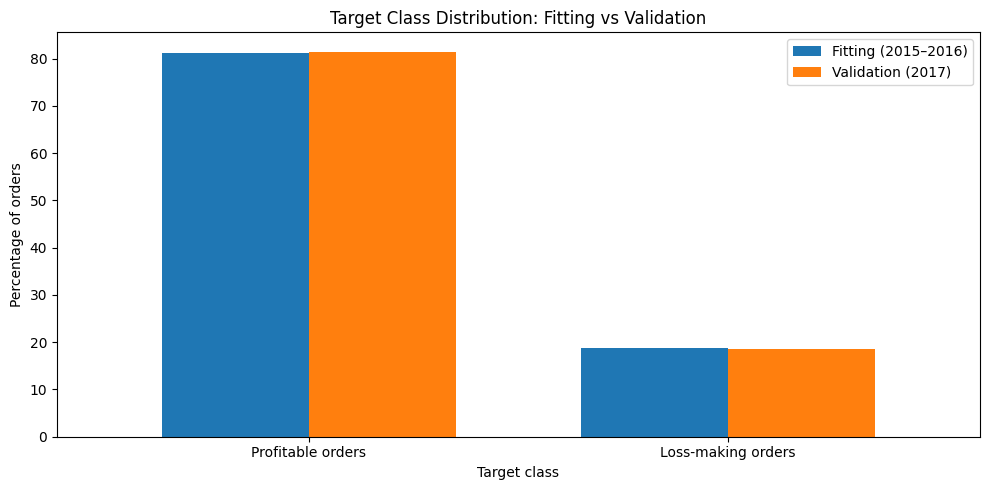


---------------------------------------------------------------------------
TARGET DISTRIBUTION VALIDATION
---------------------------------------------------------------------------
PASS | Fitting target distribution calculated
PASS | Validation target distribution calculated
PASS | Both partitions contain both target classes
PASS | Class counts reconcile with partition sizes


In [41]:
import matplotlib.pyplot as plt
print("=" * 75)
print("18.10 — TARGET DISTRIBUTION ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. BUILD TARGET DISTRIBUTION TABLE
# ------------------------------------------------------------

fit_counts = pd.Series(y_fit).value_counts().reindex(
    [0, 1], fill_value=0
)

validation_counts = pd.Series(y_validation).value_counts().reindex(
    [0, 1], fill_value=0
)

distribution_df = pd.DataFrame({
    "class": [0, 1],
    "class_description": [
        "Profitable orders",
        "Loss-making orders"
    ],
    "fitting_count": fit_counts.values,
    "validation_count": validation_counts.values
})

distribution_df["fitting_percentage"] = (
    distribution_df["fitting_count"] / len(y_fit) * 100
)

distribution_df["validation_percentage"] = (
    distribution_df["validation_count"] /
    len(y_validation) * 100
)

print("\nTARGET DISTRIBUTION")
print("-" * 75)

print(
    distribution_df.to_string(
        index=False,
        formatters={
            "fitting_percentage": "{:.2f}%".format,
            "validation_percentage": "{:.2f}%".format
        }
    )
)


# ------------------------------------------------------------
# 2. CALCULATE NEGATIVE-PROFIT PREVALENCE
# ------------------------------------------------------------

fit_loss_rate = float(np.mean(y_fit == 1) * 100)

validation_loss_rate = float(
    np.mean(y_validation == 1) * 100
)

prevalence_difference = (
    validation_loss_rate - fit_loss_rate
)

print("\nNEGATIVE-PROFIT PREVALENCE")
print("-" * 75)

print(f"Fitting loss-making rate:     {fit_loss_rate:.2f}%")
print(f"Validation loss-making rate:  {validation_loss_rate:.2f}%")
print(
    f"Difference (validation - fitting): "
    f"{prevalence_difference:+.2f} percentage points"
)


# ------------------------------------------------------------
# 3. VALIDATE TARGET DISTRIBUTIONS
# ------------------------------------------------------------

assert distribution_df["fitting_count"].sum() == len(y_fit)
assert distribution_df["validation_count"].sum() == len(y_validation)

assert distribution_df["fitting_count"].sum() > 0
assert distribution_df["validation_count"].sum() > 0

assert set(np.unique(y_fit)) == {0, 1}
assert set(np.unique(y_validation)) == {0, 1}


# ------------------------------------------------------------
# 4. VISUALIZE CLASS DISTRIBUTIONS
# ------------------------------------------------------------

plot_df = distribution_df.set_index(
    "class_description"
)[[
    "fitting_percentage",
    "validation_percentage"
]]

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

ax.set_title("Target Class Distribution: Fitting vs Validation")
ax.set_xlabel("Target class")
ax.set_ylabel("Percentage of orders")
ax.legend([
    "Fitting (2015–2016)",
    "Validation (2017)"
])

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("TARGET DISTRIBUTION VALIDATION")
print("-" * 75)

print("PASS | Fitting target distribution calculated")
print("PASS | Validation target distribution calculated")
print("PASS | Both partitions contain both target classes")
print("PASS | Class counts reconcile with partition sizes")

<h2 style="color: #1F4E78; font-weight: 700;">18.11 — Save Split Manifest and Final Validation Report</h2>

This subsection saves the chronological split outputs so the experiment can be reproduced and audited later.

Three artifacts will be created in a dedicated validation folder:
1. chronological_split_indices.npz — positional fitting and validation indices.
2. chronological_split_manifest.json — split dates, row counts, feature count, target prevalence, and methodology notes.
3. chronological_split_validation_report.csv — class counts and percentages for both partitions.
The original modeling artifacts will not be modified.

The manifest will explicitly record that preprocessing was fitted on the full 2015–2017 training population. Consequently, the split is chronological at the model-fitting stage but is not a fully untouched 2017 validation simulation.

In [42]:
import json
from pathlib import Path
from datetime import datetime

print("=" * 75)
print("18.11 — SAVE CHRONOLOGICAL SPLIT ARTIFACTS")
print("=" * 75)

# ------------------------------------------------------------
# 1. DEFINE OUTPUT DIRECTORY
# ------------------------------------------------------------

VALIDATION_DIR = (
    ARTIFACT_DIR /
    "06C_Profitability_OrderPlacement_Revised" /
    "Chronological_Validation"
)

VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

indices_path = VALIDATION_DIR / "chronological_split_indices.npz"

manifest_path = VALIDATION_DIR / "chronological_split_manifest.json"

report_path = VALIDATION_DIR / "chronological_split_validation_report.csv"


# ------------------------------------------------------------
# 2. VALIDATE FINAL INPUTS BEFORE SAVING
# ------------------------------------------------------------

assert len(fit_indices) == len(y_fit)
assert len(validation_indices) == len(y_validation)

assert X_fit.shape[1] == X_validation.shape[1]
assert X_fit.shape[1] == len(revised_names)

assert int(distribution_df["fitting_count"].sum()) == len(y_fit)
assert int(distribution_df["validation_count"].sum()) == len(y_validation)

assert int(distribution_df["fitting_count"].sum()) > 0
assert int(distribution_df["validation_count"].sum()) > 0

assert fit_end < validation_start


# ------------------------------------------------------------
# 3. SAVE POSITIONAL SPLIT INDICES
# ------------------------------------------------------------

np.savez_compressed(
    indices_path,
    fit_indices=fit_indices,
    validation_indices=validation_indices
)

print("\nSaved split indices:")
print(indices_path)


# ------------------------------------------------------------
# 4. PREPARE SPLIT MANIFEST
# ------------------------------------------------------------

manifest = {
    "experiment": "06C_Profitability_Risk_Prediction",
    "section": "18 — Chronological Validation Split",
    "created_at": datetime.now().isoformat(timespec="seconds"),

    "split_strategy": "Chronological",
    "fitting_period": {
        "start": str(fit_start),
        "end": str(fit_end),
        "years": [2015, 2016],
        "row_count": int(len(fit_indices))
    },
    "validation_period": {
        "start": str(validation_start),
        "end": str(validation_end),
        "years": [2017],
        "row_count": int(len(validation_indices))
    },

    "dataset": {
        "total_rows": int(len(source_train)),
        "feature_count": int(X_train_full.shape[1]),
        "feature_matrix_format": "CSR",
        "target_definition": "1 = loss-making order; 0 = profitable order"
    },

    "target_distribution": {
        "fitting": {
            "class_0_count": int(fit_counts.loc[0]),
            "class_1_count": int(fit_counts.loc[1]),
            "class_0_percentage": float(
                fit_counts.loc[0] / len(y_fit) * 100
            ),
            "class_1_percentage": float(fit_loss_rate)
        },
        "validation": {
            "class_0_count": int(validation_counts.loc[0]),
            "class_1_count": int(validation_counts.loc[1]),
            "class_0_percentage": float(
                validation_counts.loc[0] / len(y_validation) * 100
            ),
            "class_1_percentage": float(validation_loss_rate)
        },
        "loss_prevalence_difference_percentage_points": float(
            prevalence_difference
        )
    },

    "validation_checks": {
        "source_target_alignment": True,
        "feature_mapping_integrity": True,
        "original_revised_matrix_consistency": True,
        "numerical_feature_alignment": True,
        "chronological_separation": True,
        "complete_partition_coverage": True,
        "no_partition_overlap": True,
        "target_class_presence_in_both_partitions": True
    },

    "methodological_notes": [
        "The fitting period is 2015–2016 and the validation period is 2017.",
        "The split is chronological and uses positional indices.",
        "The revised feature matrix is retained in CSR sparse format.",
        "Preprocessing artifacts were previously fitted on the full 2015–2017 training population.",
        "Therefore, preprocessing statistics and category vocabulary have already seen the 2017 validation period.",
        "This split is not a fully untouched temporal simulation of preprocessing and model development."
    ]
}


# ------------------------------------------------------------
# 5. SAVE MANIFEST
# ------------------------------------------------------------

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(
        manifest,
        file,
        indent=4,
        ensure_ascii=False
    )

print("\nSaved split manifest:")
print(manifest_path)


# ------------------------------------------------------------
# 6. SAVE TARGET DISTRIBUTION REPORT
# ------------------------------------------------------------

distribution_df.to_csv(
    report_path,
    index=False
)

print("\nSaved target distribution report:")
print(report_path)


# ------------------------------------------------------------
# 7. VERIFY SAVED ARTIFACTS
# ------------------------------------------------------------

assert indices_path.exists()
assert manifest_path.exists()
assert report_path.exists()

assert indices_path.stat().st_size > 0
assert manifest_path.stat().st_size > 0
assert report_path.stat().st_size > 0

# Reopen and verify saved indices.
saved_indices = np.load(indices_path)

assert np.array_equal(
    saved_indices["fit_indices"],
    fit_indices
)

assert np.array_equal(
    saved_indices["validation_indices"],
    validation_indices
)

# Reopen and verify manifest.
with open(manifest_path, "r", encoding="utf-8") as file:
    saved_manifest = json.load(file)

assert saved_manifest["dataset"]["total_rows"] == len(source_train)
assert saved_manifest["dataset"]["feature_count"] == X_train_full.shape[1]

assert (
    saved_manifest["fitting_period"]["row_count"]
    == len(fit_indices)
)

assert (
    saved_manifest["validation_period"]["row_count"]
    == lenvalidation_indices)
)


# ------------------------------------------------------------
# 8. FINAL OUTPUT SUMMARY
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("SAVED ARTIFACTS")
print("-" * 75)

for path in [indices_path, manifest_path, report_path]:
    print(f"PASS | {path.name} ({path.stat().st_size:,} bytes)")

print("\n" + "-" * 75)
print("SECTION 18 FINAL VALIDATION SUMMARY")
print("-" * 75)

print("PASS | Chronological fitting and validation split")
print("PASS | Source, target, and feature alignment")
print("PASS | CSR fitting and validation matrices")
print("PASS | Target distributions analyzed")
print("PASS | Split indices saved and reloaded successfully")
print("PASS | Split manifest saved and verified")
print("PASS | Validation report saved")

18.11 — SAVE CHRONOLOGICAL SPLIT ARTIFACTS

Saved split indices:
C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts\06C_Profitability_OrderPlacement_Revised\Chronological_Validation\chronological_split_indices.npz

Saved split manifest:
C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts\06C_Profitability_OrderPlacement_Revised\Chronological_Validation\chronological_split_manifest.json

Saved target distribution report:
C:\Users\chavi\Desktop\SupplySight AI – Enterprise Procurement Decision Intelligence Platform\Datasets\Modeling Artifacts\06C_Profitability_OrderPlacement_Revised\Chronological_Validation\chronological_split_validation_report.csv

---------------------------------------------------------------------------
SAVED ARTIFACTS
---------------------------------------------------------------------------
PASS | chronological_split_indices.n

<h2 style="color: #548235; font-weight: 700;">Observation — Chronological Split Artifacts and Validation Report</h2>

- Three reproducibility artifacts were successfully saved in the dedicated `Chronological_Validation` folder:
  - `chronological_split_indices.npz` — fitting and validation positional indices.
  - `chronological_split_manifest.json` — split metadata, dates, row counts, feature count, and methodology notes.
  - `chronological_split_validation_report.csv` — target class counts and percentages for both partitions.
- All three files passed existence and non-zero file-size checks.
- The saved fitting and validation indices were reloaded and matched the in-memory indices exactly.
- The saved JSON manifest was reopened, and its total row count, feature count, and fitting and validation row counts matched the current datasets.
- The manifest records the preprocessing limitation: preprocessing was fitted on the full 2015–2017 training population, including the validation period.
- Reported artifact sizes:
  - NPZ indices: **270,545 bytes**
  - JSON manifest: **2,356 bytes**
  - CSV validation report: **237 bytes**
- All reported save and verification checks passed. The original modeling artifacts were not modified.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The chronological split indices and supporting metadata are now persisted, making the 2015–2016 fitting and 2017 validation partition reproducible.
- The saved indices can be reused to reconstruct the same partitions without repeating the chronological split procedure.
- The manifest appropriately documents that the existing preprocessing was fitted using the full historical training population. Therefore, this experiment is not a fully untouched 2017 validation simulation.
- The CSV report passed file existence and non-empty checks; the output shown does not establish that its contents were independently reloaded and compared with the in-memory distribution report.
- The final summary's broad statement `PASS | Source, target, and feature alignment` should be interpreted cautiously: target alignment and the nine selected numerical feature mappings were validated, but categorical feature alignment was not independently demonstrated.
- Section 18 has saved the chronological split artifacts, but the preprocessing leakage limitation must be addressed before treating subsequent model evaluation as a rigorous out-of-time validation.

<h1 style="color: #548235; font-weight: 700;">Section 18 — Chronological Validation Split: Conclusion</h1>

<h2 style="color: #548235; font-weight: 700;">Objective</h2>
    
Established a chronological fitting and validation split for the revised profitability risk prediction dataset, ensuring consistent row alignment across the source data, target labels, and revised sparse feature matrix.

### Chronological Split

| Dataset | Period | Rows |
|---|---|---:|
| Fitting | 2015–2016 | 125,200 |
| Validation | 2017 | 53,196 |
| **Total** | **2015–2017** | **178,396** |

Both partitions contain 6,948 revised features and retain the CSR sparse matrix format.

### Key Validation Results

- Source-to-target alignment verified with zero mismatches.
- Revised feature mapping verified for all 6,948 features.
- Revised matrix confirmed as an exact retained-column subset of the original matrix.
- All 9 numerical features passed source-to-matrix alignment validation.
- Chronological separation verified with no overlapping or missing rows.
- Both partitions contain profitable and loss-making orders.
- Loss-making order prevalence is 18.78% in fitting data and 18.54% in validation data.

### Saved Artifacts

The following artifacts were successfully saved under the `Chronological_Validation` directory:

1. `chronological_split_indices.npz`
2. `chronological_split_manifest.json`
3. `chronological_split_validation_report.csv`

### Methodological Limitation

The preprocessing pipeline was previously fitted on the complete 2015–2017 historical training population. Consequently, preprocessing statistics and category vocabulary have already incorporated information from the 2017 validation period.

The current split provides chronological separation for model fitting and evaluation, but it does not represent a fully untouched temporal validation simulation.

<h3 style="color: #7F6000; font-weight: 700;">Outcome</h3>

The revised modeling dataset is aligned, validated, partitioned chronologically, and ready for baseline model development.

**Next Stage:** Section 19 — Baseline Model Development and Evaluation.

In [43]:
print("=" * 75)
print("SECTION 18 — CHRONOLOGICAL VALIDATION SPLIT")
print("FINAL COMPLETION CHECK")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY DATASET DIMENSIONS
# ------------------------------------------------------------

assert X_fit.shape == (125200, 6948)
assert X_validation.shape == (53196, 6948)

assert len(y_fit) == 125200
assert len(y_validation) == 53196

assert X_fit.format == "csr"
assert X_validation.format == "csr"

print("PASS | Fitting dataset dimensions verified")
print("PASS | Validation dataset dimensions verified")
print("PASS | Both feature matrices retain CSR format")


# ------------------------------------------------------------
# 2. VERIFY CHRONOLOGICAL PARTITION
# ------------------------------------------------------------

assert len(fit_indices) + len(validation_indices) == 178396

assert fit_end < validation_start

assert len(np.intersect1d(
    fit_indices,
    validation_indices
)) == 0

print("PASS | Chronological partition verified")
print("PASS | No missing or overlapping row indices")


# ------------------------------------------------------------
# 3. VERIFY TARGET DISTRIBUTIONS
# ------------------------------------------------------------

assert np.array_equal(
    np.unique(y_fit),
    np.array([0, 1])
)

assert np.array_equal(
    np.unique(y_validation),
    np.array([0, 1])
)

print("PASS | Both partitions contain both target classes")


# ------------------------------------------------------------
# 4. VERIFY SAVED ARTIFACTS
# ------------------------------------------------------------

validation_dir = (
    ARTIFACT_DIR /
    "06C_Profitability_OrderPlacement_Revised" /
    "Chronological_Validation"
)

required_artifacts = [
    "chronological_split_indices.npz",
    "chronological_split_manifest.json",
    "chronological_split_validation_report.csv"
]

for filename in required_artifacts:
    artifact_path = validation_dir / filename

    assert artifact_path.exists(), (
        f"Missing artifact: {filename}"
    )

    assert artifact_path.stat().st_size > 0, (
        f"Empty artifact: {filename}"
    )

    print(f"PASS | {filename}")


# ------------------------------------------------------------
# 5. VERIFY SAVED MANIFEST
# ------------------------------------------------------------

manifest_path = (
    validation_dir /
    "chronological_split_manifest.json"
)

with open(manifest_path, "r", encoding="utf-8") as file:
    final_manifest = json.load(file)

assert final_manifest["dataset"]["total_rows"] == 178396
assert final_manifest["dataset"]["feature_count"] == 6948

assert final_manifest["fitting_period"]["row_count"] == 125200
assert final_manifest["validation_period"]["row_count"] == 53196

print("PASS | Saved manifest metadata verified")


# ------------------------------------------------------------
# 6. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SECTION 18 STATUS: COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Historical rows processed:       178,396")
print("Fitting observations:             125,200")
print("Validation observations:           53,196")
print("Revised features:                    6,948")
print("Numerical alignment mismatches:         0")
print("Saved validation artifacts:             3")

SECTION 18 — CHRONOLOGICAL VALIDATION SPLIT
FINAL COMPLETION CHECK
PASS | Fitting dataset dimensions verified
PASS | Validation dataset dimensions verified
PASS | Both feature matrices retain CSR format
PASS | Chronological partition verified
PASS | No missing or overlapping row indices
PASS | Both partitions contain both target classes
PASS | chronological_split_indices.npz
PASS | chronological_split_manifest.json
PASS | chronological_split_validation_report.csv
PASS | Saved manifest metadata verified

SECTION 18 STATUS: COMPLETED SUCCESSFULLY
Historical rows processed:       178,396
Fitting observations:             125,200
Validation observations:           53,196
Revised features:                    6,948
Numerical alignment mismatches:         0
Saved validation artifacts:             3


<hr>

<h1 style="color: #1F4E78; font-weight: 700;">19 — Baseline Model Development and Evaluation</h1>

# Objective

The objective of this section is to develop and evaluate baseline machine-learning models for predicting whether an order will be loss-making using the revised order-placement feature set established in the preceding sections.

The target variable is defined as:

- `0` — Profitable order
- `1` — Loss-making order

The modeling process will use the chronological datasets prepared in Section 18.

## Modeling Dataset

| Component | Description | Observations |
|---|---|---:|
| Fitting data | 2015–2016 | 125,200 |
| Validation data | 2017 | 53,196 |
| Revised features | Order-placement features | 6,948 |

## Modeling Approach

Baseline model development will follow an incremental approach, beginning with a naive benchmark before introducing machine-learning algorithms.

| Stage | Model / Activity | Purpose |
|---|---|---|
| 19.1 | Modeling objectives and evaluation strategy | Establish the modeling configuration and evaluation framework |
| 19.2 | Majority-class baseline | Establish a naive classification benchmark |
| 19.3 | Logistic Regression | Develop the first machine-learning baseline |
| 19.4 onward | Model evaluation and diagnostics | Assess predictive performance, classification errors, and model limitations |

## Evaluation Metrics

Model performance will be evaluated using the following metrics:

- **ROC-AUC:** Measures the model's ability to distinguish between profitable and loss-making orders across classification thresholds.
- **PR-AUC:** Evaluates the precision-recall trade-off, with particular emphasis on identifying the minority loss-making class.
- **Precision (Class 1):** Measures the proportion of predicted loss-making orders that are actually loss-making.
- **Recall (Class 1):** Measures the proportion of actual loss-making orders correctly identified by the model.
- **F1-score (Class 1):** Represents the harmonic mean of precision and recall for the loss-making class.
- **Balanced Accuracy:** Measures the average recall across both classes, accounting for class imbalance.
- **Confusion Matrix:** Summarizes true positives, true negatives, false positives, and false negatives.

## Classification Threshold

All initial model evaluations will use the default classification probability threshold of `0.50`.

Threshold optimization will be considered separately using validation results, without modifying the original baseline evaluation.

## Methodological Considerations

The preprocessing artifacts were fitted using the complete 2015–2017 training population. Therefore, the 2017 validation period has influenced preprocessing statistics and category vocabulary.

This introduces a methodological limitation because the validation period was not completely isolated during preprocessing.

The limitation will be explicitly acknowledged when interpreting model performance. The chronological fitting and validation datasets will otherwise remain unchanged throughout baseline model development.

The fitting dataset will be used for model training, while the validation dataset will be used for performance evaluation and model diagnostics.

The purpose of this section is to establish an initial predictive benchmark and assess whether the revised order-placement features contain useful information for identifying potentially loss-making orders.

<h2 style="color: #1F4E78; font-weight: 700;">19.1 — Modeling Objectives and Evaluation Strategy</h2>

## Objective

This subsection establishes the modeling configuration and validates the availability and consistency of the datasets and preprocessing outputs prepared in Section 18.

Before training any baseline model, the following configurations and validation requirements will be established.

### 1. Target Variable Definition

The classification target represents whether an order is profitable or loss-making.

| Target Value | Class | Description |
|---|---|---|
| 0 | Profitable | Order generates non-negative profit |
| 1 | Loss-making | Order generates negative profit |

The positive class will be defined as `1` (loss-making orders), ensuring that precision, recall, and F1-score calculations focus on identifying loss-making transactions.

### 2. Classification Threshold

The initial classification threshold will be set to `0.50`.

Predicted probabilities will be converted into class predictions using this threshold:

- Probability >= 0.50: Loss-making order (`1`)
- Probability < 0.50: Profitable order (`0`)

Threshold optimization will be addressed separately after evaluating the baseline models.

### 3. Evaluation Metrics

The following metrics will be registered for consistent evaluation across baseline models:

- ROC-AUC
- PR-AUC
- Precision (Class 1)
- Recall (Class 1)
- F1-score (Class 1)
- Balanced Accuracy
- Confusion Matrix

ROC-AUC and PR-AUC will be calculated using predicted probabilities, while the remaining classification metrics will initially use predictions generated at the default threshold of `0.50`.

### 4. Dataset and Feature Matrix Validation

The fitting and validation datasets prepared in Section 18 will be checked to confirm:

- Fitting observations correspond to the 2015–2016 period.
- Validation observations correspond to the 2017 period.
- The fitting and validation feature matrices contain the expected 6,948 revised features.
- Target variables are correctly aligned with their corresponding feature matrices.
- Both target variables contain the expected binary classes.
- Feature matrices use the expected sparse representation.
- Feature names are available and consistent across fitting and validation matrices.
- No unexpected differences exist in feature ordering or dimensions.

### 5. Baseline Modeling Configuration

The following configuration will be maintained throughout the initial baseline evaluation:

| Parameter | Configuration |
|---|---|
| Modeling objective | Binary classification |
| Negative class | 0 — Profitable |
| Positive class | 1 — Loss-making |
| Fitting period | 2015–2016 |
| Validation period | 2017 |
| Fitting observations | 125,200 |
| Validation observations | 53,196 |
| Number of features | 6,948 |
| Default classification threshold | 0.50 |
| Primary evaluation focus | Loss-making order detection |
| Evaluation approach | Chronological validation |

### 6. Methodological Safeguards

The following safeguards will be maintained:

- The chronological fitting and validation datasets will not be modified.
- The validation dataset will not be used for model fitting.
- The preprocessing artifacts established in Section 18 will remain unchanged.
- The original feature set will be preserved without silently adding or removing variables.
- The default classification threshold will remain `0.50` during initial baseline comparisons.
- Any preprocessing-related validation leakage will be acknowledged when interpreting results.

## Expected Outcome

At the end of this subsection, the modeling environment should have a verified fitting matrix, validation matrix, aligned target variables, consistent feature names, and a clearly defined evaluation configuration.

No model training, hyperparameter optimization, or threshold selection will be performed at this stage.

The validated configuration will serve as the foundation for the majority-class benchmark in Section 19.2 and Logistic Regression baseline development in Section 19.3.

In [45]:
import scipy
import sklearn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
from scipy import sparse

print("=" * 75)
print("19.1 — MODELING OBJECTIVES AND EVALUATION STRATEGY")
print("=" * 75)


# ------------------------------------------------------------
# 1. DEFINE TARGET CLASS MEANINGS
# ------------------------------------------------------------

TARGET_CLASS_MAPPING = {
    0: "Profitable order",
    1: "Loss-making order"
}

POSITIVE_CLASS = 1
DEFAULT_THRESHOLD = 0.50

print("\nTARGET DEFINITION")
print("-" * 75)

for label, description in TARGET_CLASS_MAPPING.items():
    print(f"{label} = {description}")

print(f"\nPositive class: {POSITIVE_CLASS}")
print(f"Default threshold: {DEFAULT_THRESHOLD:.2f}")


# ------------------------------------------------------------
# 2. DEFINE EVALUATION METRICS
# ------------------------------------------------------------

EVALUATION_METRICS = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC",
    "Confusion Matrix"
]

print("\nEVALUATION METRICS")
print("-" * 75)

for metric in EVALUATION_METRICS:
    print(f"- {metric}")


# ------------------------------------------------------------
# 3. VERIFY FITTING AND VALIDATION DATASETS
# ------------------------------------------------------------

assert "X_fit" in globals()
assert "X_validation" in globals()
assert "y_fit" in globals()
assert "y_validation" in globals()

assert X_fit.shape[0] == len(y_fit)
assert X_validation.shape[0] == len(y_validation)

assert X_fit.shape[1] == X_validation.shape[1]

assert sparse.isspmatrix_csr(X_fit)
assert sparse.isspmatrix_csr(X_validation)

assert X_fit.shape[1] == len(revised_names)

assert set(np.unique(y_fit)) == {0, 1}
assert set(np.unique(y_validation)) == {0, 1}

print("\nDATASET VERIFICATION")
print("-" * 75)

print(f"Fitting observations:       {X_fit.shape[0]:,}")
print(f"Validation observations:    {X_validation.shape[0]:,}")
print(f"Number of features:         {X_fit.shape[1]:,}")

print(f"Fitting matrix format:      {X_fit.format}")
print(f"Validation matrix format:   {X_validation.format}")

print("PASS | Feature and target dimensions match")
print("PASS | Fitting and validation feature counts match")
print("PASS | Both matrices retain CSR sparse format")
print("PASS | Both targets contain binary classes 0 and 1")


# ------------------------------------------------------------
# 4. RECORD CLASS DISTRIBUTIONS
# ------------------------------------------------------------

fit_class_distribution = (
    pd.Series(y_fit)
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

validation_class_distribution = (
    pd.Series(y_validation)
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("\nCLASS DISTRIBUTION")
print("-" * 75)

for class_label, description in TARGET_CLASS_MAPPING.items():
    print(
        f"{description}: "
        f"Fitting = {fit_class_distribution.loc[class_label]:.2f}% | "
        f"Validation = {validation_class_distribution.loc[class_label]:.2f}%"
    )


# ------------------------------------------------------------
# 5. RECORD MODELING CONFIGURATION
# ------------------------------------------------------------

MODELING_CONFIG = {
    "experiment": "Profitability Risk Prediction",
    "positive_class": POSITIVE_CLASS,
    "positive_class_meaning": TARGET_CLASS_MAPPING[POSITIVE_CLASS],
    "default_threshold": DEFAULT_THRESHOLD,
    "fitting_period": "2015–2016",
    "validation_period": "2017",
    "number_of_features": int(X_fit.shape[1]),
    "fitting_observations": int(X_fit.shape[0]),
    "validation_observations": int(X_validation.shape[0]),
    "matrix_format": "CSR",
    "evaluation_metrics": EVALUATION_METRICS
}


# ------------------------------------------------------------
# 6. DISPLAY ENVIRONMENT VERSIONS
# ------------------------------------------------------------

print("\nENVIRONMENT VERSIONS")
print("-" * 75)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)


# ------------------------------------------------------------
# 7. FINAL VALIDATION
# ------------------------------------------------------------

assert POSITIVE_CLASS == 1
assert DEFAULT_THRESHOLD == 0.50
assert len(EVALUATION_METRICS) == 8
assert MODELING_CONFIG["number_of_features"] == 6948

print("\n" + "=" * 75)
print("19.1 MODELING CONFIGURATION")
print("=" * 75)

print("PASS | Target class mapping established")
print("PASS | Positive class defined as loss-making orders")
print("PASS | Default classification threshold established")
print("PASS | Evaluation metrics registered")
print("PASS | Fitting and validation datasets verified")
print("PASS | Modeling configuration recorded")

19.1 — MODELING OBJECTIVES AND EVALUATION STRATEGY

TARGET DEFINITION
---------------------------------------------------------------------------
0 = Profitable order
1 = Loss-making order

Positive class: 1
Default threshold: 0.50

EVALUATION METRICS
---------------------------------------------------------------------------
- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Confusion Matrix

DATASET VERIFICATION
---------------------------------------------------------------------------
Fitting observations:       125,200
Validation observations:    53,196
Number of features:         6,948
Fitting matrix format:      csr
Validation matrix format:   csr
PASS | Feature and target dimensions match
PASS | Fitting and validation feature counts match
PASS | Both matrices retain CSR sparse format
PASS | Both targets contain binary classes 0 and 1

CLASS DISTRIBUTION
---------------------------------------------------------------------------
Profitable order:

<h2 style="color: #548235; font-weight: 700;">Observation — Modeling Objectives and Evaluation Strategy</h2>

- The profitability-risk modeling configuration was successfully established for binary classification, with the target defined as:
  - **Class 0:** Profitable orders
  - **Class 1:** Loss-making orders
- Loss-making orders were designated as the positive class, ensuring that minority-class evaluation focuses on identifying potentially unprofitable transactions.
- The default classification probability threshold was set to **0.50** for initial baseline comparisons.
- The fitting dataset contains **125,200 observations** from 2015–2016, while the validation dataset contains **53,196 observations** from 2017.
- Both feature matrices contain **6,948 features** and retain CSR sparse format. Feature and target dimensions were successfully validated.
- The target distributions remain similar across the two partitions:
  - Profitable orders: 81.22% fitting and 81.46% validation.
  - Loss-making orders: 18.78% fitting and 18.54% validation.
- Eight evaluation outputs were registered: Accuracy, Balanced Accuracy, Precision, Recall, F1-score, ROC-AUC, PR-AUC, and Confusion Matrix.
- The modeling configuration and environment versions were recorded, and all reported configuration assertions passed.
- No model training, hyperparameter optimization, or threshold selection was performed.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The modeling environment is configured for consistent baseline evaluation using the same target definition, feature set, and default classification threshold.
- ROC-AUC and PR-AUC will assess probability-based ranking performance, while the threshold-dependent metrics will initially evaluate predictions at 0.50.
- Because loss-making orders represent approximately 19% of observations, accuracy alone may conceal poor identification of the minority class. Precision, recall, F1-score, PR-AUC, and balanced accuracy should receive particular attention.
- The 2017 validation dataset will be used for performance evaluation and model diagnostics, not model fitting.
- The previously identified preprocessing limitation remains: preprocessing statistics and category vocabulary were fitted using the complete 2015–2017 training population, including the validation period. This must be acknowledged when interpreting baseline results.
- The established configuration provides the foundation for the majority-class benchmark in Section 19.2 and Logistic Regression baseline development in Section 19.3.

<h2 style="color: #1F4E78; font-weight: 700;">19.2 — Majority-Class Baseline</h2>

## Objective
Establish a simple benchmark using a classifier that always predicts the majority class.

Since profitable orders (class 0) represent approximately 81% of observations, the majority-class classifier will predict every order as profitable.

This baseline helps us understand why accuracy can be misleading for an imbalanced classification problem.
Methodology
1. Identify the majority class using only the fitting target.
2. Predict that class for every fitting and validation observation.
3. Calculate classification metrics on both datasets.
4. Generate confusion matrices.
5. Compare the results to understand the limitations of a naive classifier.
No machine-learning model is trained in this subsection.

In [46]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 75)
print("19.2 — MAJORITY-CLASS BASELINE")
print("=" * 75)


# ------------------------------------------------------------
# 1. IDENTIFY MAJORITY CLASS FROM FITTING DATA
# ------------------------------------------------------------

class_counts = pd.Series(y_fit).value_counts().sort_index()

majority_class = int(class_counts.idxmax())
minority_class = int(class_counts.idxmin())

assert majority_class == 0
assert minority_class == 1

print("\nFITTING CLASS COUNTS")
print("-" * 75)
print(class_counts)

print(f"\nMajority class: {majority_class}")
print(f"Majority class meaning: {TARGET_CLASS_MAPPING[majority_class]}")
print(f"Minority class: {minority_class}")


# ------------------------------------------------------------
# 2. INITIALIZE MAJORITY-CLASS CLASSIFIER
# ------------------------------------------------------------

majority_model = DummyClassifier(
    strategy="most_frequent"
)

majority_model.fit(
    X_fit,
    y_fit
)

print("\nPASS | Majority-class baseline fitted")


# ------------------------------------------------------------
# 3. GENERATE PREDICTIONS
# ------------------------------------------------------------

y_fit_pred_dummy = majority_model.predict(X_fit)

y_validation_pred_dummy = majority_model.predict(
    X_validation
)

assert len(y_fit_pred_dummy) == len(y_fit)
assert len(y_validation_pred_dummy) == len(y_validation)

assert np.all(y_fit_pred_dummy == majority_class)
assert np.all(y_validation_pred_dummy == majority_class)

print("PASS | Fitting predictions generated")
print("PASS | Validation predictions generated")
print("PASS | All observations assigned to majority class")


# ------------------------------------------------------------
# 4. DEFINE METRIC CALCULATION FUNCTION
# ------------------------------------------------------------

def calculate_baseline_metrics(y_true, y_pred, dataset_name):

    return {
        "dataset": dataset_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "precision_class_1": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "recall_class_1": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "f1_class_1": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        )
    }


# ------------------------------------------------------------
# 5. CALCULATE FITTING AND VALIDATION METRICS
# ------------------------------------------------------------

fit_dummy_metrics = calculate_baseline_metrics(
    y_fit,
    y_fit_pred_dummy,
    "Fitting"
)

validation_dummy_metrics = calculate_baseline_metrics(
    y_validation,
    y_validation_pred_dummy,
    "Validation"
)

majority_baseline_results = pd.DataFrame([
    fit_dummy_metrics,
    validation_dummy_metrics
])

print("\nMAJORITY-CLASS BASELINE METRICS")
print("-" * 75)

print(
    majority_baseline_results.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "balanced_accuracy": "{:.4f}".format,
            "precision_class_1": "{:.4f}".format,
            "recall_class_1": "{:.4f}".format,
            "f1_class_1": "{:.4f}".format
        }
    )
)


# ------------------------------------------------------------
# 6. GENERATE CONFUSION MATRICES
# ------------------------------------------------------------

fit_confusion = confusion_matrix(
    y_fit,
    y_fit_pred_dummy,
    labels=[0, 1]
)

validation_confusion = confusion_matrix(
    y_validation,
    y_validation_pred_dummy,
    labels=[0, 1]
)

print("\nFITTING CONFUSION MATRIX")
print("-" * 75)
print(fit_confusion)

print("\nVALIDATION CONFUSION MATRIX")
print("-" * 75)
print(validation_confusion)


# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT — VALIDATION DATA
# ------------------------------------------------------------

print("\nVALIDATION CLASSIFICATION REPORT")
print("-" * 75)

print(
    classification_report(
        y_validation,
        y_validation_pred_dummy,
        labels=[0, 1],
        target_names=[
            "Profitable orders",
            "Loss-making orders"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 8. BASELINE INTERPRETATION
# ------------------------------------------------------------

validation_accuracy = accuracy_score(
    y_validation,
    y_validation_pred_dummy
)

validation_recall = recall_score(
    y_validation,
    y_validation_pred_dummy,
    pos_label=1,
    zero_division=0
)

validation_f1 = f1_score(
    y_validation,
    y_validation_pred_dummy,
    pos_label=1,
    zero_division=0
)

print("\nBASELINE INTERPRETATION")
print("-" * 75)

print(f"Validation accuracy:       {validation_accuracy:.4f}")
print(f"Loss-making order recall:  {validation_recall:.4f}")
print(f"Loss-making order F1:      {validation_f1:.4f}")

print(
    "\nThe majority-class classifier achieves reasonable accuracy "
    "by predicting every order as profitable."
)

print(
    "However, it fails to identify any loss-making orders."
)


# ------------------------------------------------------------
# 9. FINAL VALIDATION
# ------------------------------------------------------------

assert np.all(y_validation_pred_dummy == 0)
assert validation_recall == 0.0
assert validation_f1 == 0.0

assert fit_confusion[1, 0] == int(np.sum(y_fit == 1))
assert validation_confusion[1, 0] == int(
    np.sum(y_validation == 1)
)

print("\n" + "=" * 75)
print("19.2 MAJORITY-CLASS BASELINE VALIDATION")
print("=" * 75)

print("PASS | Majority class identified from fitting data")
print("PASS | Dummy classifier fitted successfully")
print("PASS | Fitting and validation predictions generated")
print("PASS | Classification metrics calculated")
print("PASS | Confusion matrices generated")
print("PASS | Zero recall for loss-making orders confirmed")

19.2 — MAJORITY-CLASS BASELINE

FITTING CLASS COUNTS
---------------------------------------------------------------------------
0    101686
1     23514
Name: count, dtype: int64

Majority class: 0
Majority class meaning: Profitable order
Minority class: 1

PASS | Majority-class baseline fitted
PASS | Fitting predictions generated
PASS | Validation predictions generated
PASS | All observations assigned to majority class

MAJORITY-CLASS BASELINE METRICS
---------------------------------------------------------------------------
   dataset accuracy balanced_accuracy precision_class_1 recall_class_1 f1_class_1
   Fitting   0.8122            0.5000            0.0000         0.0000     0.0000
Validation   0.8146            0.5000            0.0000         0.0000     0.0000

FITTING CONFUSION MATRIX
---------------------------------------------------------------------------
[[101686      0]
 [ 23514      0]]

VALIDATION CONFUSION MATRIX
-------------------------------------------------------

<h2 style="color: #548235; font-weight: 700;">Observation — Majority-Class Baseline</h2>

- The majority class was identified using only the fitting target. Profitable orders (class 0) represent 81.22% of fitting observations, making class 0 the baseline prediction for every order.
- The Dummy Classifier successfully generated predictions for both fitting and validation datasets without training a predictive machine-learning model.
- The baseline achieved:
  - **Fitting accuracy:** 81.22%
  - **Validation accuracy:** 81.46%
  - **Balanced accuracy:** 50.00% on both datasets.
- Precision, recall, and F1-score for the loss-making class (class 1) were all **0.00%** across both partitions.
- The validation confusion matrix shows:
  - True negatives: 43,335
  - False positives: 0
  - False negatives: 9,861
  - True positives: 0
- The classifier correctly identifies all profitable orders but fails to identify any loss-making orders.
- All baseline validation assertions passed, including confirmation of zero recall for the positive class.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- The majority-class baseline demonstrates that approximately 81% accuracy can be achieved simply by predicting every order as profitable, without identifying any loss-making transactions.
- Therefore, accuracy alone is insufficient for evaluating profitability-risk models in this imbalanced classification problem.
- The baseline establishes a reference point that subsequent machine-learning models must improve upon, particularly in identifying the minority loss-making class.
- Future models should be evaluated using ROC-AUC, PR-AUC, precision, recall, F1-score, and balanced accuracy, alongside confusion matrices.
- **Recall for class 1 is particularly important** because it measures the proportion of actual loss-making orders successfully detected.
- A useful predictive model should demonstrate meaningful improvement over the baseline's zero loss-making-order recall while maintaining an acceptable level of precision and false-positive rate.

<h2 style="color: #1F4E78; font-weight: 700;">19.3 — Logistic Regression Baseline</h2>

## Objective
Train a Logistic Regression classifier using the revised 6,948-feature dataset.

Logistic Regression will serve as our first trainable classification model and provide a benchmark for evaluating whether the features contain useful predictive information.
Methodology
1. Train using X_fit and y_fit (2015–2016).
2. Use X_validation and y_validation (2017) for evaluation.
3. Apply the default classification threshold of 0.50.
4. Use class weighting to account for the imbalance between profitable and loss-making orders.
5. Evaluate classification metrics, ROC-AUC, PR-AUC and confusion matrix.
We will use class_weight="balanced" so that the minority loss-making class receives greater weight during model fitting.

The model will use sparse-compatible input and will not densify the feature matrices.

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("=" * 75)
print("19.3 — LOGISTIC REGRESSION BASELINE")
print("=" * 75)


# ------------------------------------------------------------
# 1. INITIALIZE MODEL
# ------------------------------------------------------------

logistic_model = LogisticRegression(
    class_weight="balanced",
    solver="saga",
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

print("\nMODEL CONFIGURATION")
print("-" * 75)

print("Algorithm: Logistic Regression")
print("Class weighting: Balanced")
print("Solver: saga")
print("Maximum iterations: 1000")
print("Random state: 42")


# ------------------------------------------------------------
# 2. TRAIN MODEL
# ------------------------------------------------------------

print("\nTraining Logistic Regression...")

logistic_model.fit(
    X_fit,
    y_fit
)

print("PASS | Logistic Regression training completed")


# ------------------------------------------------------------
# 3. GENERATE VALIDATION PREDICTIONS
# ------------------------------------------------------------

y_validation_proba_lr = logistic_model.predict_proba(
    X_validation
)[:, 1]

y_validation_pred_lr = (
    y_validation_proba_lr >= DEFAULT_THRESHOLD
).astype(int)

assert len(y_validation_pred_lr) == len(y_validation)
assert len(y_validation_proba_lr) == len(y_validation)

assert np.isfinite(y_validation_proba_lr).all()

print("PASS | Validation probabilities generated")
print("PASS | Validation predictions generated")


# ------------------------------------------------------------
# 4. CALCULATE VALIDATION METRICS
# ------------------------------------------------------------

lr_accuracy = accuracy_score(
    y_validation,
    y_validation_pred_lr
)

lr_balanced_accuracy = balanced_accuracy_score(
    y_validation,
    y_validation_pred_lr
)

lr_precision = precision_score(
    y_validation,
    y_validation_pred_lr,
    pos_label=1,
    zero_division=0
)

lr_recall = recall_score(
    y_validation,
    y_validation_pred_lr,
    pos_label=1,
    zero_division=0
)

lr_f1 = f1_score(
    y_validation,
    y_validation_pred_lr,
    pos_label=1,
    zero_division=0
)

lr_roc_auc = roc_auc_score(
    y_validation,
    y_validation_proba_lr
)

lr_pr_auc = average_precision_score(
    y_validation,
    y_validation_proba_lr
)


# ------------------------------------------------------------
# 5. DISPLAY VALIDATION METRICS
# ------------------------------------------------------------

logistic_validation_results = pd.DataFrame([{
    "model": "Logistic Regression",
    "accuracy": lr_accuracy,
    "balanced_accuracy": lr_balanced_accuracy,
    "precision_class_1": lr_precision,
    "recall_class_1": lr_recall,
    "f1_class_1": lr_f1,
    "roc_auc": lr_roc_auc,
    "pr_auc": lr_pr_auc
}])

print("\nVALIDATION PERFORMANCE")
print("-" * 75)

print(
    logistic_validation_results.to_string(
        index=False,
        formatters={
            column: "{:.4f}".format
            for column in logistic_validation_results.select_dtypes(
                include="number"
            ).columns
        }
    )
)


# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

lr_confusion = confusion_matrix(
    y_validation,
    y_validation_pred_lr,
    labels=[0, 1]
)

print("\nVALIDATION CONFUSION MATRIX")
print("-" * 75)
print(lr_confusion)


# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nVALIDATION CLASSIFICATION REPORT")
print("-" * 75)

print(
    classification_report(
        y_validation,
        y_validation_pred_lr,
        labels=[0, 1],
        target_names=[
            "Profitable orders",
            "Loss-making orders"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 8. TRAINING DIAGNOSTICS
# ------------------------------------------------------------

print("\nTRAINING DIAGNOSTICS")
print("-" * 75)

print("Iterations used:", logistic_model.n_iter_)
print("Number of features:", len(logistic_model.coef_[0]))
print("Intercept:", logistic_model.intercept_)

if np.any(logistic_model.n_iter_ >= logistic_model.max_iter):
    print(
        "WARNING | At least one solver iteration reached max_iter. "
        "Convergence should be investigated."
    )
else:
    print("PASS | Solver stopped before reaching max_iter")


# ------------------------------------------------------------
# 9. SAVE MODEL RESULTS IN MEMORY
# ------------------------------------------------------------

logistic_model_results = {
    "model": "Logistic Regression",
    "threshold": DEFAULT_THRESHOLD,
    "accuracy": lr_accuracy,
    "balanced_accuracy": lr_balanced_accuracy,
    "precision_class_1": lr_precision,
    "recall_class_1": lr_recall,
    "f1_class_1": lr_f1,
    "roc_auc": lr_roc_auc,
    "pr_auc": lr_pr_auc
}


# ------------------------------------------------------------
# 10. FINAL VALIDATION
# ------------------------------------------------------------

assert 0 <= lr_accuracy <= 1
assert 0 <= lr_balanced_accuracy <= 1
assert 0 <= lr_precision <= 1
assert 0 <= lr_recall <= 1
assert 0 <= lr_f1 <= 1
assert 0 <= lr_roc_auc <= 1
assert 0 <= lr_pr_auc <= 1

print("\n" + "=" * 75)
print("19.3 LOGISTIC REGRESSION VALIDATION")
print("=" * 75)

print("PASS | Logistic Regression fitted")
print("PASS | Sparse feature matrices used")
print("PASS | Validation probabilities generated")
print("PASS | Validation predictions generated")
print("PASS | Classification metrics calculated")
print("PASS | ROC-AUC and PR-AUC calculated")
print("PASS | Confusion matrix generated")

19.3 — LOGISTIC REGRESSION BASELINE

MODEL CONFIGURATION
---------------------------------------------------------------------------
Algorithm: Logistic Regression
Class weighting: Balanced
Solver: saga
Maximum iterations: 1000
Random state: 42

Training Logistic Regression...
PASS | Logistic Regression training completed
PASS | Validation probabilities generated
PASS | Validation predictions generated

VALIDATION PERFORMANCE
---------------------------------------------------------------------------
              model accuracy balanced_accuracy precision_class_1 recall_class_1 f1_class_1 roc_auc pr_auc
Logistic Regression   0.3394            0.5037            0.1869         0.7649     0.3003  0.5040 0.1855

VALIDATION CONFUSION MATRIX
---------------------------------------------------------------------------
[[10510 32825]
 [ 2318  7543]]

VALIDATION CLASSIFICATION REPORT
---------------------------------------------------------------------------
                    precision    rec

<h2 style="color: #548235; font-weight: 700;">Observation — Logistic Regression Baseline</h2>

- Logistic Regression was successfully trained using the 2015–2016 fitting dataset, with all **6,948 revised features** and `class_weight="balanced"`.
- The model used the SAGA solver, a maximum of 1,000 iterations, and random state 42. Sparse CSR matrices were used without densification.
- At the default classification threshold of **0.50**, the validation results were:
  - Accuracy: **33.94%**
  - Balanced Accuracy: **50.37%**
  - Precision (class 1): **18.69%**
  - Recall (class 1): **76.49%**
  - F1-score (class 1): **30.03%**
  - ROC-AUC: **0.5040**
  - PR-AUC: **0.1855**
- The validation confusion matrix shows:
  - True negatives: 10,510
  - False positives: 32,825
  - False negatives: 2,318
  - True positives: 7,543
- The model identifies 7,543 of the 9,861 actual loss-making orders, achieving relatively high recall.
- However, it incorrectly classifies 32,825 profitable orders as loss-making, resulting in low precision and accuracy.
- The SAGA solver reached its maximum of **1,000 iterations** without reporting convergence. Therefore, the model's fitted coefficients and evaluation results should be treated as provisional.

<h3 style="color: #7F6000; font-weight: 700;">Modeling Implication</h3>

- Logistic Regression demonstrates substantially higher loss-making-order recall than the majority-class baseline, which achieved 0% recall.
- However, its ROC-AUC of **0.5040** indicates almost no ability to distinguish between profitable and loss-making orders through probability ranking. Its PR-AUC of **0.1855** also indicates limited minority-class predictive performance.
- The high recall comes with a substantial false-positive burden: 32,825 profitable orders are incorrectly flagged. This could create considerable unnecessary investigation or intervention costs.
- The non-convergence warning is a critical limitation. The current performance should not be accepted as the final Logistic Regression benchmark.
- Investigate solver convergence, optimization settings, feature scaling, and the impact of high-dimensional sparse features before accepting the model.
- Re-evaluate the model after convergence is achieved, retaining the same chronological fitting and validation partitions and the default 0.50 threshold for the initial comparison.
- Do not optimize the classification threshold until a reliable, converged baseline has been established.

<h2 style="color: #1F4E78; font-weight: 700;">19.4 — Logistic Regression Convergence Optimization</h2>

## Objective
Improve the convergence of Logistic Regression while retaining the same fitting and validation datasets.
Approach
- Retain the saga solver.
- Increase max_iter from 1,000 to 5,000.
- Retain balanced class weighting.
- Retain the same random state and default classification threshold.
- Use a tighter convergence tolerance of 1e-4.
- Evaluate the optimized model using the same validation metrics.
The original logistic_model will be preserved. The new model will be stored separately as logistic_model_optimized.

We will compare convergence diagnostics and predictive performance rather than assuming that additional iterations will improve the model.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 75)
print("19.4 — LOGISTIC REGRESSION CONVERGENCE OPTIMIZATION")
print("=" * 75)


# ------------------------------------------------------------
# 1. RECORD ORIGINAL MODEL DIAGNOSTICS
# ------------------------------------------------------------

original_iterations = int(logistic_model.n_iter_[0])

print("\nORIGINAL MODEL")
print("-" * 75)

print("Maximum iterations:", logistic_model.max_iter)
print("Iterations used:", original_iterations)
print("Convergence status:",
      "Not converged" if original_iterations >= logistic_model.max_iter
      else "Converged")


# ------------------------------------------------------------
# 2. INITIALIZE OPTIMIZED MODEL
# ------------------------------------------------------------

logistic_model_optimized = LogisticRegression(
    class_weight="balanced",
    solver="saga",
    max_iter=5000,
    tol=1e-4,
    random_state=42,
    n_jobs=-1
)

print("\nOPTIMIZED MODEL CONFIGURATION")
print("-" * 75)

print("Algorithm: Logistic Regression")
print("Solver: saga")
print("Class weighting: balanced")
print("Maximum iterations: 5000")
print("Tolerance: 0.0001")
print("Random state: 42")


# ------------------------------------------------------------
# 3. TRAIN OPTIMIZED MODEL
# ------------------------------------------------------------

print("\nTraining optimized Logistic Regression...")

logistic_model_optimized.fit(
    X_fit,
    y_fit
)

optimized_iterations = int(
    logistic_model_optimized.n_iter_[0]
)

print("Training completed.")


# ------------------------------------------------------------
# 4. CHECK CONVERGENCE
# ------------------------------------------------------------

converged = (
    optimized_iterations < logistic_model_optimized.max_iter
)

print("\nCONVERGENCE DIAGNOSTICS")
print("-" * 75)

print("Iterations used:", optimized_iterations)
print("Maximum iterations:", logistic_model_optimized.max_iter)
print("Convergence achieved:", converged)

if converged:
    print("PASS | Optimized model converged")
else:
    print("WARNING | Optimized model reached maximum iterations")


# ------------------------------------------------------------
# 5. GENERATE VALIDATION PREDICTIONS
# ------------------------------------------------------------

y_validation_proba_lr_opt = (
    logistic_model_optimized.predict_proba(
        X_validation
    )[:, 1]
)

y_validation_pred_lr_opt = (
    y_validation_proba_lr_opt >= DEFAULT_THRESHOLD
).astype(int)

assert np.isfinite(y_validation_proba_lr_opt).all()


# ------------------------------------------------------------
# 6. CALCULATE VALIDATION METRICS
# ------------------------------------------------------------

optimized_metrics = {
    "model": "Logistic Regression Optimized",
    "accuracy": accuracy_score(
        y_validation,
        y_validation_pred_lr_opt
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_validation,
        y_validation_pred_lr_opt
    ),
    "precision_class_1": precision_score(
        y_validation,
        y_validation_pred_lr_opt,
        zero_division=0
    ),
    "recall_class_1": recall_score(
        y_validation,
        y_validation_pred_lr_opt,
        zero_division=0
    ),
    "f1_class_1": f1_score(
        y_validation,
        y_validation_pred_lr_opt,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_validation,
        y_validation_proba_lr_opt
    ),
    "pr_auc": average_precision_score(
        y_validation,
        y_validation_proba_lr_opt
    )
}


# ------------------------------------------------------------
# 7. COMPARE ORIGINAL AND OPTIMIZED MODELS
# ------------------------------------------------------------

original_metrics = {
    "model": "Logistic Regression Original",
    "accuracy": lr_accuracy,
    "balanced_accuracy": lr_balanced_accuracy,
    "precision_class_1": lr_precision,
    "recall_class_1": lr_recall,
    "f1_class_1": lr_f1,
    "roc_auc": lr_roc_auc,
    "pr_auc": lr_pr_auc
}

logistic_comparison_df = pd.DataFrame([
    original_metrics,
    optimized_metrics
])

print("\nMODEL PERFORMANCE COMPARISON")
print("-" * 75)

print(
    logistic_comparison_df.to_string(
        index=False,
        formatters={
            column: "{:.4f}".format
            for column in logistic_comparison_df.select_dtypes(
                include="number"
            ).columns
        }
    )
)


# ------------------------------------------------------------
# 8. FINAL DIAGNOSTICS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("19.4 CONVERGENCE OPTIMIZATION SUMMARY")
print("=" * 75)

print(f"Original iterations:   {original_iterations}")
print(f"Optimized iterations:  {optimized_iterations}")
print(f"Optimized convergence: {converged}")

print("Original ROC-AUC:", round(lr_roc_auc, 4))
print(
    "Optimized ROC-AUC:",
    round(optimized_metrics["roc_auc"], 4)
)

print("Original PR-AUC:", round(lr_pr_auc, 4))
print(
    "Optimized PR-AUC:",
    round(optimized_metrics["pr_auc"], 4)
)

19.4 — LOGISTIC REGRESSION CONVERGENCE OPTIMIZATION

ORIGINAL MODEL
---------------------------------------------------------------------------
Maximum iterations: 1000
Iterations used: 1000
Convergence status: Not converged

OPTIMIZED MODEL CONFIGURATION
---------------------------------------------------------------------------
Algorithm: Logistic Regression
Solver: saga
Class weighting: balanced
Maximum iterations: 5000
Tolerance: 0.0001
Random state: 42

Training optimized Logistic Regression...
